Libraries from the lab file

In [7]:
import torch
from torch import nn
from sklearn import model_selection
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from IPython import display
import numpy as np

from pathlib import Path
import json

import typing
%matplotlib inline

[HAMI-core Msg(112:140671542881600:libvgpu.c:839)]: Initializing.....


<b>Part 0 — Setup: data and computing (do this first, then never change it)</b>

<b>0.3 Suggested repository layout </b>
ecs708-fashion-mnist/  
&nbsp;&nbsp;&nbsp;&nbsp;|-- README.md # install, data download, commands, hardware, runtimes  
&nbsp;&nbsp;&nbsp;&nbsp;|-- requirements.txt # pinned versions  
&nbsp;&nbsp;&nbsp;&nbsp;|-- configs/ # one config file per experiment ID  
&nbsp;&nbsp;&nbsp;&nbsp;|-- splits/ # saved split and subset indices (+ seeds)  
&nbsp;&nbsp;&nbsp;&nbsp;|-- src/ # data, models, training, evaluation, clustering code  
&nbsp;&nbsp;&nbsp;&nbsp;|-- results/ # logs, metrics tables, experiment register  
&nbsp;&nbsp;&nbsp;&nbsp;|-- figures/ # generated Notebook figures (+ script mapping)  
&nbsp;&nbsp;&nbsp;&nbsp;|-- scripts/ # e.g. smoke_run.sh, make_figures.py

In [2]:
for folder in ["configs", "splits", "src", "results", "figures", "scripts"]:
    Path(folder).mkdir(exist_ok=True)

<b>0.1 Fixed data partitions</b>

1. <b>Dataset</b>: Fashion-MNIST, 28×28 greyscale, 10 classes (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot); 60,000 official train, 10,000 official test.

In [8]:
# using PyTorch to get the training and test datasets
from torchvision.datasets import FashionMNIST
train_dataset = FashionMNIST(root="data",train=True,download=True,)

In [3]:
train_dataset

Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: data
    Split: Train

In [9]:
# Extracting the contents from this downloaded dataset above
x_data = train_dataset.data
y_target = train_dataset.targets
print(x_data.shape)
print(y_target.shape)

torch.Size([60000, 28, 28])
torch.Size([60000])


In [10]:
#Another way of doing this from the google search, this apparently gives numpy arrays directly
images = train_dataset.data.numpy()
classes = train_dataset.targets.numpy()
class_names = train_dataset.classes

.  

<b>Understanding the data</b>


In [15]:
print("total samples", len(train_dataset))
print("images, i.e., X/data", images.shape)
print("the labels for them, i.e., Y/target", classes.shape)
print("the 10 classes:", class_names)

total samples 60000
images, i.e., X/data (60000, 28, 28)
the labels for them, i.e., Y/target (60000,)
the 10 classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [16]:
# Check the distribution of images across the classes
unique_labels, counts = torch.unique(y_target, return_counts=True)
for label_index, count in zip(unique_labels, counts):
    class_name = class_names[label_index.item()]
    print(f"{class_name}: {count.item()} images")

T-shirt/top: 6000 images
Trouser: 6000 images
Pullover: 6000 images
Dress: 6000 images
Coat: 6000 images
Sandal: 6000 images
Shirt: 6000 images
Sneaker: 6000 images
Bag: 6000 images
Ankle boot: 6000 images


In [10]:
# Grab the 10th sample from the dataset
img, cls = train_dataset[9]
print(f"Image datatype: {type(img)}")
print(f"Class datatype: {type(cls)}")
print(f"Class: {cls}: Class name: {class_names[cls]}")
print("image range:", images.min(), "to", images.max())

Image datatype: <class 'PIL.Image.Image'>
Class datatype: <class 'int'>
Class: 5: Class name: Sandal
image range: 0 to 255


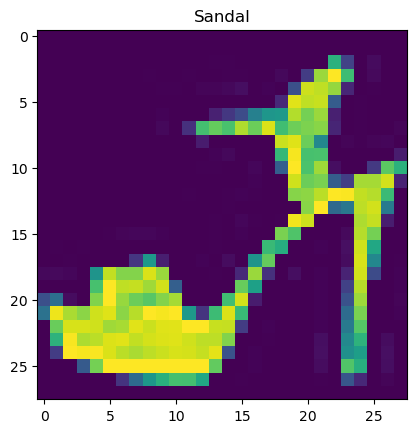

In [20]:
#how does a image look like?
plt.imshow(x_data[9])
plt.title(class_names[y_target[9]])
plt.show()

2. <b>Split</b> the official training set, stratified and seeded: 50,000 train / 10,000 validation. Save the seed and indices. Here, stratification means splitting or sampling data so that each resulting partition or subset preserves approximately the same class proportions as the source data. This is done by randomly selecting examples within each class, reducing accidental differences in class composition between partitions. For example, if each of the ten classes represents 10% of the source data, a stratified 10,000-image subset contains approximately 1,000 images per class. Stratification preserves existing proportions; it does not make an imbalanced dataset balanced. Use a fixed random seed and save the selected indices so that your splits are reproducible. For clustering, labels may be used to construct these subsets, but must not be used to compute distances, fit centroids or assign clusters. See the scikit-learn guide to stratified splitting for further explanation.
3. <b>Test set</b>: untouched until the final evaluation.
4. <b>CPU-friendly option (allowed, no penalty)</b>: fit models on a fixed stratified 10,000-image subset of the training partition; keep the same validation and test sets. Using the full 50k gives no inherent marking advantage.

In [5]:
#from sklearn.model_selection import StratifiedShuffleSplit
#import numpy as np
#TEST_SEED = 42
#the stratified splitter per documentation 
#strat_shuff_split = StratifiedShuffleSplit(n_splits=1, test_size=10000, random_state=TEST_SEED)
#targets = np.array(train_dataset.targets)
#train_index, val_index = next(strat_shuff_split.split(np.zeros(len(targets)), targets))

In [11]:
from sklearn.model_selection import train_test_split

TEST_SEED = 42
FIT_SEED = 43

all_index = np.arange(len(classes))
train_index, val_index = train_test_split(
    all_index,train_size=50_000,test_size=10_000,random_state=TEST_SEED,stratify=classes,)
fit_index, _ = train_test_split(
    train_index,train_size=10_000,random_state=FIT_SEED,stratify=classes[train_index],)

In [12]:
split_config = {
    "test_seed": TEST_SEED,
    "fit_seed": FIT_SEED,
    "train_index": train_index.tolist(),
    "val_index": val_index.tolist(),
    "fit_index":fit_index.tolist()
}
with open("configs/fashion_mnist_split_config.json", "w") as f:
    json.dump(split_config, f)

In [7]:
#check everything works as planned?!
print(f"training set size: {len(train_index)}")
print(f"validation set size: {len(val_index)}")
print(f"fit set size: {len(fit_index)}")

class_counts = pd.DataFrame(
    {
        "training set": np.bincount(classes[train_index]),
        "fitting subset": np.bincount(classes[fit_index]),
        "testing set": np.bincount(classes[val_index]),
    },
    index=pd.Index(class_names, name="Class"),
)
print(class_counts.to_string())


training set size: 50000
validation set size: 10000
fit set size: 10000
             training set  fitting subset  testing set
Class                                                 
T-shirt/top          5000            1000         1000
Trouser              5000            1000         1000
Pullover             5000            1000         1000
Dress                5000            1000         1000
Coat                 5000            1000         1000
Sandal               5000            1000         1000
Shirt                5000            1000         1000
Sneaker              5000            1000         1000
Bag                  5000            1000         1000
Ankle boot           5000            1000         1000


In [13]:
#image values are converted to float32 and divided by 255 to scale it from 0 to 
# processing the fitting subset of the training this
X_fit = images[fit_index].astype(np.float32).reshape(len(fit_index), -1) / 255.0
y_fit = classes[fit_index]

# processing the testing subset
X_val = images[val_index].astype(np.float32).reshape(len(val_index), -1) / 255.0
y_val = classes[val_index]

In [11]:
#checking if the standardization worked
print("fitting images:", X_fit.shape, X_fit.dtype)
print("fitting classes:", y_fit.shape, y_fit.dtype)
print("validation images:", X_val.shape, X_val.dtype)
print("validation classes:", y_val.shape, y_val.dtype)
print("fitting pixel range:", X_fit.min(), "to", X_fit.max())

fitting images: (10000, 784) float32
fitting classes: (10000,) int64
validation images: (10000, 784) float32
validation classes: (10000,) int64
fitting pixel range: 0.0 to 1.0


5. Clustering / feature-extraction subsets: fixed ≈3,000 train, 1,000 validation and 1,000 test images. Use exactly the same images for every representation.

In [14]:
CLUSTER_SEED = 44
cluster_train_index, _ = train_test_split(fit_index, train_size=3_000,
    random_state=CLUSTER_SEED,stratify=classes[fit_index])
cluster_val_index, _ = train_test_split(val_index, train_size=1_000,
    random_state=CLUSTER_SEED,stratify=classes[val_index])

# Taking labels from test set only to create the required stratified test subset.
# This is allowed per the coursework instructions
test_dataset = FashionMNIST(root="data",train=False,download=True,)
test_classes = test_dataset.targets.numpy()
test_index = np.arange(len(test_classes))

cluster_test_index, _ = train_test_split(test_index, train_size=1_000,
    random_state=CLUSTER_SEED,stratify=test_classes[test_index])

In [15]:
# write this as well to a seperate config file?!
cluster_config = {
    "cluster_seed": CLUSTER_SEED,
    "train_index": cluster_train_index.tolist(),
    "val_index": cluster_val_index.tolist(),
    "test_index":cluster_test_index.tolist()
}
with open("configs/fashion_mnist_cluster_config.json", "w") as f:
    json.dump(cluster_config, f)

In [11]:
print(f"Clustering train size: {len(cluster_train_index)}")      # Outputs: 3000
print(f"Clustering val size:   {len(cluster_val_index)}")        # Outputs: 1000
print(f"Clustering test size:  {len(cluster_test_index)}")  
cluster_summary = pd.DataFrame({
    "Subset": ["Training", "Validation", "Test"],
    "Images": [len(cluster_train_index),len(cluster_val_index),len(cluster_test_index),],
    "Images per class": [300, 100, 100],})

#print(cluster_summary.to_string())
print(cluster_summary.to_string(index=False))

Clustering train size: 3000
Clustering val size:   1000
Clustering test size:  1000
    Subset  Images  Images per class
  Training    3000               300
Validation    1000               100
      Test    1000               100


.  
*** <b>End of Part 0 *** </b>

In [55]:
#R3. Keep an experiment register. Per experiment: ID, question, hypothesis, changed variable, fixed conditions, split, seed, configuration, metric, result, output path. Keep informative failures.
#note: not sure if its needed for Part 0, but creating one anyway as a template for later use

register_path = Path("results/experiment_register.csv")
exp_data_setup = {
    "id": "P0-DATA_SETUP-01",
    "question": "Are the data partitions stratified, seeded and saved so they are reproducible?",
    "hypothesis": "Class proportions are preserved by stratification",
    "changed_variable": "Nothing so far",
    "fixed_conditions": "Fashion-MNIST dataset downloaded",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": " 28 x 28 float32 pixels / 0-255, flattened to 784 features",
    "metric": "set sizes, class counts, index overlap",
    "result": (
        f"Train/validation overlap = {np.intersect1d(train_index, val_index).size}; "
        f"clustering sizes={len(cluster_train_index)}/{len(cluster_val_index)}/{len(cluster_test_index)}"
    ),
    "output_path": (
        "configs/fashion_mnist_split_config.json; configs/cashion_mnist_cluster_config.json; "
    ),
}

register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_data_setup])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

.  
<b>Part 1 — Classical classification</b>

1.1 <b>Models. </b>Choose at least two classifiers or configurations from the methods taught in the module. Justify your choice for this data.  
1.2 <b>Metrics.</b> Notebook overall accuracy and a class-level view of performance, with enough information for readers to interpret any proportions.


In [11]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

In [14]:
# trying some classifiers first to learn how they all differ - this is for Logistic Regression
# To-do: I have to choose two eventually and justity
from sklearn.linear_model import LogisticRegression
register_path = Path("results/experiment_register.csv")
logreg = LogisticRegression(C=1.0, solver="lbfgs", max_iter=500)
logreg.fit(X_fit, y_fit)
fit_predict_logreg = logreg.predict(X_fit)
val_predict_logreg = logreg.predict(X_val)

print(f"Logistic Regression: fitting accuracy: {accuracy_score(y_fit, fit_predict_logreg):.2%}")
print(f"Logistic Regression: validation accuracy: {accuracy_score(y_val, val_predict_logreg):.2%}")

cm = confusion_matrix(y_val, val_predict_logreg, labels=range(len(class_names)))
recall = cm.diagonal() / cm.sum(axis=1)
hardest = recall.argmin()
print(f"Logistic Rregression: Lowest recall = {recall[hardest]:.1%} for {class_names[hardest]}")

report_lr = pd.DataFrame(classification_report(y_val, val_predict_logreg,
        labels=range(len(class_names)),target_names=class_names, output_dict=True, zero_division=0,)).T

class_level_lr = report_lr.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
class_level_lr["support"] = class_level_lr["support"].astype(int)
class_level_lr.to_csv("results/part1_2_logreg_validation_by_class.csv")
print(class_level_lr.round(3).to_string())

exp_part1_logreg = {
    "id": "P1-LOGREG-01",
    "question": "Is Logistic Regression the correct model for this dataset?",
    "hypothesis": "Highest accuracy, highest recall",
    "changed_variable": "C=1.0, solver=lbfgs, max_iter=500",
    "fixed_conditions": "None",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "C=1.0, solver=lbfgs, max_iter=500",
    "metric": "fit accuracy, validation accuracy, lowest recall",
    "result": (
        f"fit accuracy: {accuracy_score(y_fit, fit_predict_logreg):.2%}; "
        f"validation accuracy: {accuracy_score(y_val, val_predict_logreg):.2%}"
        f"lowest recall:{recall[hardest]:.1%} for {class_names[hardest]}"
    ),
    "output_path": (
        "results/part1_2_logreg_validation_by_class.csv "
    ),
}

register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_logreg])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)


Logistic Regression: fitting accuracy: 92.46%
Logistic Regression: validation accuracy: 84.08%
Logistic Rregression: Lowest recall = 59.6% for Shirt
             precision  recall  f1-score  support
T-shirt/top      0.784   0.813     0.798     1000
Trouser          0.968   0.961     0.964     1000
Pullover         0.731   0.743     0.737     1000
Dress            0.864   0.829     0.846     1000
Coat             0.727   0.741     0.734     1000
Sandal           0.931   0.924     0.928     1000
Shirt            0.616   0.596     0.606     1000
Sneaker          0.908   0.909     0.909     1000
Bag              0.947   0.940     0.943     1000
Ankle boot       0.933   0.952     0.943     1000


In [15]:
print(class_level_lr.sort_values("recall")[["recall", "support"]].to_string())

             recall  support
Shirt         0.596     1000
Coat          0.741     1000
Pullover      0.743     1000
T-shirt/top   0.813     1000
Dress         0.829     1000
Sneaker       0.909     1000
Sandal        0.924     1000
Bag           0.940     1000
Ankle boot    0.952     1000
Trouser       0.961     1000


.  
** 1.2 Observation notes **  
 - Shirt was the hardest class and Trouser was the easiest on the validation set
 - Based on stratification, Shirts included 10% of the validation images but accounted for 25.4% (404) of the model’s 1592 errors
 - Coat and Pullover were the next hardest classes, with 741 and 743 correct predictions

In [19]:
#Analysis: what did the model predict incorrectly for those 404 missed shirts?
shirt_id = class_names.index("Shirt")
missed_shirts = (y_val == shirt_id) & (val_predict_logreg != shirt_id)

wrong_labels = [class_names[pred] for pred in val_predict_logreg[missed_shirts]]
print(pd.Series(wrong_labels).value_counts().to_string())

T-shirt/top    144
Pullover       109
Coat           103
Dress           30
Bag             16
Trouser          2


In [16]:
# trying some classifiers first to learn how they all differ - this is for SVM
# To-do: I have to choose two eventually and justity
from sklearn.svm import SVC

svm = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm.fit(X_fit, y_fit)
fit_predict_svm = svm.predict(X_fit)
val_predict_svm = svm.predict(X_val)

print(f"SVM: fit accuracy: {accuracy_score(y_fit, fit_predict_svm):.2%}")
print(f"SVM: validation accuracy: {accuracy_score(y_val, val_predict_svm):.2%}")

cm = confusion_matrix(y_val, val_predict_svm, labels=range(len(class_names)))
recall = cm.diagonal() / cm.sum(axis=1)
hardest = recall.argmin()
print(f"SVM: Lowest recall = {recall[hardest]:.1%} for {class_names[hardest]}")

report_svm = pd.DataFrame(classification_report(y_val, val_predict_svm,
        labels=range(len(class_names)),target_names=class_names, output_dict=True, zero_division=0,)).T

class_level_svm = report_svm.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
class_level_svm["support"] = class_level_svm["support"].astype(int)
class_level_svm.to_csv("results/part1_2_svm_validation_by_class.csv")
print(class_level_svm.round(3).to_string())

exp_part1_svm = {
    "id": "P1-SVM-01",
    "question": "Is Support Vector Machine Classifier the correct model for this dataset?",
    "hypothesis": "Highest accuracy, highest recall",
    "changed_variable": "kernel='rbf', C=1.0, gamma='scale', random_state=42",
    "fixed_conditions": "None",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "kernel='rbf', C=1.0, gamma='scale', random_state=42",
    "metric": "fit accuracy, validation accuracy, lowest recall",
    "result": (
        f"fit accuracy: {accuracy_score(y_fit, fit_predict_svm):.2%}; "
        f"validation accuracy: {accuracy_score(y_val, val_predict_svm):.2%}"
        f"lowest recall:{recall[hardest]:.1%} for {class_names[hardest]}"
    ),
    "output_path": (
        "results/part1_2_svm_validation_by_class.csv "
    ),
}

register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_svm])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)


SVM: fit accuracy: 89.89%
SVM: validation accuracy: 86.74%
SVM: Lowest recall = 62.6% for Shirt
             precision  recall  f1-score  support
T-shirt/top      0.800   0.859     0.828     1000
Trouser          0.993   0.960     0.976     1000
Pullover         0.766   0.792     0.779     1000
Dress            0.854   0.870     0.862     1000
Coat             0.793   0.799     0.796     1000
Sandal           0.942   0.940     0.941     1000
Shirt            0.705   0.626     0.663     1000
Sneaker          0.928   0.910     0.919     1000
Bag              0.953   0.958     0.956     1000
Ankle boot       0.935   0.960     0.947     1000


In [22]:
# trying some classifiers first to learn how they all differ - this is for Random Forest
# To-do: I have to choose two eventually and justity
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_fit, y_fit)
fit_predict_rf = rf.predict(X_fit)
val_predict_rf = rf.predict(X_val)

print(f"Random Forest: fit accuracy: {accuracy_score(y_fit, fit_predict_rf):.2%}")
print(f"Random Forest: validation accuracy: {accuracy_score(y_val, val_predict_rf):.2%}")

cm = confusion_matrix(y_val, val_predict_rf, labels=range(len(class_names)))
recall = cm.diagonal() / cm.sum(axis=1)
hardest = recall.argmin()
print(f"Random Forest: Lowest recall = {recall[hardest]:.1%} for {class_names[hardest]}")

report_rf = pd.DataFrame(classification_report(y_val, val_predict_rf,
        labels=range(len(class_names)),target_names=class_names, output_dict=True, zero_division=0,)).T

class_level_rf = report_rf.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
class_level_rf["support"] = class_level_rf["support"].astype(int)
class_level_rf.to_csv("results/part1_2_rf_validation_by_class.csv")
print(class_level_rf.round(3).to_string())

exp_part1_rf = {
    "id": "P1-RF-01",
    "question": "Is Random Forest the correct model for this dataset?",
    "hypothesis": "Highest accuracy, highest recall",
    "changed_variable": "n_estimators=100, random_state=42, n_jobs=-1",
    "fixed_conditions": "None",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "n_estimators=100, random_state=42, n_jobs=-1",
    "metric": "fit accuracy, validation accuracy, lowest recall",
    "result": (
        f"fit accuracy: {accuracy_score(y_fit, fit_predict_rf):.2%}; "
        f"validation accuracy: {accuracy_score(y_val, val_predict_rf):.2%}"
        f"lowest recall:{recall[hardest]:.1%} for {class_names[hardest]}"
    ),
    "output_path": (
        "results/part1_2_rf_validation_by_class.csv "
    ),
}

register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_rf])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)


Random Forest: fit accuracy: 100.00%
Random Forest: validation accuracy: 86.10%
Random Forest: Lowest recall = 56.7% for Shirt
             precision  recall  f1-score  support
T-shirt/top      0.803   0.855     0.828     1000
Trouser          0.991   0.960     0.975     1000
Pullover         0.722   0.790     0.755     1000
Dress            0.860   0.880     0.870     1000
Coat             0.749   0.780     0.764     1000
Sandal           0.958   0.944     0.951     1000
Shirt            0.731   0.567     0.639     1000
Sneaker          0.927   0.911     0.919     1000
Bag              0.941   0.972     0.956     1000
Ankle boot       0.923   0.951     0.937     1000


In [28]:
# trying some classifiers first to learn how they all differ - this is for Decision Tree
# To-do: I have to choose two eventually and justity
from sklearn.tree import DecisionTreeClassifier

dectree = DecisionTreeClassifier(criterion="gini", max_depth=10,random_state=42,)
dectree.fit(X_fit, y_fit)
fit_predict_dectree = dectree.predict(X_fit)
val_predict_dectree = dectree.predict(X_val)

print(f"Decision Tree: fit accuracy: {accuracy_score(y_fit, fit_predict_dectree):.2%}")
print(f"Decision Tree: validation accuracy: {accuracy_score(y_val, val_predict_dectree):.2%}")

cm = confusion_matrix(y_val, val_predict_dectree, labels=range(len(class_names)))
recall = cm.diagonal() / cm.sum(axis=1)
hardest = recall.argmin()
print(f"Decision Tree: Lowest recall = {recall[hardest]:.1%} for {class_names[hardest]}")

report_dectree = pd.DataFrame(classification_report(y_val, val_predict_dectree,
        labels=range(len(class_names)),target_names=class_names, output_dict=True, zero_division=0,)).T

class_level_dectree = report_dectree.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
class_level_dectree["support"] = class_level_dectree["support"].astype(int)
class_level_dectree.to_csv("results/part1_2_dectree_validation_by_class.csv")
print(class_level_dectree.round(3).to_string())

exp_part1_dectree = {
    "id": "P1-DECTREE-01",
    "question": "Is Decision Tree the correct model for this dataset?",
    "hypothesis": "Highest accuracy, highest recall",
    "changed_variable": "criterion=gini, max_depth=10,random_state=42,",
    "fixed_conditions": "None",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "criterion=gini, max_depth=10,random_state=42,",
    "metric": "fit accuracy, validation accuracy, lowest recall",
    "result": (
        f"fit accuracy: {accuracy_score(y_fit, fit_predict_dectree):.2%}; "
        f"validation accuracy: {accuracy_score(y_val, val_predict_dectree):.2%}"
        f"lowest recall:{recall[hardest]:.1%} for {class_names[hardest]}"
    ),
    "output_path": (
        "results/part1_2_dectree_validation_by_class.csv "
    ),
}

register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_dectree])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)


Decision Tree: fit accuracy: 87.37%
Decision Tree: validation accuracy: 77.82%
Decision Tree: Lowest recall = 45.1% for Shirt
             precision  recall  f1-score  support
T-shirt/top      0.778   0.768     0.773     1000
Trouser          0.953   0.939     0.946     1000
Pullover         0.649   0.653     0.651     1000
Dress            0.791   0.794     0.792     1000
Coat             0.588   0.729     0.651     1000
Sandal           0.887   0.848     0.867     1000
Shirt            0.545   0.451     0.494     1000
Sneaker          0.834   0.847     0.841     1000
Bag              0.897   0.875     0.886     1000
Ankle boot       0.875   0.878     0.876     1000


1.3 <b>Error analysis</b>. Inspect a small set of correct and incorrect predictions. Discuss easy and hard classes.
* Which classes does each model recognise most and least often?
* What do their mistakes look like on the same images?



In [50]:
#this is to compare all models to find mistakes that all of them make and see if there is a pattern
for model_name, predictions in [
    ("Logistic regression", val_predict_logreg),
    ("SVM",val_predict_svm),
    ("Random Forest", val_predict_rf),
    ("Decision tree", val_predict_dectree),]:
    cm = confusion_matrix(y_val, predictions, labels=range(len(class_names)))
    recall = cm.diagonal() / cm.sum(axis=1)
    hardest = recall.argmin()
    errors = cm[hardest].copy()
    errors[hardest] = 0
    confused_with = errors.argmax()
    print(f"{model_name}: From {cm[hardest].sum()} actual images of {class_names[hardest]}, {errors[confused_with]} were predicted as {class_names[confused_with]}.")


Logistic regression: recall = 59.6% for Shirt
Logistic regression: From 1000 actual images of Shirt, 144 were predicted as T-shirt/top.
SVM: recall = 62.6% for Shirt
SVM: From 1000 actual images of Shirt, 156 were predicted as T-shirt/top.
Random Forest: recall = 56.7% for Shirt
Random Forest: From 1000 actual images of Shirt, 166 were predicted as T-shirt/top.
Decision tree: recall = 45.1% for Shirt
Decision tree: From 1000 actual images of Shirt, 184 were predicted as Coat.


.  
*** 1.3 Observations (more like questions to find answer) from the above experiments: ***
1. Training set accuracy for Random Forest is 100%. Is it overfiting? The short recall is low as well?
2. Decision tre has the lowest recall, lowest accuracy rate and struggles more with shirts, should we drop it?
3. All other models confused the shirt with t-shirt/top but decision tree confused with coat. It seems to identify the pattern correctly but strugggles on the brightness of the pixel?
4. Why does Shirt have the lowest recall while pullover and coat look the same?
5. Logistic regression had least mis-predictions of shirt but why is its recall is low compared to SVM?
6. Does highest recall (63.6%) alone is sufficient factor to pick SVM?

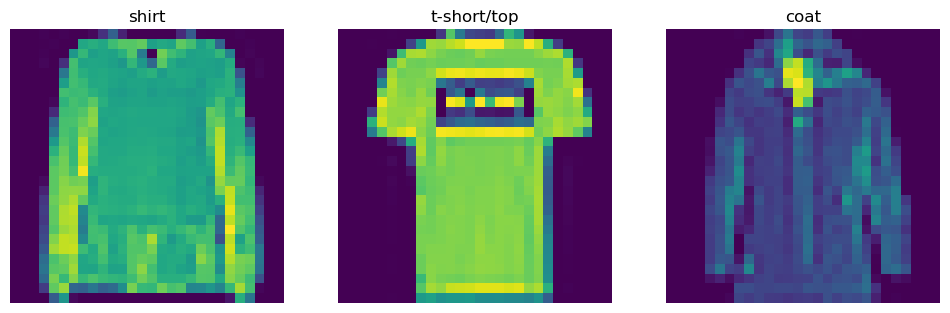

In [49]:
#Analysis: why are three of the classifers mostly strugging with short vs T-short/top?!!
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

#for shirt
shirt_index = np.where(labels == 6)[0][0]
shirt_img = images[shirt_index]
axes[0].imshow(shirt_img)
axes[0].set_title("shirt")
axes[0].axis('off')

# for t-shirt/top
t_shirt_index = np.where(labels == 0)[0][0]
t_shirt_img = images[t_shirt_index]
axes[1].imshow(t_shirt_img)
axes[1].set_title("t-short/top")
axes[1].axis('off')

# for coat
coat_index = np.where(labels == 4)[0][0]
coat_img = images[coat_index]
axes[2].imshow(coat_img)
axes[2].set_title("coat")
axes[2].axis('off')

plt.show()

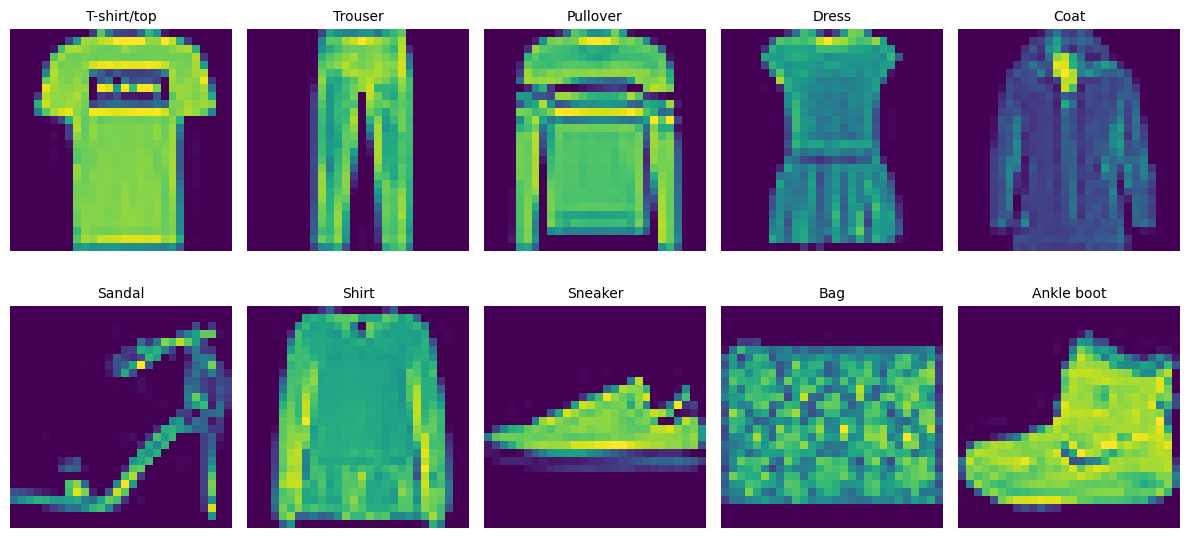

In [47]:
#Visualizing all images to assist in selecting the final choice of models
#dictionary to hold one index per class
class_indices = {}
# finding one example for every class
for index, label in enumerate(train_dataset.targets):
    label_item = label.item() if hasattr(label, 'item') else int(label)
    if label_item not in class_indices:
        class_indices[label_item] = index
    if len(class_indices) == 10:
        break

# 2x5 grid plot
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
axes = axes.flatten()

# Plot each class example
for i in range(10):
    img_index= class_indices[i]
    img, label = train_dataset[img_index]
    img_array = np.array(img)
    axes[i].imshow(img_array)
#    axes[i].imshow(img_array, cmap='gray')
    axes[i].set_title(train_dataset.classes[i], fontsize=10)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

All correct: 7000 validation images
Only LR correct: 184 validation images
Only decision tree correct: 156 validation images
Only RF correct: 95 validation images
Only SVM correct: 65 validation images
All wrong: 646 validation images


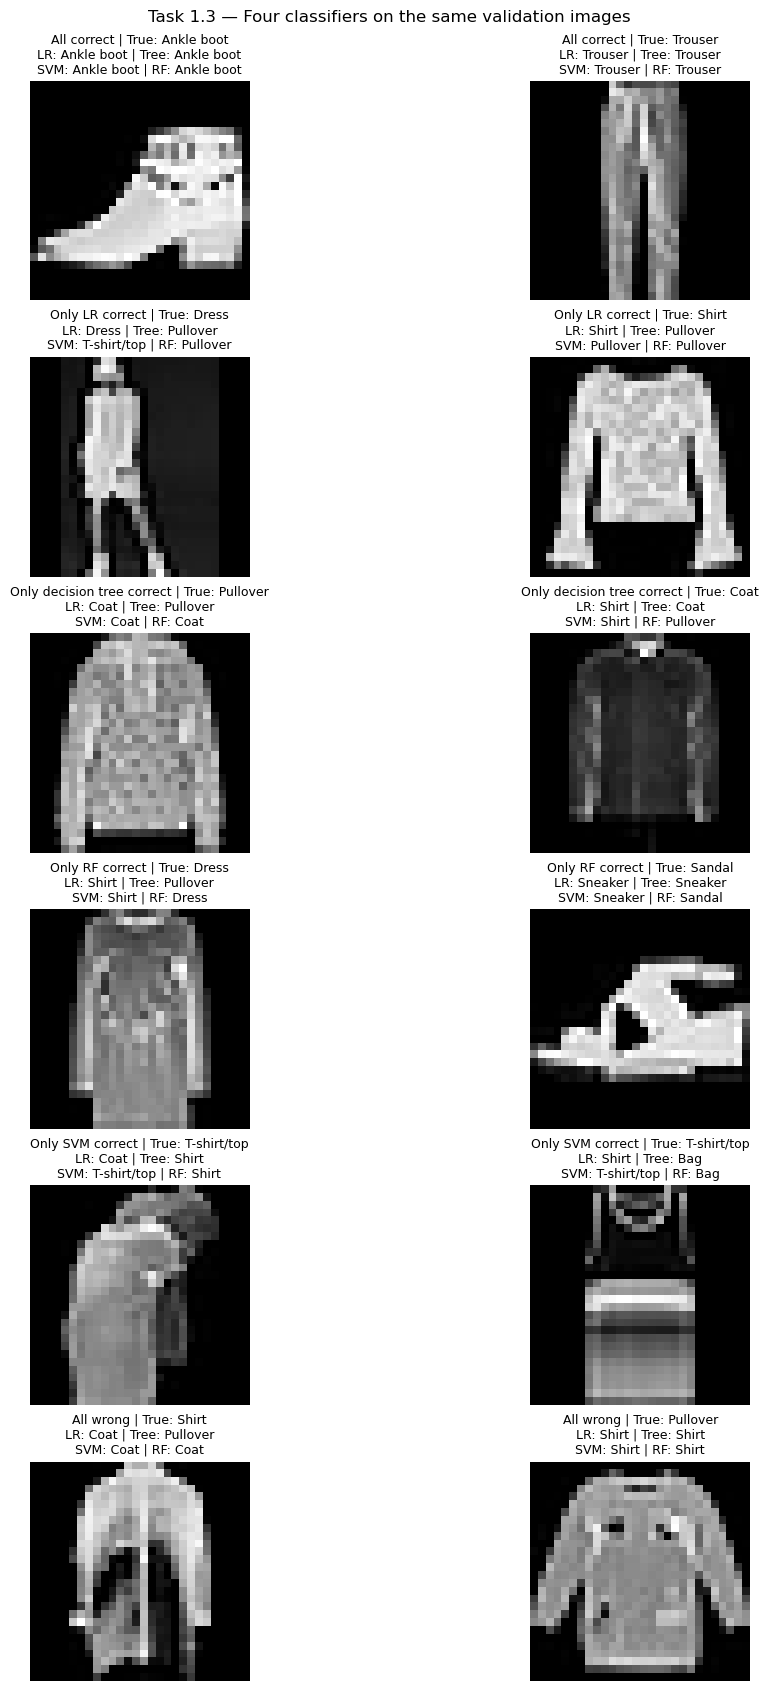

In [45]:
logreg_correct = val_predict_logreg == y_val
dectree_correct = val_predict_dectree == y_val
rf_correct = val_predict_rf == y_val
svm_correct = val_predict_svm == y_val

groups = [
    ("All correct", logreg_correct & dectree_correct & rf_correct & svm_correct),
    ("Only LR correct", logreg_correct & ~dectree_correct & ~rf_correct & ~svm_correct),
    ("Only decision tree correct", ~logreg_correct & dectree_correct & ~rf_correct & ~svm_correct),
    ("Only RF correct", ~logreg_correct & ~dectree_correct & rf_correct & ~svm_correct),
    ("Only SVM correct", ~logreg_correct & ~dectree_correct & ~rf_correct & svm_correct),
    ("All wrong", ~logreg_correct & ~dectree_correct & ~rf_correct & ~svm_correct),
]

rng = np.random.default_rng(42)
fig, axes = plt.subplots(len(groups), 2, figsize=(10, 2.8 * len(groups)), layout="constrained")

for row, (outcome, mask) in enumerate(groups):
    positions = np.flatnonzero(mask)
    chosen = rng.choice(positions, size=min(2, len(positions)), replace=False)
    print(f"{outcome}: {len(positions)} validation images")

    for ax in axes[row]:
        ax.axis("off")

    if len(positions) == 0:
        axes[row, 0].set_title(f"{outcome} | 0 examples")

    for ax, pos in zip(axes[row], chosen):
        #ax.imshow(images[val_index[pos]], vmin=0, vmax=255)
        # (note: TDS said gray scale is better for comparison)
        ax.imshow(images[val_index[pos]], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{outcome} | True: {class_names[y_val[pos]]}\n"
            f"LR: {class_names[val_predict_logreg[pos]]} | Tree: {class_names[val_predict_dectree[pos]]}\n"
            f"SVM: {class_names[val_predict_svm[pos]]} | RF: {class_names[val_predict_rf[pos]]}",
            fontsize=9,)

fig.suptitle("Task 1.3 — Four classifiers on the same validation images")
fig.savefig("figures/part1_3_error_examples_4_classifiers.png", dpi=150, bbox_inches="tight")
plt.show()

.  
**** 1.3 observations from the above visualizations ***
* There seems to be significant data quality issues. Labels seems to be wrong in many cases. Models like Decision Tree will not perform well with poor data quality
* Ankle Boot and Trouser are the easiest of all classes for all 4 classifers. Next is Sandal
* Decision Tree predicts Coat better because it focuses on the pixel brightness and Coat images mostly seem to be light on brightness
* Shirt is the hardest for all classes. Shirts seem to be characterized with mostly flat top, raised slightly on the shoulders and mostly longer images. Although there are some variations where they are short.
* Training set accuracy for Random Forest is 100%. Is it probably overfiting.
* Decision tree has the lowest recall, lowest accuracy rate and struggles more with Shirts.
* When hands are longer than the body in a shirt, most classifiers are predicting it as a pullover where only Logistic Regression seems to identigy them correctly as shirt
* When shirts are short or does not have flat surface, Logistic Regression identifies them as T-Shirt/Top while SVM identifies them correctly.
* SVM recognised the most shirts, while logistic regression made fewer of the specific Shirt to T-shirt/top mistakes
*  SVM recognised 30 more shirts overall, even though it called 12 more shirts T-shirt/top. It also made 42 fewer errors involving the other classes
*  Logistic Regression (59.6%) and SVM (62.6%) also had higher Shirt recall than the random forest (56.7%) and decision tree (45.1%).

In [43]:
#starting to pivot towards Logistic Regression and SVM based on above analysis
#so checking when and how SVM predicts correctly
from sklearn.metrics import precision_recall_fscore_support
shirt_id = class_names.index("Shirt")
rows = []

for name, pred in [("Logistic Regression", val_predict_logreg), ("SVM", val_predict_svm)]:
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val == shirt_id, pred == shirt_id, average="binary", zero_division=0
    )
    false_positives = ((pred == shirt_id) & (y_val != shirt_id)).sum()
    rows.append([name, precision, recall, f1, false_positives])

print(pd.DataFrame(
    rows, columns=["Model", "Shirt precision", "Shirt recall", "Shirt F1", "False positives"]
).round(3).to_string(index=False))

              Model  Shirt precision  Shirt recall  Shirt F1  False positives
Logistic Regression            0.616         0.596     0.606              372
                SVM            0.705         0.626     0.663              262


SVM correctly recognised 32 of these 144 shirts that LR missed.


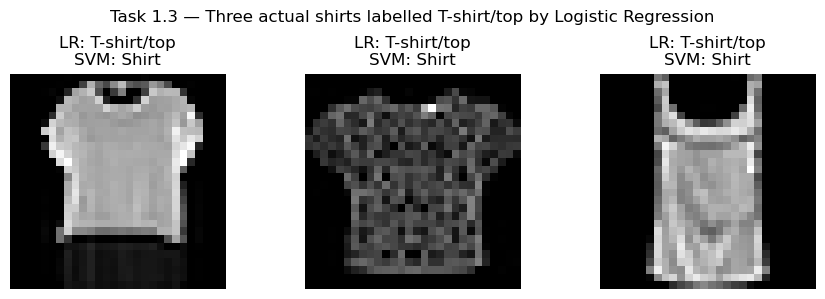

In [46]:
#visualizing to see what features of images SVM predicts correctly
shirt_id = class_names.index("Shirt")
top_id = class_names.index("T-shirt/top")

# Positions in the validation set where LR called a true shirt a T-shirt/top.
positions = np.flatnonzero((y_val == shirt_id) & (val_predict_logreg == top_id))

svm_correct = np.sum(val_predict_svm[positions] == shirt_id)
print(f"SVM correctly recognised {svm_correct} of these {len(positions)} shirts that LR missed.")

svm_positions = np.flatnonzero((y_val == shirt_id) & (val_predict_logreg == top_id) & (val_predict_svm == shirt_id))
chosen = np.random.default_rng(42).choice(svm_positions, size=3, replace=False)
fig, axes = plt.subplots(1, 3, figsize=(9, 3))

for ax, pos in zip(axes, chosen):
    ax.imshow(images[val_index[pos]], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"LR: T-shirt/top\nSVM: {class_names[val_predict_svm[pos]]}")
    ax.axis("off")

fig.suptitle("Task 1.3 — Three actual shirts labelled T-shirt/top by Logistic Regression")
fig.tight_layout()
fig.savefig("figures/part1_3_shirt_errors_svm.png", dpi=150, bbox_inches="tight")
plt.show()

.  
** 1.3 observation notes **
* There seems to be data quality issues. These seems to be T-shirt/top which LR seem to predict correctly but they are labelled as Shirts

1.4 <b>Complexity study</b>. Vary parameters that control model complexity and explain how model complexity affects generalization.

 gamma_factor  gamma  train_accuracy  val_accuracy
         0.25 0.0026          0.8451        0.8389
         1.00 0.0102          0.8989        0.8674
         4.00 0.0410          0.9628        0.8737


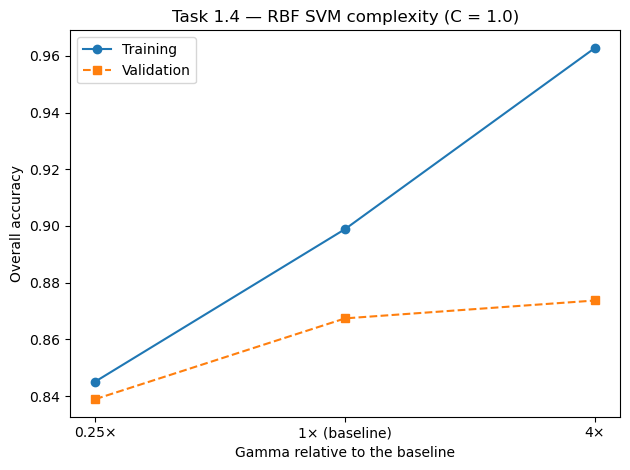

In [17]:
#to-do:
from sklearn.base import clone

gamma_base = 1.0 / (X_fit.shape[1] * X_fit.var(dtype="float64"))
rows = []

for factor in [0.25, 1.0, 4.0]:
    gamma_value = factor * gamma_base
 
    fitted_svm = clone(svm).set_params(gamma=gamma_value)
    fitted_svm.fit(X_fit, y_fit)

    rows.append({
        "gamma_factor": factor,
        "gamma": gamma_value,
        "train_accuracy": fitted_svm.score(X_fit, y_fit),
        "val_accuracy": fitted_svm.score(X_val, y_val),})

gamma_results = pd.DataFrame(rows)
gamma_results.to_csv("results/part1_4_svm_gamma_study.csv", index=False)
print(gamma_results.round(4).to_string(index=False))

ax = gamma_results.plot(x="gamma_factor", y="train_accuracy", marker="o", label="Training")
gamma_results.plot(
    x="gamma_factor", y="val_accuracy", marker="s",
    linestyle="--", label="Validation", ax=ax)
ax.set_xscale("log", base=2)
ax.set_xticks([0.25, 1, 4], labels=["0.25×", "1× (baseline)", "4×"])
ax.set_xlabel("Gamma relative to the baseline")
ax.set_ylabel("Overall accuracy")
ax.set_title("Task 1.4 — RBF SVM complexity (C = 1.0)")
ax.figure.tight_layout()
ax.figure.savefig("figures/part1_4_svm_gamma_study.png", dpi=150)
plt.show()

.  
** 1.4 Observation Notes **
* Going from 0.25× to 1× improved validation accuracy by 2.85 percentage. Going from 1× to 4× added only 0.63 percentage on validation, while training accuracy went up by 6.39%.
* So with still keeping C=1.0 fixed, making the SVM boundary more local helped on validation images.
* The 4× gamma setting performed best on validation at 87.37%.
* This is 0.63% more than baseline. So compared with the baseline, it correctly classified 63 more of the 10,000 validation images
* But the larger gain was on the training set (96.28%)

In [18]:
svm_selected = fitted_svm

In [52]:
baseline = gamma_results.loc[gamma_results["gamma_factor"] == 1.0].iloc[0]
best = gamma_results.loc[gamma_results["val_accuracy"].idxmax()]

val_gain_pp = 100 * (best["val_accuracy"] - baseline["val_accuracy"])

result = (
    f"Best of {len(gamma_results)} gamma settings by validation accuracy: "
    f"{best['gamma_factor']:g}× baseline (gamma={best['gamma']:.4f}, C=1.0). "
    f"Training accuracy {best['train_accuracy']:.2%}; "
    f"validation accuracy {best['val_accuracy']:.2%} "
    f"({val_gain_pp:+.2f} percentage points vs baseline)."
)
print(result)

exp_part1_svm_gamma = {
    "id": "P1-4_SVM_GAMMA-01",
    "question": "Does the change in gamma to the more local decision boundary improve validation accuracy, or does the benefit appear mainly on the training set?",
    "hypothesis": "For higher gamma, highest overall accuracy training set and highest overall accuracy  validation set",
    "changed_variable": "gamma = 0.25, 1.0 (scale), 4.0",
    "fixed_conditions": "C=1.0",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "kernel='rbf', C=1.0, gamma=varied, random_state=42",
    "metric": "overall training accuracy, overall validation accuracy",
    "result": {result},
    "output_path": ("results/part1_4_svm_gamma_study.csv; figures/part1_4_svm_gamma_study.png "),
}
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_svm_gamma])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

Best of 3 gamma settings by validation accuracy: 4× baseline (gamma=0.0410, C=1.0). Training accuracy 96.28%; validation accuracy 87.37% (+0.63 percentage points vs baseline).


/opt/conda/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


    C  train_accuracy  val_accuracy   gap
 0.01          0.8416        0.8374  0.42
 0.10          0.8865        0.8506  3.59
 1.00          0.9246        0.8408  8.38
10.00          0.9503        0.8162 13.41


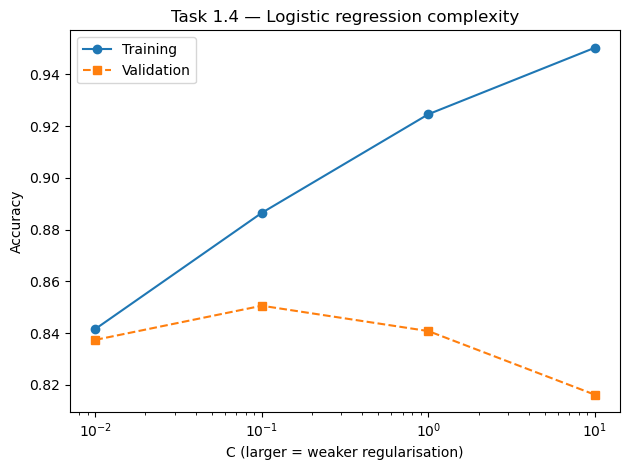

In [55]:
logreg_rows = []
for c_value in [0.01, 0.1, 1.0, 10.0]:
    if c_value == 1.0:
        fitted_logreg = logreg  # reusing the already fitted model earlier (todo: do the same for SVM above later)
    else:
        fitted_logreg = clone(logreg).set_params(C=c_value)
        fitted_logreg.fit(X_fit, y_fit)
    training_accuracy = fitted_logreg.score(X_fit, y_fit)
    validation_accuracy = fitted_logreg.score(X_val, y_val)
    logreg_rows.append({
        "C": c_value,
        "train_accuracy": training_accuracy,
        "val_accuracy": validation_accuracy,
        "gap": 100 * (training_accuracy - validation_accuracy),})

cvalue_results = pd.DataFrame(logreg_rows)
cvalue_results.to_csv("results/part1_4_logreg_cvalue_study.csv", index=False)
print(cvalue_results.round(4).to_string(index=False))

ax = cvalue_results.plot(x="C", y="train_accuracy", marker="o", label="Training", logx=True)
cvalue_results.plot(x="C", y="val_accuracy", marker="s", linestyle="--", label="Validation", ax=ax)
ax.set(xlabel="C (larger = weaker regularisation)", ylabel="Accuracy",
       title="Task 1.4 — Logistic regression complexity")
ax.figure.tight_layout()
ax.figure.savefig("figures/part1_4_logreg_cvalye_study.png", dpi=150)
plt.show()


.  
** 1.4 Analysis / observation from above **
* 0.1 has the highest validation accuracy of 85.06%
* But one of the fit reached 500 iterations set as max before the stopping condition could be met. It has provided a prediction but I need to rerun with higher limit to see if the outcome changes.

In [56]:
exp_part1_logreg_cvalue = {
    "id": "P1-4_LOGREG_CVALUE-01",
    "question": "Does weaker regularisation overfit the training data at a cost to generalisation?",
    "hypothesis": "Larger C improves training accuracy while validation accuracy falls",
    "changed_variable": "C = 0.01, 0.1, 1.0, 10.0",
    "fixed_conditions": "solver=lbfgs, max_iter=500",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "solver=lbfgs, max_iter=500",
    "metric": "training accuracy, validation accuracy",
    "result": "C=0.1 has the highest validation accuracy of 85.06% but one of the fit reached max iteration",
    "output_path": ("results/part1_4_logreg_cvalue_study.csv; figures/part1_4_logreg_cvalye_study.png"),
}
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_logreg_cvalue])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

    C  iterations  converged  train_accuracy  val_accuracy   gap
 0.01         177       True          0.8416        0.8374  0.42
 0.10         242       True          0.8865        0.8506  3.59
 1.00         405       True          0.9246        0.8408  8.38
10.00         812       True          0.9556        0.8160 13.96


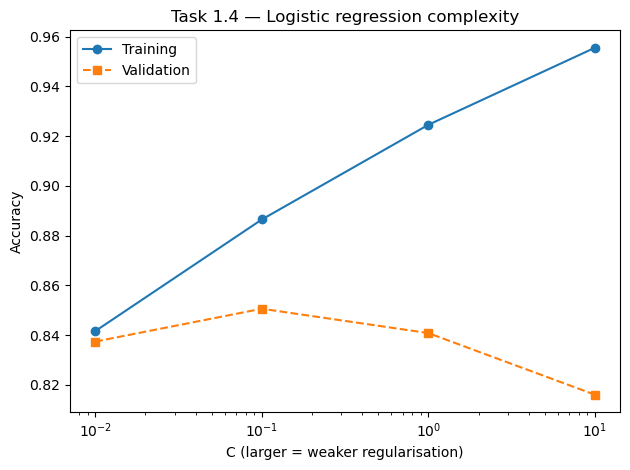

In [19]:
import warnings
from sklearn.exceptions import ConvergenceWarning
logreg_rows = []
logreg_models = {}

for c_value in [0.01, 0.1, 1.0, 10.0]:
    fitted_logreg = clone(logreg).set_params(C=c_value, max_iter=2000)

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        fitted_logreg.fit(X_fit, y_fit)

    converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
    train_accuracy = fitted_logreg.score(X_fit, y_fit)
    val_accuracy = fitted_logreg.score(X_val, y_val)

    logreg_models[c_value] = fitted_logreg
    logreg_rows.append({
        "C": c_value,
        "iterations": fitted_logreg.n_iter_.max(),
        "converged": converged,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "gap": 100 * (train_accuracy - val_accuracy),})

cvalue_results = pd.DataFrame(logreg_rows)
cvalue_results.to_csv("results/part1_4_logreg_cvalue_iter2000_study.csv", index=False)
print(cvalue_results.round(4).to_string(index=False))

ax = cvalue_results.plot(x="C", y="train_accuracy", marker="o", label="Training", logx=True)
cvalue_results.plot(x="C", y="val_accuracy", marker="s", linestyle="--", label="Validation", ax=ax)
ax.set(xlabel="C (larger = weaker regularisation)", ylabel="Accuracy",
       title="Task 1.4 — Logistic regression complexity")
ax.figure.tight_layout()
ax.figure.savefig("figures/part1_4_logreg_cvalue_iter2000_study.png", dpi=150)
plt.show()



.  
** 1.4 Observation Notes **
* All four converged this time and still C=0.1 achieved the highest validation accuracy of the four settings: 85.06%.
* The C=10 fit needed 812 iterations and hence caused the warning last time.
* Increasing C from 0.01 to 0.1 improved validation accuracy from 83.74% to 85.06%. Increasing it further to 10 raised training accuracy from 88.65% to 95.56%, while validation accuracy fell to 81.60%.
* This is evidence of overfitting at the higher setting: the model fitted the training images better and made more errors on held-out images

In [20]:
best_logreg_row = cvalue_results.loc[cvalue_results["val_accuracy"].idxmax()]
logreg_selected = logreg_models[best_logreg_row["C"]]

In [60]:
exp_part1_logreg_cvalue_2 = {
    "id": "P1-4_LOGREG_CVALUE-02",
    "question": "Does increasing the max iteration converge all the C value fits?",
    "hypothesis": "All C fits coverage to identify the best C value",
    "changed_variable": "C = 0.01, 0.1, 1.0, 10.0 and max_iter=2000",
    "fixed_conditions": "solver=lbfgs",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "solver=lbfgs",
    "metric": "training accuracy, validation accuracy",
    "result": "All four fits converged. But C=0.1 still has the highest validation accuracy of 85.06%",
    "output_path": ("results/part1_4_logreg_cvalue_iter2000_study.csv; figures/part1_4_logreg_cvalue_iter2000_study.png.png"),
}
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_logreg_cvalue_2])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)


1.5 <b>Decisions and costs </b> Define a binary decision problem of your own, derived from the ten classes. Using validation data, show how the decision threshold trades one error against the other.

binary decision problem --> When a user searches for "Footwear" in the catalogue, Should a given item appear under the catalogue’s Footwear filter?
* This mus tbe 3,000 footwear items and 7,000 other items in the validation set of 10,000 items
* If the catalogue allows atmost 1% of non-footwear items into the results, then that allows 70 false positives and maximum number of Footwear recovered.

In [28]:
#to-do:
from sklearn.metrics import roc_curve

footwear_ids = [class_names.index(c) for c in ["Sandal", "Sneaker", "Ankle boot"]]
is_footwear = np.isin(y_val, footwear_ids)

logreg_cols = np.isin(logreg_selected.classes_, footwear_ids)
svm_cols = np.isin(svm_selected.classes_, footwear_ids)

footwear_scores = {
    "Logistic regression": logreg_selected.predict_proba(X_val)[:, logreg_cols].sum(axis=1),
    "RBF SVM": svm_selected.decision_function(X_val)[:, svm_cols].max(axis=1),}

n_positive = int(is_footwear.sum())
n_negative = int((~is_footwear).sum())
rows = []

for model_name, scores in footwear_scores.items():
    fpr, recall, thresholds = roc_curve(is_footwear, scores, drop_intermediate=False)

    curve = pd.DataFrame({
        "threshold": thresholds,
        "FP": np.rint(fpr * n_negative).astype(int),
        "FN": n_positive - np.rint(recall * n_positive).astype(int),
        "footwear_recall": recall,})

    for budget in [35, 70, 140]:
        eligible = curve.loc[curve["FP"] <= budget]
        best = eligible.sort_values(["FN", "FP"]).iloc[0]
        rows.append({
            "model": model_name,
            "FP_budget": budget,
            "threshold": best["threshold"],
            "FP": int(best["FP"]),
            "FN": int(best["FN"]),
            "footwear_recall": best["footwear_recall"],
        })

footwear_results = pd.DataFrame(rows)
footwear_results.to_csv("results/part1_5_footwear_thresholds.csv", index=False)
print(footwear_results.round(4).to_string(index=False))

              model  FP_budget  threshold  FP  FN  footwear_recall
Logistic regression         35     0.3468  35   7           0.9977
Logistic regression         70     0.1799  70   2           0.9993
Logistic regression        140     0.1527  78   1           0.9997
            RBF SVM         35     8.2951  19   6           0.9980
            RBF SVM         70     8.2691  63   3           0.9990
            RBF SVM        140     8.2484 111   1           0.9997


.  
** 1.5 Observation Notes **
* Comparing relaxed thersholds 35 and 140 (i.e, 0.5% and 2%) within the model, the drop in FN shows extra shoes the relaxed threshold recovered. The rise in FP shows  the actual cost in showing irrelevant non-Footwear items.
* Comparing the strict threshold (1%) across the two models: Logistic regression had 1 less shirt missed however it included 7 more irrelevant non-Footwear items

** <b> End of Part-1 </b>

** <b>Part 2 — Neural networks: architecture and learning </b>
Guiding question: How do network design and training choices affect what is learned?

2.1 Baseline MLP (trained from scratch)
Design and train a feed-forward MLP from scratch as your baseline, and justify your design choices. Document everything needed to reproduce it (architecture, loss, optimisation settings, checkpoint rule, initialisation and seed) and Notebook its trainable parameter count.

Autodiff is allowed, but your code must clearly expose the model, loss, gradient update, training loop and validation loop, and you must be able to explain how the network computes its predictions and how gradients are used to update its parameters.

.  
**** 2.1 Baseline MLP design choices - Starting Settings ****
* Architecture - 784 (input) -> 64 nodes (one hidden layer) -> 10 (output). One hidden layer keeps the prediction calculation easy to start and compare later, I'll do a almost equivalent two layer architecture to compare later.
* Activation - ReLU after the hidden layer. It lets the model learn nonlinear relationships between pixels.
* Loss - Cross-entropy on the ten output scores. It rewards assigning a high score to the correct class relative to the others.
* Optimiser - Mini-batch SGD, learning rate 0.05, batch size 128, momentum 0, weight decay 0. SGD makes the gradient update easy to explain.
* Training budget - 25 epochs.
* Initialisation - Fresh Xavier-uniform weights, zero biases, model seed 42. A separate seeded generator controls the order of training images.
* Checkpoint - Saving the first epoch with the lowest validation cross-entropy. This gives every run the same selection rule.

In [32]:
#define the model and training procedure
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

results_dir = Path("results/part2")
results_dir.mkdir(parents=True, exist_ok=True)

train_data = TensorDataset(torch.as_tensor(X_fit, dtype=torch.float32),
    torch.as_tensor(y_fit, dtype=torch.long),)
val_data = TensorDataset(torch.as_tensor(X_val, dtype=torch.float32),
    torch.as_tensor(y_val, dtype=torch.long),)

class FashionMLP(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.hidden = nn.Linear(784, width)
        self.output = nn.Linear(width, 10)

        for layer in (self.hidden, self.output):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward(self, pixels):
        features = torch.relu(self.hidden(pixels))
        return self.output(features)


def train_mlp(run_id, width=64, lr=0.05, seed=42, epochs=25):
    torch.manual_seed(seed)
    model = FashionMLP(width).to(device)

    # Reset this generator for each run so the mini-batches match across runs.
    order = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_data, batch_size=128, shuffle=True,generator=order)
    val_loader = DataLoader(val_data, batch_size=128, shuffle=False)

    loss_fn = nn.CrossEntropyLoss()
    optimiser = torch.optim.SGD(model.parameters(), lr=lr,momentum=0.0, weight_decay=0.0)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    checkpoint = results_dir / f"{run_id}.pt"
    best_val_loss = float("inf")
    history = []

    for epoch in range(1, epochs + 1):
        model.train()
        train_loss_sum = train_correct = 0

        for pixels, labels_batch in train_loader:
            pixels, labels_batch = pixels.to(device), labels_batch.to(device)

            optimiser.zero_grad()                # Clear the previous batch's gradients.
            logits = model(pixels)               # Compute ten scores per image.
            loss = loss_fn(logits, labels_batch)
            loss.backward()                      # Compute gradients by backpropagation.
            optimiser.step()                     # SGD updates each weight: w ← w − lr × gradient.

            train_loss_sum += loss.item() * len(labels_batch)
            train_correct += (logits.argmax(1) == labels_batch).sum().item()

        model.eval()
        val_loss_sum = val_correct = 0

        with torch.no_grad():
            for pixels, labels_batch in val_loader:
                pixels, labels_batch = pixels.to(device), labels_batch.to(device)
                logits = model(pixels)
                loss = loss_fn(logits, labels_batch)
                val_loss_sum += loss.item() * len(labels_batch)
                val_correct += (logits.argmax(1) == labels_batch).sum().item()

        val_loss = val_loss_sum / len(val_data)
        history.append({
            "run": run_id, "epoch": epoch, "width": width, "lr": lr,
            "seed": seed, "parameters": n_params,
            "train_loss": train_loss_sum / len(train_data),
            "val_loss": val_loss,
            "train_acc": train_correct / len(train_data),
            "val_acc": val_correct / len(val_data),})

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save({
                "width": width, "epoch": epoch, "lr": lr, "seed": seed,
                "model_state": model.state_dict(),
            }, checkpoint)

    history = pd.DataFrame(history)
    history.to_csv(results_dir / f"{run_id}_history.csv", index=False)
    return history

Training device: cuda


[HAMI-core Msg(112:140671542881600:libvgpu.c:855)]: Initialized


In [16]:
#runing the baseline architecture with one hidden layer of 64 nodes
from time import perf_counter

start = perf_counter()
baseline = train_mlp("P2-baseline64")
print(f"Baseline training time: {perf_counter() - start:.1f} seconds")

best = baseline.loc[baseline["val_loss"].idxmin()]

exp_part2_1_baseline = {
    "id": "P2_1-BASELINE-01",
     "question": "How well does a single-hidden-layer MLP perform in a fixed training recipe?",
    "hypothesis": "Training and validation performance will improve as the MLP learns.",
    "changed_variable": "None; baseline configuration",
    "fixed_conditions": (
        "784 features; Xavier-uniform weights; zero biases; "
        "cross-entropy; first minimum-validation-loss checkpoint"),
    "split": "10,000 fitting images; 10,000 validation images",
    "seed": "Model initialisation=42; training shuffle generator=42",
    "configuration": (
        "Architecture=784-64-10; hidden activation=ReLU; parameters=50890; "
        "optimiser=SGD; learning_rate=0.05; batch_size=128; epochs=25; "
        "momentum=0; weight_decay=0"),
    "metric": "Per-epoch cross-entropy and accuracy on training and validation",
    "result": (
        f"Best epoch={int(best['epoch'])}; "
        f"parameters={int(best['parameters'])}; "
        f"training_loss={best['train_loss']:.6f}; "
        f"validation_loss={best['val_loss']:.6f}; "
        f"training_accuracy={best['train_acc']:.2%}; "
        f"validation_accuracy={best['val_acc']:.2%}"),
    "output_path": (
        "results/part2/P2-baseline64_history.csv; "
        "results/part2/P2-baseline64.pt"),
}

register_path = Path("results/experiment_register.csv")
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part2_1_baseline])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

print(exp_part2_1_baseline["result"])


Baseline training time: 6.7 seconds
Best epoch=22; parameters=50890; training_loss=0.408506; validation_loss=0.436975; training_accuracy=85.83%; validation_accuracy=84.50%


.  
**** 2.2 Capacity ***
* Hidden widths - 32, baseline, 256, all at lr=0.05	Does giving the model more learned features improve training fit, and does that improvement carry over to validation?

 width  parameters  epoch  train_loss  val_loss  train_acc  val_acc
    32       25450     22      0.4277    0.4506     0.8508   0.8404
    64       50890     22      0.4085    0.4370     0.8583   0.8450
   256      203530     22      0.3937    0.4255     0.8654   0.8497


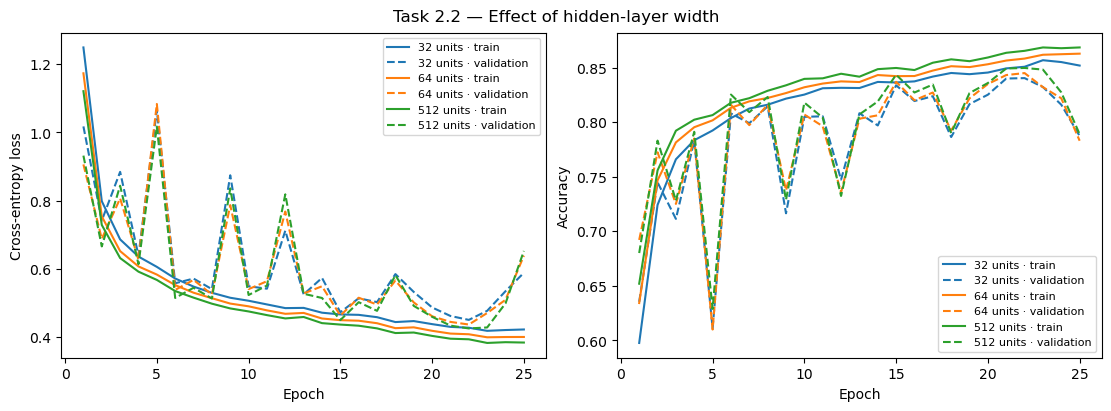

width=32, parameters=25450, selected_epoch=22, training_loss=0.427650, validation_loss=0.450575, training_accuracy=85.08%, validation_accuracy=84.04% | width=64, parameters=50890, selected_epoch=22, training_loss=0.408506, validation_loss=0.436975, training_accuracy=85.83%, validation_accuracy=84.50% | width=256, parameters=203530, selected_epoch=22, training_loss=0.393743, validation_loss=0.425524, training_accuracy=86.54%, validation_accuracy=84.97%


In [17]:
# 2.2 — Capacity: vary only the hidden-layer width.
capacity_runs = {
    32: train_mlp("P2-width32", width=32),
    64: baseline,
    512: train_mlp("P2-width256", width=256),
}

# Compare each width at its lowest-validation-loss checkpoint.
capacity_summary = pd.DataFrame([
    history.loc[history["val_loss"].idxmin()]
    for history in capacity_runs.values()
])[["width", "parameters", "epoch", "train_loss", "val_loss", "train_acc", "val_acc"]]

capacity_summary.to_csv(results_dir / "2.2_capacity_summary.csv", index=False)
print(capacity_summary.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for width, history in capacity_runs.items():
    for ax, metric in zip(axes, ["loss", "acc"]):
        line, = ax.plot(history["epoch"], history[f"train_{metric}"],
                        label=f"{width} units · train")
        ax.plot(history["epoch"], history[f"val_{metric}"], "--",
                color=line.get_color(), label=f"{width} units · validation")

for ax, ylabel in zip(axes, ["Cross-entropy loss", "Accuracy"]):
    ax.set(xlabel="Epoch", ylabel=ylabel)
    ax.legend(fontsize=8)

fig.suptitle("Task 2.2 — Effect of hidden-layer width")
fig.savefig(results_dir / "2.2_capacity_curves.png", dpi=150)
plt.show()

result_entries = []
for _, row in capacity_summary.sort_values("width").iterrows():
    result_entries.append(
        f"width={int(row['width'])}, "
        f"parameters={int(row['parameters'])}, "
        f"selected_epoch={int(row['epoch'])}, "
        f"training_loss={row['train_loss']:.6f}, "
        f"validation_loss={row['val_loss']:.6f}, "
        f"training_accuracy={row['train_acc']:.2%}, "
        f"validation_accuracy={row['val_acc']:.2%}"
    )

exp_part2_2_capacity = {
    "id": "P2_2-CAPACITY-01",
    "question": "How does hidden-layer width affect training fit and validation?",
    "hypothesis": ("Wider networks may achieve lower training loss, while validation "
        "gains may be smaller because of overfitting or optimisation limits."),
    "changed_variable": "Hidden-layer width: 32, 64, 256",
    "fixed_conditions": ("One hidden layer; ReLU; Xavier-uniform weights; zero biases; "
        "same saved fitting/validation indices and training batch order"),
    "split": "10,000 fitting images; 10,000 validation images",
    "seed": "Model initialisation=42; training shuffle generator=42",
    "configuration": ("Architectures=784-32-10, 784-64-10, 784-256-10; "
        "parameters=25450, 50890, 203530; "
        "loss=cross-entropy; optimiser=SGD; learning_rate=0.05; "
        "batch_size=128; epochs=25; momentum=0; weight_decay=0; "
        "checkpoint=first minimum validation loss for each run"),
    "metric": ("Per-epoch training/validation cross-entropy and accuracy; "
        "parameter counts; selected epoch"),
    "result": " ",
    "output_path": (
        "results/part2/2.2_capacity_summary.csv; "
        "results/part2/2.2_capacity_curves.png"),
}
exp_part2_2_capacity["result"] = " | ".join(result_entries)

register_path = Path("results/experiment_register.csv")
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part2_2_capacity])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

print(exp_part2_2_capacity["result"])


.  
***** Part 2.2 Analysis ****
* Capacity helped training fit. Training loss decreased as width increased, suggesting that the wider networks learned a better fit within the fixed 25-epoch budget.
* Some improvement carried over to validation. From 32 to 256 units, validation accuracy increased by 0.93 percentage, equivalent to 93 additional correct predictions among 10,000 images.
* The additional parameters only brought a modest improvement. The 256-unit model has approximately four times the parameters of the 64-unit baseline and correctly classified 47 more validation images.
* The reported accuracy gap widened slightly, from 1.04 to 1.33 to 1.57 percentage.
* Validation loss also improved, so these results favour the wider model among the settings tested
* 256 units performed best under this training recipe and seed. But the learning curves still needed to assess whether any model was improving rapidly at the end of training, and repeated seeds would show how stable these small differences are.

.  
*** 2.3 Experiment B: optimisation ****
Choose one training variable and compare three settings, including the baseline, with everything else fixed. Justify your choice of variable and settings.
Use learning curves to analyse how the variable affects training dynamics and validation behaviour.

              run  width    lr  parameters  selected_epoch  train_loss  val_loss  train_acc  val_acc  training_seconds
P2-lr0005-width64     64 0.005       50890              25    0.631183  0.627326     0.7969   0.7969          6.604745
    P2-baseline64     64 0.050       50890              22    0.408506  0.436975     0.8583   0.8450          6.900000
  P2-lr02-width64     64 0.200       50890              22    0.312237  0.381955     0.8878   0.8598          6.478418


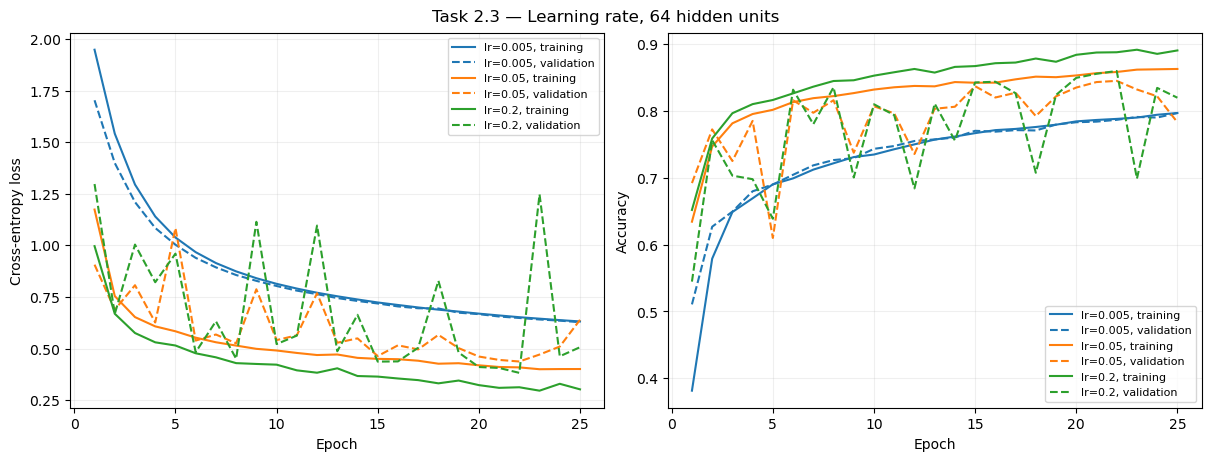

lr=0.005, selected_epoch=25, training_loss=0.631183, validation_loss=0.627326, training_accuracy=79.69%, validation_accuracy=79.69%, training_seconds=6.60 | lr=0.05, selected_epoch=22, training_loss=0.408506, validation_loss=0.436975, training_accuracy=85.83%, validation_accuracy=84.50%, training_seconds=6.90 | lr=0.2, selected_epoch=22, training_loss=0.312237, validation_loss=0.381955, training_accuracy=88.78%, validation_accuracy=85.98%, training_seconds=6.48


In [18]:
# 2.3 — Optimisation: varying only the learning rate.
from pathlib import Path
from time import perf_counter

results_dir = Path("results/part2")
results_dir.mkdir(parents=True, exist_ok=True)

optimisation_choices = {0.05: baseline}
training_times = {0.05: 6.9}  # Measured time from your completed baseline.

for learning_rate, run_id in [(0.005, "P2-lr0005-width64"),(0.2, "P2-lr02-width64"),]:
    start = perf_counter()
    optimisation_choices[learning_rate] = train_mlp(run_id,width=64,
        lr=learning_rate,seed=42,epochs=25,)
    training_times[learning_rate] = perf_counter() - start

# Select each run's checkpoint using minimum validation loss.
summary_rows = []

for learning_rate in sorted(optimisation_choices):
    history = optimisation_choices[learning_rate]
    best = history.loc[history["val_loss"].idxmin()]

    summary_rows.append({
        "run": best["run"],
        "width": int(best["width"]),
        "lr": learning_rate,
        "parameters": int(best["parameters"]),
        "selected_epoch": int(best["epoch"]),
        "train_loss": best["train_loss"],
        "val_loss": best["val_loss"],
        "train_acc": best["train_acc"],
        "val_acc": best["val_acc"],
        "training_seconds": training_times[learning_rate],})

optimisation_summary = pd.DataFrame(summary_rows)

summary_path = results_dir / "2.3_optimisation_summary.csv"
history_path = results_dir / "2.3_optimisation_history.csv"
figure_path = results_dir / "2.3_optimisation_curves.png"

optimisation_summary.to_csv(summary_path, index=False)

pd.concat([optimisation_choices[lr] for lr in sorted(optimisation_choices)],
    ignore_index=True,).to_csv(history_path, index=False)

print(optimisation_summary.round(6).to_string(index=False))

# Learning curves: colour identifies learning rate;
# solid/dashed lines identify training/validation.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")

for learning_rate in sorted(optimisation_choices):
    history = optimisation_choices[learning_rate]

    for ax, metric in zip(axes, ["loss", "acc"]):
        line, = ax.plot(history["epoch"],history[f"train_{metric}"],
            label=f"lr={learning_rate:g}, training",)

        ax.plot(
            history["epoch"],history[f"val_{metric}"],linestyle="--",
            color=line.get_color(),label=f"lr={learning_rate:g}, validation",)

for ax, ylabel in zip(axes, ["Cross-entropy loss", "Accuracy"]):
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

fig.suptitle("Task 2.3 — Learning rate, 64 hidden units")
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

# Build the experiment record from the measured results.
result_entries = []

for _, row in optimisation_summary.iterrows():
    result_entries.append(
        f"lr={row['lr']:g}, "
        f"selected_epoch={int(row['selected_epoch'])}, "
        f"training_loss={row['train_loss']:.6f}, "
        f"validation_loss={row['val_loss']:.6f}, "
        f"training_accuracy={row['train_acc']:.2%}, "
        f"validation_accuracy={row['val_acc']:.2%}, "
        f"training_seconds={row['training_seconds']:.2f}"
    )

exp_optimisation = {
    "id": "P2_3-OPTIMISATION-01",
    "question":"How does learning rate affect training dynamics and validation?",
    "hypothesis": (
        "The smaller learning rate may learn more slowly. "
        "The larger learning rate may improve progress but could cause "
        "oscillation or instability."),
    "changed_variable": "SGD learning rate: 0.005, 0.05, 0.2",
    "fixed_conditions": (
        "Architecture=784-64-10; parameters=50890; ReLU; "
        "Xavier-uniform weights; zero biases; "
        "same saved image indices; float32 pixels divided by 255; "
        "same initialisation seed and training batch order"),
    "split": "10,000 fitting images; 10,000 validation images",
    "seed": "Model initialisation=42; training shuffle generator=42",
    "configuration": (
        "Loss=cross-entropy; optimiser=SGD; batch_size=128; "
        "epochs=25; momentum=0; weight_decay=0; "
        "checkpoint=first minimum validation loss per run; "
        "lr=0.05 reuses P2-baseline64"),
    "metric": (
        "Per-epoch training/validation cross-entropy and accuracy; "
        "selected epoch; total training runtime"),
    "result": " | ".join(result_entries),
    "output_path": (
        f"{summary_path}; {history_path}; {figure_path}; "
        f"{results_dir / 'P2-baseline64.pt'}; "
        f"{results_dir / 'P2-lr0005-width64.pt'}; "
        f"{results_dir / 'P2-lr02-width64.pt'}"),}

register_path = Path("results/experiment_register.csv")
register_path.parent.mkdir(parents=True, exist_ok=True)
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part2_2_capacity])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

print(exp_optimisation["result"])

.  
******** 2.3 Analysis *******
* 0.005 learned slowly and steadily. Training and validation loss decreased smoothly, with accuracy still improving near epoch 25. Its best checkpoint occurred at the final epoch. This suggests that the fixed training budget limited its performance and that additional epochs might help improve accuracy.
* 0.05 made faster progress. Its selected validation accuracy was 4.81 percentage points higher than 0.005. However, its validation curves fluctuated noticeably between epochs.
* 0.2 achieved the strongest training fit and best validation checkpoint. It improved validation accuracy by 1.48 percentage  over the baseline, 148 additional correct predictions among 10,000 validation images.
* The largest learning rate also showed substantial instability. Its validation loss repeatedly spiked, including around epoch 23, despite a broadly decreasing training-loss curve. A plausible explanation is that larger gradient steps sometimes moved the weights away from a configuration that generalized well.
* Checkpoint selection mattered. For 0.2, the final epoch’s validation accuracy was approximately 82%, below the selected epoch’s 85.98%. The minimum-validation-loss rule retained the better epoch-22 model.
* The training curves look smoother partly because the code averages training measurements across batches while weights change. Validation evaluates one fixed set of weights at the end of each epoch. That difference in measurement should be acknowledged when comparing their fluctuations.
* Among the three learning rates tested, 0.2 produced the best validation-selected checkpoint within 25 epochs for seed 42, but its validation performance fluctuated substantially. The smaller rate learned more smoothly and may benefit from a longer training budget.
* The spikes alone do not establish overfitting. They make optimisation stability an important part.

   
***** End of Part 2 *****


**** Part 3: Coursework Requirement ******
* Guiding question: When does the network overfit, how do we recognise it, and how can we reduce it?
* 3.1 Main comparison. Compare an unregularised or weakly regularised model with the same architecture trained with a regularisation strategy of your choice and explore how different regularization strategies affect generalization.
* 3.2 Randomness. Train the two configurations behind your main conclusion with the same three seeds (existing runs count) and a fixed data split. Record every source of randomness you control. Explain the impact of randomness.

*** Part 3.1 Exploring how regularisation strategy affects generalisation - How I am approaching it *****
* Train three configuration versions of the same network: (1) Unregularised using Standard SGD which will provide reference performance as benchmark (2) Weight decay strategy and (3) Dropout as an alternative strategy
* Everything else is fixed, including architecture, data split, learning rate and training budget.
* For each strategy, the following will be assessed: (1) validation loss and accuracy to assess generalisation (2) training and validation curves to see when their behaviour diverges and (3) the training–validation gap because, for example, if weight decay lowers training accuracy but improves validation accuracy, that supports a generalisation benefit. If both accuracies fall, the chosen setting may be too restrictive.

In [33]:
import random

results_dir = Path("results/part3")
results_dir.mkdir(parents=True, exist_ok=True)

class RegularisedMLP(FashionMLP):
    def __init__(self, width=64, dropout=0.0):
        super().__init__(width)
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, pixels):
        features = torch.relu(self.hidden(pixels))
        features = self.dropout(features)
        return self.output(features)

def evaluate_regularisation(model, loader, loss_fn):
    """Measure plain cross-entropy and accuracy with fixed weights."""
    model.eval()
    loss_sum, correct = 0.0, 0

    with torch.no_grad():
        for pixels, targets in loader:
            pixels = pixels.to(device)
            targets = targets.to(device)

            logits = model(pixels)
            loss_sum += loss_fn(logits, targets).item() * len(targets)
            correct += (logits.argmax(1) == targets).sum().item()

    return loss_sum / len(loader.dataset), correct / len(loader.dataset)


def train_regularisation(condition, seed, weight_decay=0.0,dropout=0.0,lr=0.01, width=256, epochs=500,):
    # Control initialisation, dropout and any Python/NumPy randomness.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    model = RegularisedMLP(width=width, dropout=dropout).to(device)
   
    n_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
    run_id = f"P3-w{width}-e{epochs}-l{lr}-{condition}-seed{seed}"

    # Independent generator keeps batch order matched across conditions.
    train_loader = DataLoader(train_data,batch_size=128,shuffle=True,
        generator=torch.Generator().manual_seed(seed),num_workers=0,)

    # Separate generators prevent evaluation from consuming dropout RNG state.
    train_eval_loader = DataLoader(train_data,batch_size=128,shuffle=False,
        generator=torch.Generator().manual_seed(0),num_workers=0,)
    val_eval_loader = DataLoader(val_data,batch_size=128,shuffle=False,
        generator=torch.Generator().manual_seed(0),num_workers=0,)

    loss_fn = nn.CrossEntropyLoss()
    optimiser = torch.optim.SGD(model.parameters(),lr=lr,momentum=0.0,
        weight_decay=weight_decay,)

    history = []
    best_val_loss = float("inf")
    start = perf_counter()

    # Train for the configured budget; select a checkpoint by validation loss
    for epoch in range(1, epochs + 1):
        model.train()

        for pixels, targets in train_loader:
            pixels = pixels.to(device)
            targets = targets.to(device)

            optimiser.zero_grad()
            logits = model(pixels)
            loss = loss_fn(logits, targets)
            loss.backward()
            optimiser.step()

        train_loss, train_acc = evaluate_regularisation(model, train_eval_loader, loss_fn)
        val_loss, val_acc = evaluate_regularisation(model, val_eval_loader, loss_fn)

        history.append({"run": run_id,"condition": condition,"seed": seed,"width": width,
            "parameters": n_parameters,"epoch_budget": epochs,"epoch": epoch,
            "weight_decay": weight_decay, "dropout": dropout, "train_loss": train_loss,
            "val_loss": val_loss, "train_acc": train_acc,"val_acc": val_acc,
            "lr": lr, "batch_size": 128,"gap_pp": 100 * (train_acc - val_acc),})

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save({ "model_state": model.state_dict(),"width": width,"parameters": n_parameters,
                "epoch_budget": epochs,"epoch": epoch,"seed": seed,"lr": lr,"batch_size": 128,
                "weight_decay": weight_decay,"dropout": dropout, }, results_dir / f"{run_id}.pt")

    elapsed = perf_counter() - start
    history = pd.DataFrame(history)
    history.to_csv(results_dir / f"{run_id}_history.csv", index=False)

    best = history.loc[history["val_loss"].idxmin()].to_dict()
    best["training_seconds"] = elapsed

    print(
        f"{run_id}: selected epoch={best['epoch']}, "
        f"validation accuracy={best['val_acc']:.2%}")

    return history, best

*** Part 3.2 Exploring the impact or randomness - How I am approaching it ****
* Each configuration version above (unregularised, weight delay and dropout) is trained with seeds 42, 43 and 44. Changing the seed changes the initial weights and training-image order.
* Randomness impacts to evaluate are (1) how different is each configuration (2) Is the regularisation consistent, i.e., does it improve consistently or its very random

In [40]:
conditions = {
    "unregularised": {"weight_decay": 0.0, "dropout": 0.0},
    "weight_decay": {"weight_decay": 0.001, "dropout": 0.0},
    "dropout": {"weight_decay": 0.0, "dropout": 0.2},
}

seeds = [42, 43, 44]
regularisation_histories = []
regularisation_results = []

for condition, settings in conditions.items():
    for seed in seeds:
        history, result = train_regularisation(
            condition=condition, seed=seed, **settings,lr=0.01,width=256,epochs=500,)

        # The existing fields in result describe the selected checkpoint.
        final = history.iloc[-1]
        result.update({"final_epoch": int(final["epoch"]), "final_train_loss": final["train_loss"],
            "final_val_loss": final["val_loss"],"final_train_acc": final["train_acc"],
            "final_val_acc": final["val_acc"],"final_gap_pp": final["gap_pp"],})

        regularisation_histories.append(history)
        regularisation_results.append(result)

regularisation_history = pd.concat(regularisation_histories, ignore_index=True)
regularisation_summary = pd.DataFrame(regularisation_results)

regularisation_history.to_csv(results_dir / "all_learning_curves.csv", index=False)
regularisation_summary.to_csv(results_dir / "seed_results.csv", index=False)

print("\nSelected-checkpoint results")
print(regularisation_summary[["condition", "seed", "epoch", "train_loss",
         "val_loss", "train_acc", "val_acc", "gap_pp"]].round(4).to_string(index=False))

print("\nFinal-epoch results")
print(regularisation_summary[["condition", "seed", "final_epoch",
         "final_train_loss", "final_val_loss",
         "final_train_acc", "final_val_acc", "final_gap_pp"]].round(4).to_string(index=False)
)

aggregate = regularisation_summary.groupby("condition").agg(
    number_of_seeds=("seed", "nunique"),
    val_accuracy_mean=("val_acc", "mean"),
    val_accuracy_sample_std=("val_acc", "std"),
    val_loss_mean=("val_loss", "mean"),
    val_loss_sample_std=("val_loss", "std"),
    gap_pp_mean=("gap_pp", "mean"),
    final_val_accuracy_mean=("final_val_acc", "mean"),
    final_val_accuracy_sample_std=("final_val_acc", "std"),
    final_val_loss_mean=("final_val_loss", "mean"),
    final_val_loss_sample_std=("final_val_loss", "std"),
    final_gap_pp_mean=("final_gap_pp", "mean"),)

aggregate.to_csv(results_dir / "mean_and_sample_std.csv")

print("\nMean and sample standard deviation across three seeds")
print(aggregate.round(6).to_string())

# Paired accuracy improvements at selected checkpoints and epoch 500.
selected_accuracy = regularisation_summary.pivot(
    index="seed", columns="condition", values="val_acc")
final_accuracy = regularisation_summary.pivot(
    index="seed", columns="condition", values="final_val_acc")

paired = pd.DataFrame(index=selected_accuracy.index)

for condition in ["weight_decay", "dropout"]:
    paired[f"{condition}_selected_gain_percentage"] =  100 * (
        selected_accuracy[condition] - selected_accuracy["unregularised"])
    paired[f"{condition}_final_gain_percentage"] = 100 * (
        final_accuracy[condition] - final_accuracy["unregularised"])

paired.to_csv(results_dir / "paired_accuracy_comparison.csv")

print("\nPaired accuracy improvements, in percentage points")
print(paired.round(2).to_string())

P3-w256-e500-l0.01-unregularised-seed42: selected epoch=347, validation accuracy=86.53%
P3-w256-e500-l0.01-unregularised-seed43: selected epoch=264, validation accuracy=86.57%
P3-w256-e500-l0.01-unregularised-seed44: selected epoch=364, validation accuracy=86.66%
P3-w256-e500-l0.01-weight_decay-seed42: selected epoch=485, validation accuracy=86.77%
P3-w256-e500-l0.01-weight_decay-seed43: selected epoch=494, validation accuracy=86.89%
P3-w256-e500-l0.01-weight_decay-seed44: selected epoch=481, validation accuracy=86.90%
P3-w256-e500-l0.01-dropout-seed42: selected epoch=451, validation accuracy=87.59%
P3-w256-e500-l0.01-dropout-seed43: selected epoch=482, validation accuracy=87.56%
P3-w256-e500-l0.01-dropout-seed44: selected epoch=497, validation accuracy=87.57%

Selected-checkpoint results
    condition  seed  epoch  train_loss  val_loss  train_acc  val_acc  gap_pp
unregularised    42    347      0.2276    0.3844     0.9273   0.8653    6.20
unregularised    43    264      0.2649    0.38

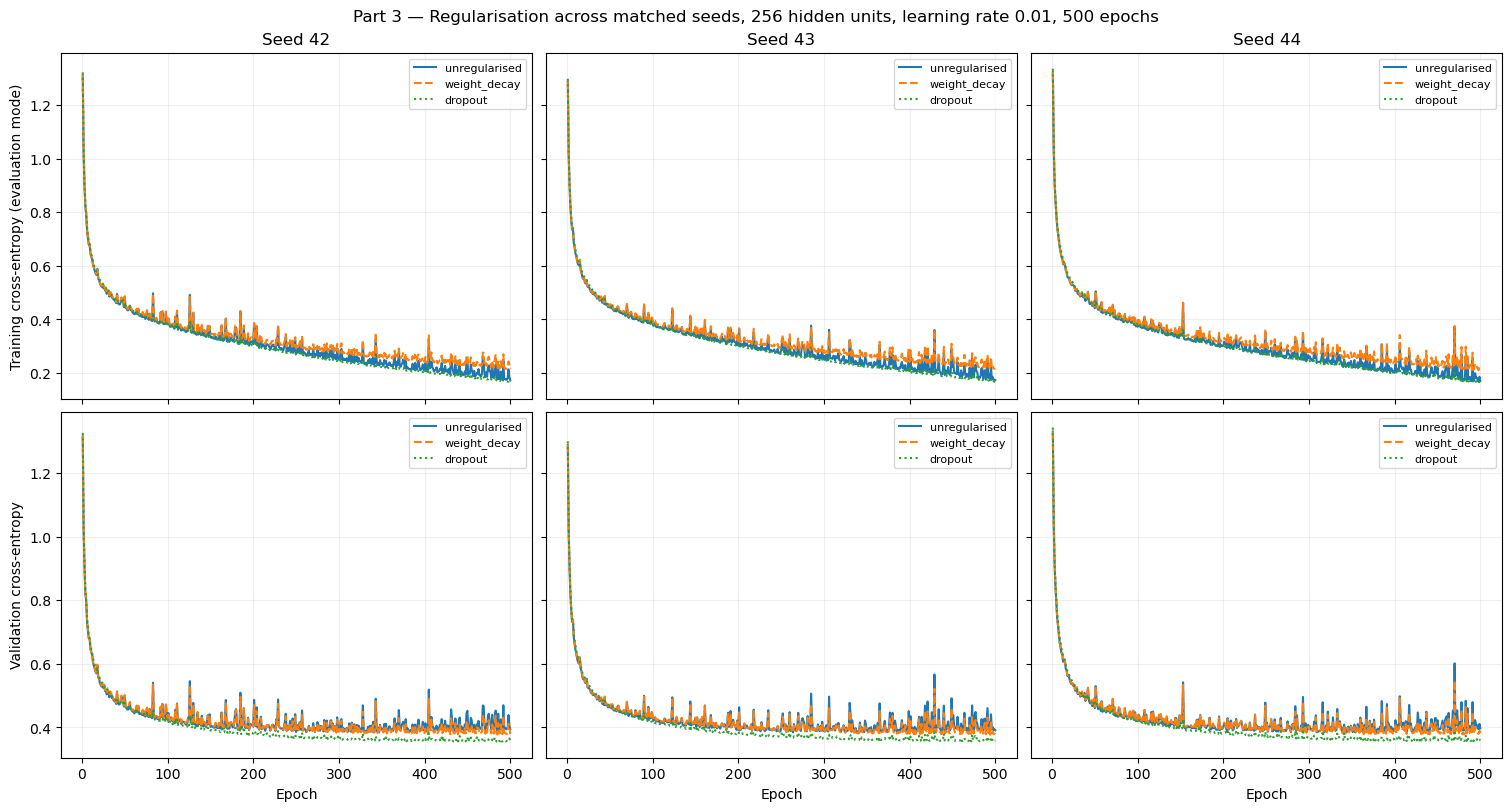

In [41]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey="row",layout="constrained")

styles = {
    "unregularised": ("tab:blue", "-"),
    "weight_decay": ("tab:orange", "--"),
    "dropout": ("tab:green", ":"),}

for column, seed in enumerate(seeds):
    for condition, (colour, linestyle) in styles.items():
        history = regularisation_history.loc[
            (regularisation_history["seed"] == seed)
            & (regularisation_history["condition"] == condition)].sort_values("epoch")

        for row, metric in enumerate(["train_loss", "val_loss"]):
            axes[row, column].plot(history["epoch"],history[metric],color=colour,
                linestyle=linestyle,label=condition,)

    axes[0, column].set_title(f"Seed {seed}")
    axes[1, column].set_xlabel("Epoch")

for ax in axes.flat:
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

axes[0, 0].set_ylabel("Training cross-entropy (evaluation mode)")
axes[1, 0].set_ylabel("Validation cross-entropy")

fig.suptitle("Part 3 — Regularisation across matched seeds, 256 hidden units, learning rate 0.01, 500 epochs")
fig.savefig(results_dir / "regularisation_curves.png", dpi=150)
plt.show()

*** Part 3.1: My outcome analysis ****
* I compared an unregularised model, weight decay 0.001 and dropout 0.2, using the same 256-unit architecture, learning rate 0.01, batch size 128 and 500-epoch budget, with three matched seeds. Each run’s checkpoint was selected using minimum validation cross-entropy. I also compared all models at epoch 500.
* Both training and validation losses decreased rapidly during early training. Later, training loss continued decreasing while validation improvements became smaller. The unregularised validation curves eventually plateaued and showed mild deterioration alongside fluctuations.
* The unregularised results support late-stage overfitting measured by cross-entropy. For seeds 42, 43 and 44, training loss decreased from 0.2276, 0.2649 and 0.2132 at the selected checkpoints to 0.1738, 0.1731 and 0.1698 at epoch 500. Meanwhile, validation loss increased from 0.3844, 0.3842 and 0.3832 to 0.3945, 0.3912 and 0.3970. The selected epochs—347, 264 and 364—identify the observed validation-loss minima, while the fluctuating curves make the exact onset of overfitting uncertain.
* Dropout produced the strongest generalisation results. At the selected checkpoints, it reduced validation loss by 0.0304, 0.0278 and 0.0271 relative to the unregularised model. Mean validation loss decreased from 0.3839 to 0.3555, and mean validation accuracy increased from 86.59% to 87.57%.
* Dropout’s benefit persisted at the common 500-epoch endpoint. Mean validation accuracy was 87.42%, compared with 86.57% unregularised, and mean validation loss was 0.3575, compared with 0.3942. Its later validation curves generally lay below the other conditions and showed smaller fluctuations.
* Weight decay provided a modest benefit. It improved selected-checkpoint validation accuracy and loss in every seed. Mean selected validation accuracy increased to 86.85%, and mean validation loss decreased to 0.3774. At epoch 500, its mean validation accuracy was 86.73% and loss was 0.3799.
* The accuracy gap required interpretation alongside validation performance. At epoch 500, weight decay reduced the mean gap from 8.39 to 6.83 percentage points, while dropout’s gap was 7.79 points. Dropout achieved the best validation performance even though weight decay produced the smallest gap.
* Overall, dropout 0.2 gave the largest observed generalisation benefit, while weight decay 0.001 gave a smaller benefit. These conclusions apply to the tested architecture, training recipe and fixed data split.

*** Part 3.2 My outcome analysis ***
* Weight decay improved selected-checkpoint validation accuracy by +0.24, +0.32 and +0.24 percentage points for seeds 42, 43 and 44. Its final-epoch improvements were +0.30, 0.00 and +0.17 points, showing that the measured benefit also depended on the evaluation checkpoint.
* Dropout improved selected-checkpoint validation accuracy for every seed by +1.06, +0.99 and +0.91 percentage points, equivalent to 106, 99 and 91 additional correct predictions among 10,000 validation images. Its final-epoch improvements were also consistently positive at +0.82, +0.85 and +0.88 points.
* Mean selected-checkpoint validation accuracy and sample standard deviation were 86.59% ± 0.067 percentage points for the unregularised model, 86.85% ± 0.072 points for weight decay, and 87.57% ± 0.015 points for dropout.
* At epoch 500, these values were 86.57% ± 0.122 points, 86.73% ± 0.076 points, and 87.42% ± 0.123 points, respectively. Dropout’s particularly low variability at selected checkpoints therefore did not extend to the final-epoch results.
* Randomness affected the timing of fluctuations and checkpoint selection. The unregularised selected epochs ranged from 264 to 364, weight decay from 481 to 494, and dropout from 451 to 497. Initialisation and training-image order changed together across seeds, while dropout also introduced seeded activation masking. The data split stayed fixed.
* The matched comparisons show that dropout’s validation benefit persisted across all three seeds and both evaluation methods. Weight decay’s benefit was smaller. Three seeds provide a rough estimate of variability, and the experiment measures the combined effect of the controlled random sources.

In [43]:
from pathlib import Path
import pandas as pd

# Build the result text from the measured results.
result_entries = []

for _, row in regularisation_summary.sort_values(["condition", "seed"]).iterrows():
    result_entries.append(f"{row['condition']}, seed={int(row['seed'])}, "
        f"selected_epoch={int(row['epoch'])}, "
        f"selected_train_loss={row['train_loss']:.6f}, "
        f"selected_val_loss={row['val_loss']:.6f}, "
        f"selected_train_accuracy={row['train_acc']:.2%}, "
        f"selected_val_accuracy={row['val_acc']:.2%}, "
        f"final_epoch={int(row['final_epoch'])}, "
        f"final_train_loss={row['final_train_loss']:.6f}, "
        f"final_val_loss={row['final_val_loss']:.6f}, "
        f"final_train_accuracy={row['final_train_acc']:.2%}, "
        f"final_val_accuracy={row['final_val_acc']:.2%}, "
        f"training_seconds={row['training_seconds']:.2f}")

exp_regularisation = {
    "id": "P3_REGULARISATION_01",
    "question": "How do weight decay and dropout affect generalisation during extended training?",
    "hypothesis": ("Continued training may improve training fit after validation "
        "improvements saturate. Regularisation may improve validation "
        "performance or reduce later deterioration, with effects varying across seeds."),
    "changed_variable": ("Regularisation: none; weight_decay=0.001; dropout=0.2. "
        "Each condition repeated with seeds 42,43,44."),
    "fixed_conditions": ("Architecture=784-256-10; parameters=203530; ReLU; "
        "Xavier-uniform weights; zero biases; "
        "saved fitting/validation indices; float32 pixels divided by 255 and flattened to 784 features; "
        "matched initial weights and mini-batch order within each seed"),
    "split": (f"Fitting images={len(train_data)}; "
        f"validation images={len(val_data)}"),
    "seed": ("42,43,44; Python, NumPy and PyTorch seeded; "
        "independent training-loader generator seeded per run; "
        "evaluation-loader generators seeded 0; num_workers=0; "
        "PyTorch seed also controls dropout masking"),
    "configuration": ("SGD; learning_rate=0.01; batch_size=128; epochs=500; "
        "momentum=0; loss=cross-entropy; "
        "weight decay applies to weights and biases; "
        "dropout follows hidden ReLU; "
        "checkpoint=first minimum validation cross-entropy; "
        f"device={device}"),
    "metric": ("End-of-epoch training/validation cross-entropy and accuracy "
        "in evaluation mode; cross-entropy excludes weight-decay penalty; "
        "selected-checkpoint and final-epoch results; "
        "mean and sample standard deviation (ddof=1) across three seeds; "
        "paired accuracy differences in percentage points"),
    "result": " | ".join(result_entries),
    "output_path": "; ".join(
        str(results_dir / filename)
        for filename in [
            "all_learning_curves.csv",
            "seed_results.csv",
            "mean_and_sample_std.csv",
            "paired_accuracy_comparison.csv",
            "regularisation_curves.png",]),}


register_path = Path("results/experiment_register.csv")
register_path.parent.mkdir(parents=True, exist_ok=True)
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_regularisation])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

print(exp_regularisation["result"])

dropout, seed=42, selected_epoch=451, selected_train_loss=0.182720, selected_val_loss=0.354033, selected_train_accuracy=94.59%, selected_val_accuracy=87.59%, final_epoch=500, final_train_loss=0.165791, final_val_loss=0.355882, final_train_accuracy=95.19%, final_val_accuracy=87.33%, training_seconds=173.93 | dropout, seed=43, selected_epoch=482, selected_train_loss=0.172911, selected_val_loss=0.356437, selected_train_accuracy=94.91%, selected_val_accuracy=87.56%, final_epoch=500, final_train_loss=0.167339, final_val_loss=0.357995, final_train_accuracy=95.10%, final_val_accuracy=87.56%, training_seconds=180.33 | dropout, seed=44, selected_epoch=497, selected_train_loss=0.163127, selected_val_loss=0.356124, selected_train_accuracy=95.53%, selected_val_accuracy=87.57%, final_epoch=500, final_train_loss=0.163401, final_val_loss=0.358510, final_train_accuracy=95.34%, final_val_accuracy=87.37%, training_seconds=177.03 | unregularised, seed=42, selected_epoch=347, selected_train_loss=0.227573,

******** End of Part 3 ********

********** Part 4 **************

********* Part 4.1 - My approach plan *******
* K values to try - 2, 4, 6, 8, 10, 12, 15, 20
* Ramdom seeds (same as all experiments above) - 42, 43, 44
* Initial search - k-means++, 10 restarts per seed
* Selection rule - ighest mean validation silhouette; exact ties favour smaller K
* Supporting evidence - training inertia and validation squared distance to training centroids
* Stability experiment at selected 8 - 	random versus k-means++, each with 1 versus 10 restarts
* Other fit settings - Lloyd algorithm, maximum 300 iterations, tolerance 1e-4
* Measuring approach
  * For selecting K -- silhouette measures how close an image is to its own cluster compared with neighbouring clusters. Higher values indicate more compact, separated groups under the chosen distance measure. It can favour broad groupings, so the selected K may be much smaller than ten.
  * For stability -- Adjusted Rand Index (ARI) compares two runs’ assignments on the same validation images. It accounts for arbitrary cluster numbering. Here we compare cluster assignments against other cluster assignments, using no clothing labels. ARI of 1 indicates identical partitions; values around 0 indicate chance-level agreement

In [16]:
import sklearn
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

part4_dir = Path("results/part4_1")
part4_dir.mkdir(parents=True, exist_ok=True)

X_cluster_train = (images[cluster_train_index].astype(np.float32).reshape(-1, 784) / 255.0)
X_cluster_val = (images[cluster_val_index].astype(np.float32).reshape(-1, 784) / 255.0)

K_VALUES = [2, 4, 6, 8, 10, 12, 15, 20]
SEEDS = [42, 43, 44]

protocol = {
    "images": "784 raw pixels, float32, divided by 255",
    "training_images": 3000,
    "validation_images": 1000,
    "k_values": K_VALUES,
    "seeds": SEEDS,
    "selection_init": "k-means++",
    "selection_n_init": 10,
    "selection_rule": ( "Highest mean validation silhouette across three seeds; "),
    "stability_init": ["random", "k-means++"],
    "stability_n_init": [1, 10],
    "algorithm": "lloyd",
    "max_iter": 300,
    "tol": 1e-4,
    "distance": "Euclidean; squared for inertia",}

with open(part4_dir / "protocol.json", "w") as file:
    json.dump(protocol, file, indent=2)

#saving the exact indices used so I can use them in the next sessins
cluster_indices = {"train_index": cluster_train_index.tolist(),
    "val_index": cluster_val_index.tolist() }
with open(part4_dir / "used_indices.json", "w") as f:
    json.dump(cluster_indices, f)

In [17]:
import joblib

#creating a helperfunction so I can call these with different K values & seeds later
def fit_raw_kmeans(k, seed, init, n_init, phase):
    run_id = f"{phase}-k{k}-{init}-ninit{n_init}-seed{seed}"

    model = KMeans(n_clusters=k, init=init, n_init=n_init, max_iter=300,
        tol=1e-4, algorithm="lloyd", random_state=seed, copy_x=True,)

    model.fit(X_cluster_train)
    val_clusters = model.predict(X_cluster_val)

    n_val_clusters = np.unique(val_clusters).size

    # silhouette apparently requires at least two occupied clusters
    val_silhouette = np.nan
    if 2 <= n_val_clusters < len(X_cluster_val):
        val_silhouette = silhouette_score(X_cluster_val, val_clusters, metric="euclidean")

    # score() returns negative total squared distance to fitted centres are adding minus.
    val_mean_sq_distance = -model.score(X_cluster_val) / len(X_cluster_val)

    record = {
        "run": run_id, "K": k, "seed": seed, "init": init, "n_init": n_init,
        "train_inertia": model.inertia_,
        "train_mean_sq_distance": model.inertia_ / len(X_cluster_train),
        "val_mean_sq_distance": val_mean_sq_distance, "val_silhouette": val_silhouette,
        "occupied_val_clusters": n_val_clusters, "iterations": model.n_iter_,
        "reached_iteration_limit": model.n_iter_ == model.max_iter,}

    print(f"{run_id}: silhouette={val_silhouette:.4f}, "
        f"inertia={model.inertia_:.2f}")

    return record, val_clusters

Ksearch-k2-k-means++-ninit10-seed42: silhouette=0.1887, inertia=160839.72
Ksearch-k2-k-means++-ninit10-seed43: silhouette=0.1887, inertia=160839.72
Ksearch-k2-k-means++-ninit10-seed44: silhouette=0.1887, inertia=160839.73
Ksearch-k4-k-means++-ninit10-seed42: silhouette=0.1789, inertia=124613.07
Ksearch-k4-k-means++-ninit10-seed43: silhouette=0.1789, inertia=124613.06
Ksearch-k4-k-means++-ninit10-seed44: silhouette=0.1789, inertia=124613.05
Ksearch-k6-k-means++-ninit10-seed42: silhouette=0.1514, inertia=109298.93
Ksearch-k6-k-means++-ninit10-seed43: silhouette=0.1515, inertia=109296.13
Ksearch-k6-k-means++-ninit10-seed44: silhouette=0.1515, inertia=109296.13
Ksearch-k8-k-means++-ninit10-seed42: silhouette=0.1533, inertia=100720.78
Ksearch-k8-k-means++-ninit10-seed43: silhouette=0.1676, inertia=100589.12
Ksearch-k8-k-means++-ninit10-seed44: silhouette=0.1505, inertia=100709.47
Ksearch-k10-k-means++-ninit10-seed42: silhouette=0.1364, inertia=95169.04
Ksearch-k10-k-means++-ninit10-seed43: 

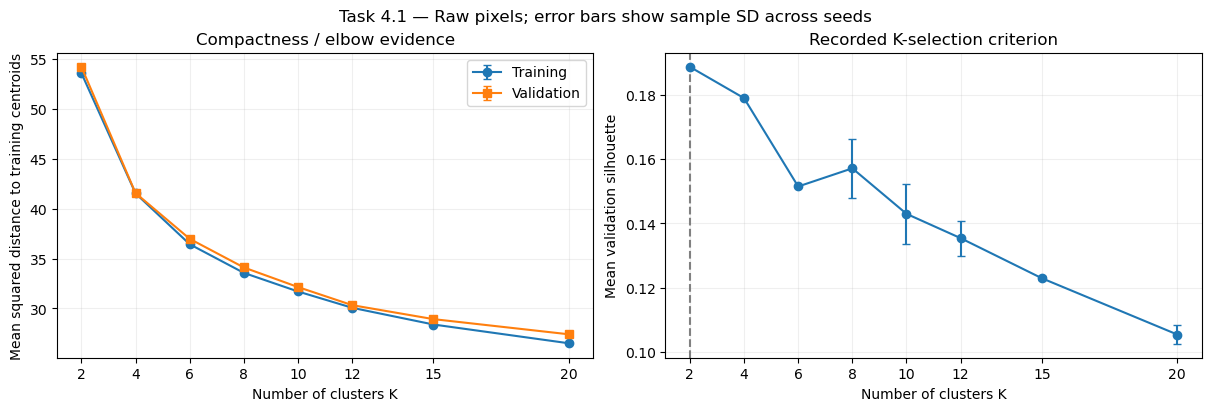

In [18]:
k_records = []

shared_kmeans_settings = { "max_iter": 300, "tol": 1e-4, "algorithm": "lloyd", "copy_x": True,}
shared_config = {
    "preprocessing": "Flatten to 784 pixels and divide by 255",
    "indices_file": str(part4_dir / "used_indices.json"),
    "fixed_kmeans_settings": shared_kmeans_settings,}
with open(part4_dir / "shared_config.json", "w") as file:
    json.dump(shared_config, file, indent=2)
    
for k in K_VALUES:
    for seed in SEEDS:
        record, _ = fit_raw_kmeans( k=k, seed=seed, init="k-means++",
            n_init=10, phase="Ksearch",)
        k_records.append(record)

k_results = pd.DataFrame(k_records)
k_results.to_csv(part4_dir / "k_search_runs.csv", index=False)

k_summary = k_results.groupby("K", as_index=False).agg(
    train_distance_mean=("train_mean_sq_distance", "mean"),
    train_distance_std=("train_mean_sq_distance", "std"),
    val_distance_mean=("val_mean_sq_distance", "mean"),
    val_distance_std=("val_mean_sq_distance", "std"),
    silhouette_mean=("val_silhouette", "mean"),
    silhouette_std=("val_silhouette", "std"),
    valid_silhouette_runs=("val_silhouette", "count"),)

k_summary.to_csv(part4_dir / "k_search_summary.csv", index=False)
print(k_summary.round(4).to_string(index=False))

# Apply the recorded selection rule.
eligible = k_summary.loc[k_summary["valid_silhouette_runs"] == len(SEEDS)]
if eligible.empty:
    raise ValueError("No K produced valid silhouette scores for all seeds.")

chosen_k = int(eligible.sort_values(
        ["silhouette_mean", "K"], ascending=[False, True]).iloc[0]["K"])

print(f"\nSelected K by mean validation silhouette: {chosen_k}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

for prefix, label, marker in [("train", "Training", "o"),("val", "Validation", "s"),]:
    axes[0].errorbar(k_summary["K"],k_summary[f"{prefix}_distance_mean"],
        yerr=k_summary[f"{prefix}_distance_std"],marker=marker, capsize=3,label=label,)

axes[0].set_ylabel("Mean squared distance to training centroids")
axes[0].set_title("Compactness / elbow evidence")
axes[0].legend()

axes[1].errorbar(k_summary["K"],k_summary["silhouette_mean"],
    yerr=k_summary["silhouette_std"],marker="o",capsize=3,)
axes[1].axvline(chosen_k, color="grey", linestyle="--")
axes[1].set_ylabel("Mean validation silhouette")
axes[1].set_title("Recorded K-selection criterion")

for ax in axes:
    ax.set_xlabel("Number of clusters K")
    ax.set_xticks(K_VALUES)
    ax.grid(alpha=0.2)

fig.suptitle("Task 4.1 — Raw pixels; error bars show sample SD across seeds")
fig.savefig(part4_dir / "k_selection.png", dpi=150)
plt.show()

**** Part 4.1 - Interpretation / Analysis ****
* Compactness improves as K increases. Training and validation squared distances fall fast from K=2 to K=4, then decrease more slowly. This shows diminishing returns, with biger bend around K=4,6.
* Training and validation distances are close. The centroids show the images with similar average glaring to the training images.
* Silhouette is highest at K=2: 0.1887. Even if larger K produces tighter clusters, their separation compaered to the within-cluster distances makes them not useful.
* The increase at K=8 seem to change with the seeds. Its mean silhouette is 0.1571, with a standard deviation of 0.0091. The  error bars at K=8,10,12 are showing reaction to initialisation even with 10  restarts.
* The chosen K is K=2 but this do not mean there are exactly two clothing groups. It only means two clusters gave the highest mean validation silhouette from testing values

In [19]:
from itertools import combinations

stability_records = []
assignments = {}

for init in ["random", "k-means++"]:
    for n_init in [1, 10]:
        for seed in SEEDS:
            record, val_clusters = fit_raw_kmeans( k=chosen_k, seed=seed,
                init=init, n_init=n_init, phase="stability",)
            stability_records.append(record)
            assignments[(init, n_init, seed)] = val_clusters

stability_results = pd.DataFrame(stability_records)
stability_results.to_csv(part4_dir / "stability_runs.csv", index=False)

ari_records = []

for init in ["random", "k-means++"]:
    for n_init in [1, 10]:
        for seed_a, seed_b in combinations(SEEDS, 2):
            ari_records.append({"init": init, "n_init": n_init, "seed_a": seed_a,
                "seed_b": seed_b, "ARI": adjusted_rand_score(
                    assignments[(init, n_init, seed_a)],
                    assignments[(init, n_init, seed_b)],),})

ari_results = pd.DataFrame(ari_records)
ari_results.to_csv(part4_dir / "pairwise_stability_ari.csv", index=False)

stability_summary = stability_results.groupby(["init", "n_init"]).agg(
    inertia_mean=("train_inertia", "mean"),
    inertia_sample_std=("train_inertia", "std"),
    silhouette_mean=("val_silhouette", "mean"),
    silhouette_sample_std=("val_silhouette", "std"),)

ari_summary = ari_results.groupby(["init", "n_init"]).agg(
    pairwise_ARI_mean=("ARI", "mean"),
    pairwise_ARI_min=("ARI", "min"),)

stability_summary = stability_summary.join(ari_summary)
stability_summary.to_csv(part4_dir / "stability_summary.csv")

print(stability_summary.round(4).to_string())
print("\nIndividual pairwise ARI values")
print(ari_results.round(4).to_string(index=False))

stability-k2-random-ninit1-seed42: silhouette=0.1888, inertia=160840.70
stability-k2-random-ninit1-seed43: silhouette=0.1887, inertia=160839.72
stability-k2-random-ninit1-seed44: silhouette=0.1888, inertia=160840.70
stability-k2-random-ninit10-seed42: silhouette=0.1887, inertia=160839.73
stability-k2-random-ninit10-seed43: silhouette=0.1887, inertia=160839.58
stability-k2-random-ninit10-seed44: silhouette=0.1887, inertia=160839.73
stability-k2-k-means++-ninit1-seed42: silhouette=0.1888, inertia=160840.70
stability-k2-k-means++-ninit1-seed43: silhouette=0.1888, inertia=160840.70
stability-k2-k-means++-ninit1-seed44: silhouette=0.1888, inertia=160840.70
stability-k2-k-means++-ninit10-seed42: silhouette=0.1887, inertia=160839.72
stability-k2-k-means++-ninit10-seed43: silhouette=0.1887, inertia=160839.72
stability-k2-k-means++-ninit10-seed44: silhouette=0.1887, inertia=160839.73
                  inertia_mean  inertia_sample_std  silhouette_mean  silhouette_sample_std  pairwise_ARI_mean  p

*** Part 4.1 - Interpretation / Analysis *****
* Random initialisation was already stable with one restart. Pairwise ARI went from 0.9761 to 1.0000, showing similar validation partitions.
* 10 restarts improved random-initialisation stability. Mean ARI went from 0.9841 to 0.9973, and the minimum increased to 0.9960. Training inertia also became lower.
* K-means++ produced consistent validation assignments across seeds within each restart. All pairwise ARIs were 1.000. These comprisons show consistency for n_init=1 and n_init=10;
* The inertia benefit from more restarts was only little tiny atK=2. For K-means++, mean inertia went down by 1.0 out of 160841
* Lower inertia did not improve silhouette.silhouette changed little from 0.1888 to 0.1887. This make sense because K-means optimises squared distance to centroids, but silhouette tests relative within-cluster and between-cluster distances.
* I selected K=2 because it gave the highest mean validation silhouette in all the tested values. At this K, the validation partition can be produced agai across three seeds. Also, restarts slightly  improved stability for random initialisation and slightly reduced training inertia. These show stable  partition, but that doesnot mean correct clothing categories or a global optima.

In [20]:
#k-means++ with ten restarts and lowest-training-inertia seed
#this model will be used in 4.2 to inspect class composition and the comparison required in Part 5
candidates = stability_results.loc[(stability_results["init"] == "k-means++")
    & (stability_results["n_init"] == 10)]

selected_run = candidates.sort_values(["train_inertia", "seed"]).iloc[0]
selected_seed = int(selected_run["seed"])

# Recreate the selected fit using the same data and settings.
kmeans_selected = KMeans( n_clusters=int(chosen_k),init="k-means++",
    n_init=10,random_state=selected_seed,**shared_kmeans_settings,)
kmeans_selected.fit(X_cluster_train)

# Save just this model.
selected_model_path = part4_dir / "selected_kmeans.joblib"
joblib.dump(kmeans_selected, selected_model_path)

# Keep this record: Part 4.2 uses it to locate the selected model.
selection = { "K": int(chosen_k), "init": "k-means++","n_init": 10,
    "seed": selected_seed,
    "representative_rule": "Minimum training inertia among k-means++ runs with 10 restarts",
    "model_path": str(selected_model_path),
}

with open(part4_dir / "selected_protocol.json", "w") as file:
    json.dump(selection, file, indent=2)
print(selection)

exp_raw_kmeans = { "id": "P4_1-RAW-KMEANS-01",
    "question": (
        "Which K is good for raw-pixel training, and how sensitive is the solution to initialisation and restarts?"),
    "hypothesis": ("Increasing K will reduce squared-distance distortion. "
        "K-means++ and additional restarts may improve the objective "
        "and reduce sensitivity to initialisation."),
    "changed_variable": (f"K={K_VALUES}; at selected K, init=random/k-means++ and n_init=1/10"),
    "fixed_conditions": ("raw float32 pixels / 255; 784 features;  "
        "Euclidean geometry; Lloyd algorithm; max_iter=300; tol=1e-4"),
    "split": "3,000 training images; 1,000 validation images",
    "seed": str(SEEDS),
    "configuration": ("K search: k-means++, n_init=10; choose highest mean validation "
        "silhouette with smaller K breaking exact ties"),
    "metric": ("Training inertia; training/validation mean squared distance; "
        "validation silhouette; pairwise validation-assignment ARI; sample SD across seeds;"),
    "result": (f"Selected K={chosen_k}; representative seed={selection['seed']}. "
        + stability_summary.reset_index().to_json(orient="records")),
    "output_path": str(part4_dir),}

register_path = Path("results/experiment_register.csv")
register_path.parent.mkdir(parents=True, exist_ok=True)
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_raw_kmeans])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

print(exp_raw_kmeans["result"])

{'K': 2, 'init': 'k-means++', 'n_init': 10, 'seed': 42, 'representative_rule': 'Minimum training inertia among k-means++ runs with 10 restarts', 'model_path': 'results/part4_1/selected_kmeans.joblib'}
Selected K=2; representative seed=42. [{"init":"k-means++","n_init":1,"inertia_mean":160840.703125,"inertia_sample_std":0.0,"silhouette_mean":0.1887971461,"silhouette_sample_std":0.0,"pairwise_ARI_mean":1.0,"pairwise_ARI_min":1.0},{"init":"k-means++","n_init":10,"inertia_mean":160839.7239583333,"inertia_sample_std":0.009021098,"silhouette_mean":0.1886642873,"silhouette_sample_std":0.0,"pairwise_ARI_mean":1.0,"pairwise_ARI_min":1.0},{"init":"random","n_init":1,"inertia_mean":160840.375,"inertia_sample_std":0.5683291712,"silhouette_mean":0.1887528598,"silhouette_sample_std":0.000076706,"pairwise_ARI_mean":0.9840800775,"pairwise_ARI_min":0.9761201163},{"init":"random","n_init":10,"inertia_mean":160839.6822916667,"inertia_sample_std":0.0902109796,"silhouette_mean":0.1886856953,"silhouette_sam

**** Part 4.2 - My approach plan *****
* Examine what the two clusters (since K=2) contain, then connect those observations to how K-means measures similarity.
* the model saved in 4.1 and the 1,000 validation images will be used to create class counts and percentages within each cluster, percentage of each clothing class assigned to each cluster, Centroid images, typical examples and randomly selected examples.

In [21]:
part4_2_dir = Path("results/part4_2")
part4_2_dir.mkdir(parents=True, exist_ok=True)

with open(part4_dir / "selected_protocol.json") as file:
    selection = json.load(file)

kmeans_selected = joblib.load(selection["model_path"])
chosen_k = int(selection["K"])

# Reconstruct validation inputs from the exact indices saved in 4.1.
with open(part4_dir / "used_indices.json", "r") as f:
    saved = json.load(f)
interpretation_index = np.array(saved["val_index"], dtype=int)

X_interpret = (images[interpretation_index].astype(np.float32).reshape(-1, 784) / 255.0)

# Labels are used here to interpret the fixed assignments.
true_classes = classes[interpretation_index]
cluster_assignments = kmeans_selected.predict(X_interpret)

composition = pd.crosstab(
    pd.Series(cluster_assignments, name="Cluster"),
    pd.Series(true_classes, name="Class"),).reindex(
    index=range(chosen_k), columns=range(len(class_names)),fill_value=0,)

composition.columns = pd.Index(class_names, name="Class")
print("\nClass counts")
print(composition.to_string())

cluster_sizes = composition.sum(axis=1)
class_supports = composition.sum(axis=0)
print("Validation images per cluster")
print(cluster_sizes.to_string())


# Each row sums to 100% for an occupied cluster.
within_cluster_pct = (composition.div(cluster_sizes.replace(0, np.nan), axis=0) * 100)
print("\nClass composition within each cluster (%)")
print(within_cluster_pct.round(1).to_string())

# Each column sums to 100% for a represented clothing class.
within_class_pct = (composition.div(class_supports.replace(0, np.nan), axis=1) * 100)
print("\nDistribution of each class across clusters (%)")
print(within_class_pct.round(1).to_string())


Class counts
Class    T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker  Bag  Ankle boot
Cluster                                                                                      
0                 76       73        77     63    90       0     65        0   35          13
1                 24       27        23     37    10     100     35      100   65          87
Validation images per cluster
Cluster
0    492
1    508

Class composition within each cluster (%)
Class    T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker   Bag  Ankle boot
Cluster                                                                                       
0               15.4     14.8      15.7   12.8  18.3     0.0   13.2      0.0   7.1         2.6
1                4.7      5.3       4.5    7.3   2.0    19.7    6.9     19.7  12.8        17.1

Distribution of each class across clusters (%)
Class    T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker   Bag 

****** Part 4.2 - Interpretation / Analysis ******
* After fixing the protocol in Part4.1, I used the original classes to interpret the assignments of the 1000 validation images. Cluster 0 has 492 images and cluster 1 has 508. But the Classes were not used to fit K-means or choose the K value.
* It looks like Cluster 0 mainly has clothing that goes on the body. It has 90% coats, 77% pullovers, 76% tshirts/tops, 73% trousers, 65% shirts and 63% dress. But it did not isolate any one class: coats is the maximum one and it was only 18.3% of the images.
* Cluster 1 has most footwear. All 100 sandals, all 100 sneakers and 87 of 100 ankle boots. Together, footwear was 287 of 508 images, almost 56.5%. It also has 65 bags and also from every  class, so it was not only a footwear cluster.
* Most classes were split between clusters. e.g. shirts were split 65%–35%, dresses was split 63%–37%, and bags was split 35%–65%.
* K-means assigns images to their closest centroid using squared distance. This works for compact groups around an average image. When using raw-pixel, distances depend on brightness and where the  foreground pixels are, position changes, the the shape can impact the distance even within the same  class.
* The composition shows many visual similarities, but the centroids and example images are helpful to see which property seperates these clusters.
* Different classes can share visual features, while one class can contain several distinct appearances. Selecting K=2 after validation silhouette  means that two clusters gave the strongest separation among the tested settings with this representation. It does not say that the images are only in two groups.

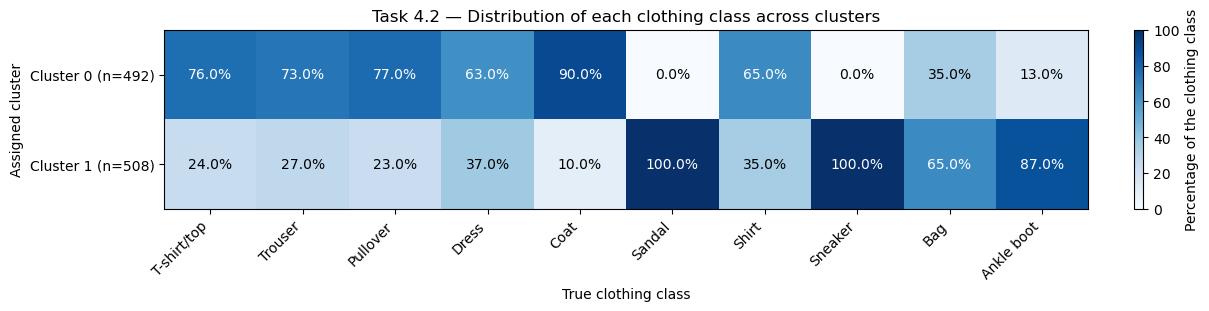

In [22]:
#showing the class distribution using a heatmap
fig, ax = plt.subplots(figsize=(12, max(3, chosen_k * 0.8)),layout="constrained",)

heatmap = ax.imshow(within_class_pct.to_numpy(),cmap="Blues",vmin=0,vmax=100,aspect="auto",)

ax.set_xticks(range(len(class_names)), labels=class_names)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

ax.set_yticks(range(chosen_k),labels=[
        f"Cluster {c} (n={cluster_sizes.loc[c]})" for c in range(chosen_k)],)

for cluster in range(chosen_k):
    for class_id in range(len(class_names)):
        value = within_class_pct.iloc[cluster, class_id]
        ax.text( class_id, cluster, f"{value:.1f}%",
            ha="center", va="center", color="white" if value > 50 else "black",)

ax.set_title("Task 4.2 — Distribution of each clothing class across clusters")
ax.set_xlabel("True clothing class")
ax.set_ylabel("Assigned cluster")

fig.colorbar(heatmap, ax=ax, label="Percentage of the clothing class")
fig.savefig(part4_2_dir / "class_distribution.png",dpi=150,bbox_inches="tight",)
plt.show()

****** Part 4.2 - heatmap Analysis ******
* The heatmap is matching the above tables :
  * Cluster 0 is mostly clothing worn on body, like coats is 90%.
  * Cluster 1 is a lot of footwear: 100% sandals and sneakers, and 87% ankle boots.
  * Bags, dresses and shirts are divided

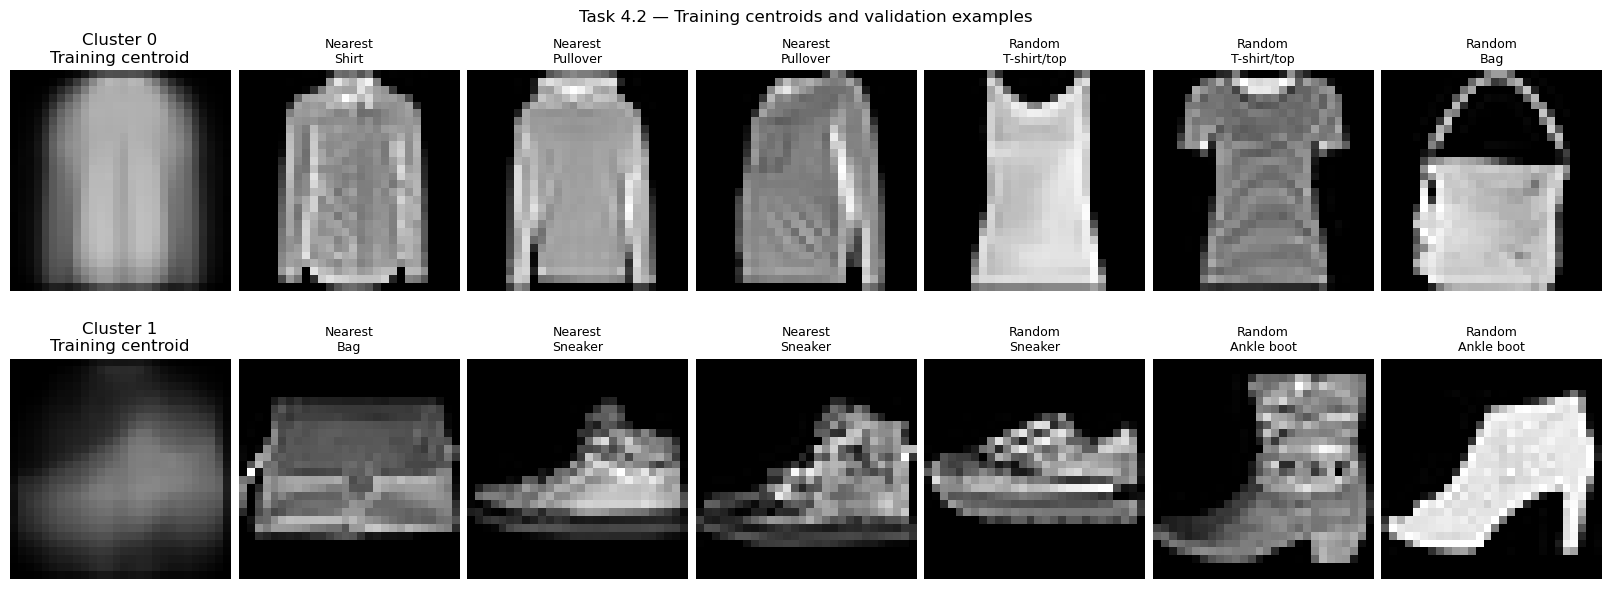

In [23]:
# Centroids and example images
distances = kmeans_selected.transform(X_interpret)
rng = np.random.default_rng(42)

fig, axes = plt.subplots(chosen_k, 7, figsize=(16, 3 * chosen_k), 
    squeeze=False,layout="constrained",)

example_records = []

for cluster in range(chosen_k):
    for ax in axes[cluster]:
        ax.axis("off")

    axes[cluster, 0].imshow(kmeans_selected.cluster_centers_[cluster].reshape(28, 28),
        cmap="gray",vmin=0,vmax=1,)
    axes[cluster, 0].set_title(f"Cluster {cluster}\nTraining centroid")

    members = np.flatnonzero(cluster_assignments == cluster)
    nearest = members[np.argsort(distances[members, cluster])[:3]]

    remaining = np.setdiff1d(members, nearest)
    random_members = rng.choice(remaining,size=min(3, len(remaining)),replace=False,)

    for start_column, positions, method in [(1, nearest, "Nearest"),(4, random_members, "Random"),]:
        for offset, position in enumerate(positions):
            ax = axes[cluster, start_column + offset]
            original_index = int(interpretation_index[position])
            ax.imshow(images[original_index],cmap="gray", vmin=0,vmax=255,)
            ax.set_title(f"{method}\n{class_names[true_classes[position]]}",fontsize=9,)

            example_records.append({"cluster": cluster,"selection": method,
                "official_train_index": original_index,
                "true_class": class_names[true_classes[position]],
                "distance_to_centroid": distances[position, cluster],})

fig.suptitle("Task 4.2 — Training centroids and validation examples")
fig.savefig(part4_2_dir / "centroids_and_examples.png",dpi=150,bbox_inches="tight",)
plt.show()

pd.DataFrame(example_records).to_csv(part4_2_dir / "displayed_examples.csv", index=False)

****** Part 4.2 - My interpretation / analysis ****
* Cluster 1’s centroid has a tall, centrally filled shape. Its nearest examples are a shirt and two pullovers, which share this broad arrangement of foreground pixels despite having different labels. The random examples include two T-shirts/tops and a bag, confirming that the cluster includes several categories.
* Cluster 0’s centroid concentrates brighter pixels towards the lower part of the image, with a shoe-like outline. Its nearest examples include two sneakers and a bag. The random examples show a sneaker and two ankle boots, consistent with the strong footwear concentration in the composition table.
* Bags illustrate why visual similarity and class identity differ. A bag appears among the displayed examples in each cluster, and one is among the nearest examples to cluster 1’s centroid. This is consistent with K-means grouping images by pixel arrangement rather than recognising their function as clothing or accessories.
* The centroids are blurred because they average many training images. They summarise shared pixel patterns rather than represent individual items. Nearest examples show images close to that average; random examples reveal some of the variation within each cluster.
* These observations support the interpretation that raw-pixel K-means discovered broad shape and foreground-location structure, rather than the ten labelled categories. The small image sample illustrates this explanation; the full composition table provides the stronger evidence about class membership.
* Training centroids and validation examples. Each row shows a training centroid, three validation images nearest to that centroid within its cluster, and three randomly selected remaining members. The examples suggest grouping by broad silhouette and foreground location, with different labelled classes sharing similar pixel patterns.

In [24]:
with open(part4_dir / "selected_protocol.json", "r") as f:
    p42_selection = json.load(f)

exp_raw_cluster_interpret = { "id": "P4_2-RAW_CLUSTER_INTERPRET",
    "question": "What clothing categories are seen in the fixed raw-pixel clusters?",
    "hypothesis": "Raw-pixel clusters will only  capture broad silhouette similarities mixing the classes.",
    "changed_variable": "None: interpreting the protocol fixed in Part 4.1.",
    "fixed_conditions": "Same selected K-means model and validation images; labels added to interpret",
    "split": "Model fitted on 3,000 training images; interpretation on 1,000 validation images.",
    "seed": (f"selected_kmeans_seed: {p42_selection["seed"]}, example_sampling_seed: 42"),
    "configuration": ("images: 784 raw pixels divided by 255; ",
        f"selected_protocol: {p42_selection}; ",),
    "metric": "Cluster sizes; class composition and distribution; ",
    "result": ("footwear_dominated_cluster; size: 508, footwear: 287; "
            "body_clothing: 156, bags: 65; clothing_dominated_cluster_size: 492; "
        "conclusion: Broad clothing-footwear grouping with a lot of mixed classes"),
    "output_path": (f"selected_model: {p42_selection["model_path"]}; ",
        f"selected_protocol: {str(part4_dir / "selected_protocol.json")}"),
}

register_path = Path("results/experiment_register.csv")
register_path.parent.mkdir(parents=True, exist_ok=True)
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_raw_cluster_interpret])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

***** Part 4.3 - how this clustering relates to the classification errors from Part 1.3 *******
* References:
  * Part 1.3 figures - figures/part1_3_error_examples_4_classifiers.png, figures/part1_3_shirt_errors_svm.png
  * Part 4.2 figures - class distribution heatmap here (results/part4_2/class_distribution.png) and the centroids and examples here (centroids_and_examples.png)
* Shirt was difficult for all four classifiers. Its recall was 59.6% for logistic regression, 62.6% for SVM, 56.7% for random forest and 45.1% for the decision tree. These results refer to the Part 1.3 models, including logistic regression with \(C=1.0\).
* The clustering provides evidence of broad visual overlap between the confused categories. Cluster 0 received 65% of shirts, 76% of T-shirts/tops, 77% of pullovers and 90% of coats. Its centroid had a tall, centrally filled silhouette, and its nearest displayed examples included a shirt and two pullovers. This suggests that different clothing classes can share similar raw-pixel patterns.
* his grouping is consistent with the classification confusions. Among 1,000 actual shirts, logistic regression predicted 144 as T-shirt/top, SVM predicted 156 as T-shirt/top, and random forest predicted 166 as T-shirt/top. The decision tree predicted 184 shirts as Coat. Both T-shirt/top and Coat predominantly entered the same cluster as Shirt.
* However, the clustering does not explain why each classifier chose a particular incorrect label. The models learn different decision boundaries, whereas K-means groups images by distance to centroids. These results do not establish that brightness caused the decision tree’s errors; that would require further evidence from the misclassified images or a controlled experiment.
* Sharing a cluster does not mean two classes are indistinguishable. All sandals and sneakers entered cluster 1, yet they remain different classification targets. With only two clusters, K-means captures broad structure and necessarily groups several labelled categories together.
* The comparison has limits. Classification results were measured on 10,000 validation images, while clustering used the fixed 1,000-image validation subset. These findings connect class-level patterns; they do not show that the particular misclassified shirts were assigned to a particular cluster.
* Conclusion: The clustering supports shared visual structure as a possible contributor to Shirt classification errors. It does not prove their cause or establish which classifier is best.

***** Part 4.4 - My approach plan ******
* I am picking Ward linkage because it connects directly to the squared-error compactness objective used by K-means. At each step, Ward merges the two groups that produce the smallest increase in within-cluster sum of squared distances. This makes it suitable for exploring how compact groups of raw-pixel images combine into broader groups.
* Average linkage uses the average pairwise distance between groups, while complete linkage uses the maximum pairwise distance. Both are valid alternatives, but Ward keeps the focus on squared-error compactness while adding the nested structure that my K-means result does not provide.
* This choice does not imply that Ward produces better clusters than the alternatives, which I have not tested. Ward favours compact groups and remains sensitive to pixel alignment, brightness and unusual images. Its greedy, irreversible merges also mean that cutting the hierarchy at K=2 need not reproduce the two K-means clusters.
* Using the following appoach for this exercise:
  * images - 200 random samples from the saved clustering training subset
  * seed - 42
  * linkage - Ward
  * distance - Euclidean

In [25]:
import scipy
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree

hierarchy_dir = Path("results/part4_4")
hierarchy_dir.mkdir(parents=True, exist_ok=True)

HIERARCHY_SEED = 42
HIERARCHY_N = 200

with open(part4_dir / "used_indices.json", "r") as f:
    saved_indices = json.load(f)
training_pool = np.asarray(saved_indices["train_index"], dtype=int)

rng = np.random.default_rng(HIERARCHY_SEED)
hierarchy_indices = np.sort(rng.choice(training_pool, size=HIERARCHY_N, replace=False))

# Same raw-pixel representation as Part 4.1.
X_hierarchy = (images[hierarchy_indices].astype(np.float64).reshape(HIERARCHY_N, -1) / 255.0)

Z = linkage(X_hierarchy, method="ward", metric="euclidean", optimal_ordering=False,)

# Two different cuts of the SAME fitted hierarchy.
cuts = cut_tree(Z, n_clusters=[2, 4])
groups_2 = cuts[:, 0]
groups_4 = cuts[:, 1]

np.save(hierarchy_dir / "image_indices.npy", hierarchy_indices)
np.save(hierarchy_dir / "linkage_matrix.npy", Z)

config = {"sample_source": str(part4_dir / "used_indices.json"),"sample_source_key": "train_index",
    "sample_size": HIERARCHY_N, "sampling_seed": HIERARCHY_SEED,
    "sampling": "without replacement; indices sorted before fitting",
    "preprocessing": "flatten 28x28 pixels; float64; divide by 255", "method": "ward",
    "metric": "euclidean", "optimal_ordering": False, "interpretation_cuts": [2, 4],}

with open(hierarchy_dir / "configuration.json", "w") as f:
    json.dump(config, f, indent=2)

print(f"Images: {HIERARCHY_N}")
print(f"Features per image: {X_hierarchy.shape[1]}")
print(f"Two-group sizes: {np.bincount(groups_2)}")
print(f"Four-group sizes: {np.bincount(groups_4)}")

Images: 200
Features per image: 784
Two-group sizes: [ 81 119]
Four-group sizes: [28 49 53 70]


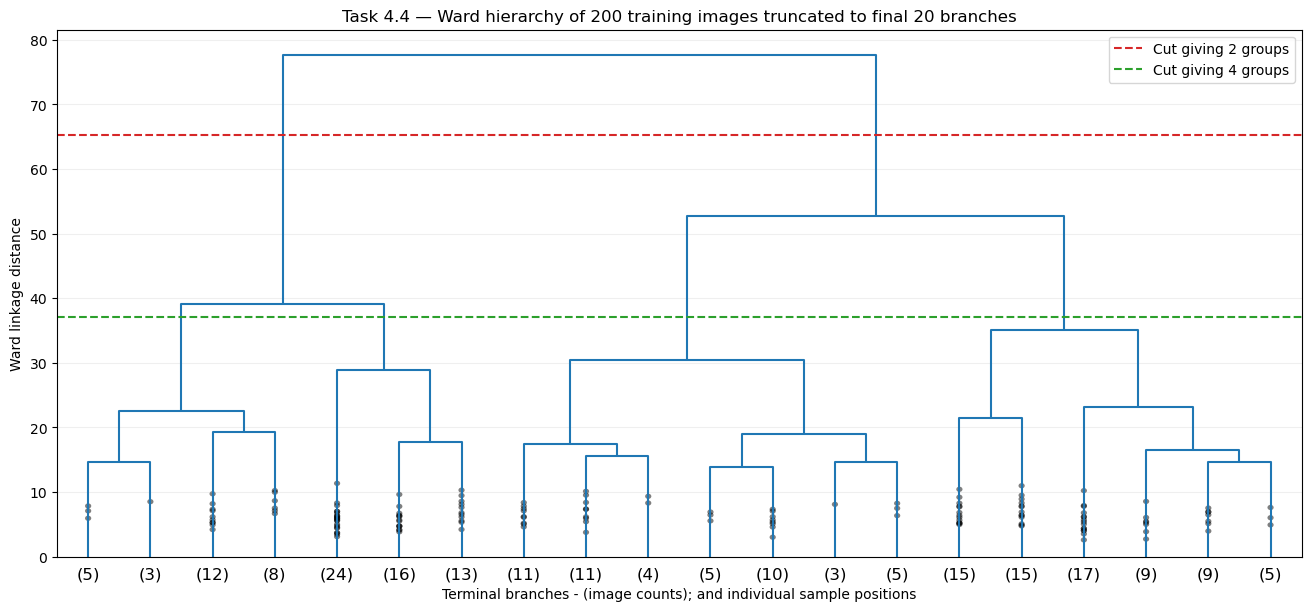

In [26]:
#the diagram shows merges: the higher the joining branch, the larger the Ward linkage distance at that merge.
fig, ax = plt.subplots(figsize=(13, 6), layout="constrained")

dendrogram( Z, truncate_mode="lastp", p=20, show_leaf_counts=True,show_contracted=True,
    color_threshold=0,above_threshold_color="tab:blue",ax=ax,)

# Heights between successive merges corresponding to our chosen cuts.
for k, colour in [(2, "tab:red"), (4, "tab:green")]:
    lower = Z[-k, 2]
    upper = Z[-(k - 1), 2]

    if lower < upper:
        height = (lower + upper) / 2
        ax.axhline(height,color=colour,linestyle="--",label=f"Cut giving {k} groups",)
    else:
        print(f"Tied merge heights: no distinct horizontal cut for k={k}.")

ax.set_title( "Task 4.4 — Ward hierarchy of 200 training images truncated to final 20 branches")
ax.set_xlabel("Terminal branches - (image counts); and individual sample positions")
ax.set_ylabel("Ward linkage distance")
ax.legend()
ax.grid(axis="y", alpha=0.2)

fig.savefig(hierarchy_dir / "dendrogram.png", dpi=150, bbox_inches="tight")
plt.show()

***** Part 4.4 - Diagram analysis *******
* the dendrogram clearly shows nested structure at different levels, which is a key observation:
  * The red cut gives two broad groups: 81 and 119 images
  * The green cut splits each broad group into two smaller groups: the left branch contains groups of 28 and 53 images; the right branch contains groups of 49 and 70 images
  * The left pair merges at a Ward distance of approximately 39, whereas the right pair merges around 53. The two broad branches merge last, around 78.
  * This means merging the two broad branches produces a larger increase in within-cluster squared error than the preceding merges. It does not establish that they represent two true clothing categories.
  * The dendrogram reveals structure within the two broad groups. At the four-group cut, each broad group divides into two subgroups. These subgroups merge at different heights, showing that the hierarchy contains several levels of grouping. This extends the single partition produced by K-means: it records how smaller groups combine, and partitions obtained by cutting the same tree remain nested.


Class counts at the 2-group cut:
Class  T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker  Bag  Ankle boot
Group                                                                                      
0                2        1         5      0     4      18      4       20    9          18
1               24       17        12     19    19       0     19        0    9           0

Composition within each group (%) at the 2-group cut:
Class  T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker   Bag  Ankle boot
Group                                                                                       
0              2.5      1.2       6.2    0.0   4.9    22.2    4.9     24.7  11.1        22.2
1             20.2     14.3      10.1   16.0  16.0     0.0   16.0      0.0   7.6         0.0

Class counts at the 4-group cut:
Class  T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker  Bag  Ankle boot
Group                                        

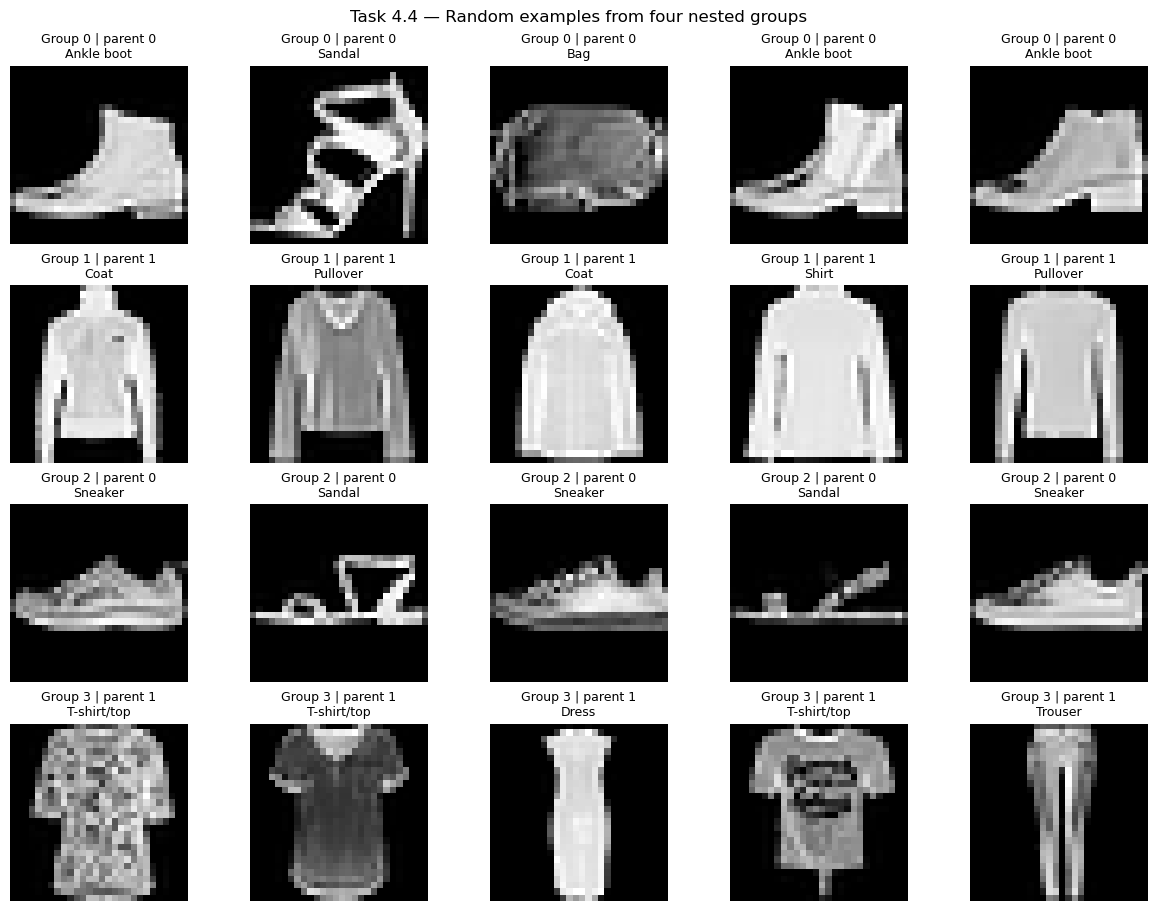

In [27]:
#Interpreting the groups with labels
true_hierarchy = np.asarray(classes)[hierarchy_indices]

assignments = pd.DataFrame({"original_index": hierarchy_indices,"group_2": groups_2,
    "group_4": groups_4,"true_class_id": true_hierarchy,
    "true_class": [class_names[int(c)] for c in true_hierarchy],})

for k, assignments_k in [(2, groups_2), (4, groups_4)]:
    counts = pd.crosstab(
        pd.Series(assignments_k, name="Group"),
        pd.Series(true_hierarchy, name="Class"),).reindex( index=range(k),
        columns=range(len(class_names)),fill_value=0,)
    counts.columns = pd.Index(class_names, name="Class")

    percentages = counts.div(counts.sum(axis=1), axis=0) * 100

    counts.to_csv(hierarchy_dir / f"class_counts_k{k}.csv")
    percentages.to_csv(hierarchy_dir / f"composition_percent_k{k}.csv")

    print(f"\nClass counts at the {k}-group cut:")
    print(counts.to_string())

    print(f"\nComposition within each group (%) at the {k}-group cut:")
    print(percentages.round(1).to_string())

nested = pd.crosstab(
    pd.Series(groups_4, name="Four-group branch"),
    pd.Series(groups_2, name="Two-group parent"),)
nested.to_csv(hierarchy_dir / "nested_groups.csv")

print("\nHow the four groups sit within the two broader groups:")
print(nested.to_string())

# Random examples avoid selecting only particularly convincing images.
example_rng = np.random.default_rng(42)
fig, axes = plt.subplots(4, 5, figsize=(12, 9), layout="constrained")
example_records = []
for group in range(4):
    members = np.flatnonzero(groups_4 == group)
    chosen = example_rng.choice(members, size=min(5, len(members)), replace=False)

    for ax in axes[group]:
        ax.axis("off")
    for column, pos in enumerate(chosen):
        ax = axes[group, column]
        # Image, label and membership all use the SAME subset position.
        ax.imshow(X_hierarchy[pos].reshape(28, 28),cmap="gray",vmin=0,vmax=1,)

        parent = int(groups_2[pos])
        original_index = int(hierarchy_indices[pos])

        ax.set_title(f"Group {group} | parent {parent}\n"f"{class_names[int(true_hierarchy[pos])]}",fontsize=9,)

fig.suptitle("Task 4.4 — Random examples from four nested groups")
fig.savefig(hierarchy_dir / "group_examples.png",dpi=150,bbox_inches="tight",)
plt.show()


******* Part 4.4 - Interpretation / Analysis ********
* At the two-group cut, Ward clustering produced groups of 81 and 119 images. The smaller group contained all 56 footwear images in this sample, although it also included bags and other clothing. Footwear therefore represented 69.1% of this group. The larger group contained no footwear.
* This broadly resembles the clothing–footwear separation found by K-means. However, the algorithms used different fitting samples, so this is a qualitative comparison rather than evidence that their assignments agree. Cluster numbers are arbitrary and need not match between methods.
* The four-group cut revealed additional structure within the footwear-containing branch. One subgroup contained 17 of the sample’s 18 ankle boots, together with eight bags. The other contained most sneakers and sandals. Thus, the hierarchy distinguished subgroups that were combined at the two-group cut.
* The clothing-containing branch also divided into two subgroups. One mainly contained coats, shirts and pullovers, alongside bags. The other mainly contained T-shirts/tops, dresses and trousers. These groups remained mixed, showing that hierarchical clustering did not recover the labelled categories exactly.
* The dendrogram records how these subgroups combine: the two footwear-containing subgroups merge at approximately 39, the two clothing-containing subgroups at approximately 53, and the broad branches at approximately 78 in Ward linkage distance. These heights reflect increases in squared-error compactness, influenced by both group size and separation.
* This adds information beyond a single K-means partition. It shows nested subdivisions and their merge sequence. Separate K-means fits at different values of \(K\) do not guarantee nested groups.
* The conclusions are limited to this fixed 200-image sample and raw-pixel representation. Ward makes irreversible, greedy merges, and the hierarchy does not establish a uniquely correct number of natural clothing categories. The two- and four-group cuts were chosen for interpretation, not demonstrated to be optimal.
* The example images suggest that the hierarchy captures finer differences in silhouette within the broad groups. Within the footwear-containing parent, group 0 includes taller ankle boots and a high-heeled sandal, whereas group 2 shows lower-profile sneakers and sandals. Within the clothing-containing parent, group 1 shows long-sleeved garments with similar torso shapes across several labels. Group 3 is more visually varied, containing T-shirts, dresses and trousers.
* These observations suggest that foreground position and shape contribute to the subdivisions, but the small selection of examples does not isolate which pixel properties caused each merge.

In [30]:
exp_raw_hierarchy = { "id": "P4_4_RAW_HIERARCHY-01",
    "question": "Does hierarchical clustering reveal more cluster beyond the K-means partition?",
    "hypothesis": "Broad groups may contain smaller subgroups with different with different class compositions.",
    "changed_variable": "Inspect two-group and four-group cuts of one Ward hierarchy.",
    "fixed_conditions": "Same 200 images and raw-pixel representation at both cuts; ",
    "split": "200 images sampled from the fixed 3,000-image clustering training subset.",
    "seed": "subset_seed: 42; example_seed: 42",
    "configuration": ("representation: 784 raw pixels; float64; divide by 255; "
        "method: Ward; metric: Euclidean; optimal_ordering: False; cuts: [2, 4]"),
     "metric": "group sizes; nested memberships; class composition",
    "result": "two_group_sizes: [81, 119]; four_group_sizes: [28, 49, 53, 70]",
    "conclusion": ("Both broad branches divide at the four-group cut. "
            "The footwear-containing branch separates mainly ankle boots "
            "and bags from mainly sneakers and sandals. "
            "The other branch divides mixed clothing groups."),
    "output_path": f"{str(hierarchy_dir)}",}


register_path = Path("results/experiment_register.csv")
register_path.parent.mkdir(parents=True, exist_ok=True)
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_raw_hierarchy])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

print(exp_raw_hierarchy["result"])

two_group_sizes: [81, 119]; four_group_sizes: [28, 49, 53, 70]


******* End of Part 4 ********

******** Part 5.1 - My approach plan **********
* For this experiment, i'm keeping the images and K-means procedure fixed and replacng each image’s 784 pixel values with the 256 hidden activations from the already trained MLP.
* I can repeat the K-search over 2, 4, 6, 8, 10, 12, 15 and 20, using the same three seeds and selection rule. but the main representation comparison stays at K=2. Changing K even if the results favor a different one would mean both comparing raw pixels at two clusters against features and at a different K so cannot change two factors for a simple comparison.
* I can then also repeat the initialisation/restart comparison at the same K=2, then inspect class composition and examples after fixing the clustering.
* Similarly, for the hierarchical comparison,I can reuse the exact saved 200-image sample, Ward linkage, and two- and four-group cuts like I did in part 4 for direct to direct comparison

In [34]:
#load and freeze the MLP
checkpoint_path = Path("results/part3/P3-w256-e500-l0.01-dropout-seed42.pt")
checkpoint = torch.load(checkpoint_path,map_location="cpu",weights_only=True,)

feature_model = RegularisedMLP(width=checkpoint["width"],dropout=checkpoint["dropout"],)
feature_model.load_state_dict(checkpoint["model_state"])
feature_model = feature_model.to(device)

# Disable dropout and prevent parameter updates.
feature_model.eval()
feature_model.requires_grad_(False)

print("Checkpoint:", checkpoint_path)
print("Selected epoch:", checkpoint["epoch"])
print("Hidden units:", checkpoint["width"])
print("Training dropout:", checkpoint["dropout"])
print("Evaluation mode:", not feature_model.training)
print("All parameters frozen:",
    all(not p.requires_grad for p in feature_model.parameters()),)

Checkpoint: results/part3/P3-w256-e500-l0.01-dropout-seed42.pt
Selected epoch: 451
Hidden units: 256
Training dropout: 0.2
Evaluation mode: True
All parameters frozen: True


In [37]:
#relod the indices used in part4
with open(part4_dir / "used_indices.json", "r") as f:
    part4_indices = json.load(f)
feature_train_indices = np.asarray(part4_indices["train_index"], dtype=int)
feature_val_indices = np.asarray(part4_indices["val_index"], dtype=int)

def scaled_pixels(indices):
    return (images[indices].astype(np.float32).reshape(len(indices), -1) / 255.0)

# Keep these arrays for the raw-pixel comparison.
raw_train = scaled_pixels(feature_train_indices)
raw_val = scaled_pixels(feature_val_indices)

print("Raw training shape:", raw_train.shape)
print("Raw validation shape:", raw_val.shape)

#extract hidden activation
def extract_hidden_features(pixel_array, batch_size=256):
    feature_model.eval()
    batches = []

    for start in range(0, len(pixel_array), batch_size):
        pixels = torch.from_numpy(pixel_array[start:start + batch_size]).to(device)
        features = torch.relu(feature_model.hidden(pixels))
        batches.append(features.cpu().numpy())
    return np.concatenate(batches, axis=0)

mlp_train_features = extract_hidden_features(raw_train)
mlp_val_features = extract_hidden_features(raw_val)

print("MLP training feature shape:", mlp_train_features.shape)
print("MLP validation feature shape:", mlp_val_features.shape)
print("Additional feature transformation: none")

Raw training shape: (3000, 784)
Raw validation shape: (1000, 784)
MLP training feature shape: (3000, 256)
MLP validation feature shape: (1000, 256)
Additional feature transformation: none


In [38]:
#KMeans search on these MLP features
K_VALUES = [2, 4, 6, 8, 10, 12, 15, 20]
CLUSTER_SEEDS = [42, 43, 44]

mlp_search_records = []

for k in K_VALUES:
    for seed in CLUSTER_SEEDS:
        model = KMeans(n_clusters=k,init="k-means++",n_init=10,max_iter=300,
            tol=1e-4,algorithm="lloyd",copy_x=True,random_state=seed,)

        # Fit only on training features.
        model.fit(mlp_train_features)
        val_clusters = model.predict(mlp_val_features)

        occupied = len(np.unique(val_clusters))
        silhouette = (silhouette_score(mlp_val_features, val_clusters)
            if 1 < occupied < len(mlp_val_features) else np.nan)

        mlp_search_records.append({"K": k,"seed": seed,"init": "k-means++",
            "n_init": 10,"inertia": model.inertia_,
            "train_distance": (model.inertia_ / len(mlp_train_features)),
            "val_distance": (-model.score(mlp_val_features) / len(mlp_val_features)),
            "silhouette": silhouette,"occupied_val_clusters": occupied,"iterations": model.n_iter_,})

        print(f"MLP features: K={k}, seed={seed}, silhouette={silhouette:.4f}, "
            f"inertia={model.inertia_:.2f}")

mlp_search_results = pd.DataFrame(mlp_search_records)

MLP features: K=2, seed=42, silhouette=0.3360, inertia=102847.69
MLP features: K=2, seed=43, silhouette=0.3360, inertia=102847.69
MLP features: K=2, seed=44, silhouette=0.3360, inertia=102847.68
MLP features: K=4, seed=42, silhouette=0.2241, inertia=78460.36
MLP features: K=4, seed=43, silhouette=0.2240, inertia=78459.91
MLP features: K=4, seed=44, silhouette=0.2240, inertia=78459.92
MLP features: K=6, seed=42, silhouette=0.2503, inertia=62463.40
MLP features: K=6, seed=43, silhouette=0.2503, inertia=62464.19
MLP features: K=6, seed=44, silhouette=0.2500, inertia=62463.70
MLP features: K=8, seed=42, silhouette=0.2530, inertia=53203.60
MLP features: K=8, seed=43, silhouette=0.2531, inertia=53203.79
MLP features: K=8, seed=44, silhouette=0.2531, inertia=53202.40
MLP features: K=10, seed=42, silhouette=0.2461, inertia=48055.29
MLP features: K=10, seed=43, silhouette=0.2463, inertia=48054.71
MLP features: K=10, seed=44, silhouette=0.2463, inertia=48054.67
MLP features: K=12, seed=42, silho

In [50]:
#summarize across seeds and apply same selection rule
part5_1_dir = Path("results/part5_1")
part5_1_dir.mkdir(parents=True, exist_ok=True)

mlp_k_summary = (mlp_search_results.groupby("K", as_index=False).agg(
        train_distance_mean=("train_distance", "mean"),
        train_distance_std=("train_distance", "std"),
        val_distance_mean=("val_distance", "mean"),
        val_distance_std=("val_distance", "std"),
        silhouette_mean=("silhouette", "mean"),
        silhouette_std=("silhouette", "std"),
        valid_silhouette_runs=("silhouette", "count"),))

# Require a valid silhouette for all three seeds.
eligible = mlp_k_summary.loc[mlp_k_summary["valid_silhouette_runs"] == len(CLUSTER_SEEDS)]
if eligible.empty:
    raise ValueError("No K had valid silhouette scores for all seeds.")

mlp_selected_k = int(eligible.sort_values(["silhouette_mean", "K"],
        ascending=[False, True],).iloc[0]["K"])

mlp_k_summary_results = pd.DataFrame(mlp_k_summary)
mlp_k_summary_results.to_csv(part5_1_dir / "mlp_k_summary.csv", index=False)

print(mlp_k_summary.round(4).to_string(index=False))
print("\nSelected K for MLP features:", mlp_selected_k)
print("K retained for the main raw-versus-MLP comparison: 2")

 K  train_distance_mean  train_distance_std  val_distance_mean  val_distance_std  silhouette_mean  silhouette_std  valid_silhouette_runs
 2              34.2826              0.0000            34.5182            0.0000           0.3360          0.0000                      3
 4              26.1534              0.0001            26.5208            0.0008           0.2240          0.0001                      3
 6              20.8213              0.0001            20.8340            0.0046           0.2502          0.0002                      3
 8              17.7344              0.0003            17.7225            0.0024           0.2531          0.0001                      3
10              16.0183              0.0001            16.1382            0.0028           0.2462          0.0001                      3
12              15.1154              0.0066            15.3091            0.1259           0.2096          0.0017                      3
15              14.1023              0.01

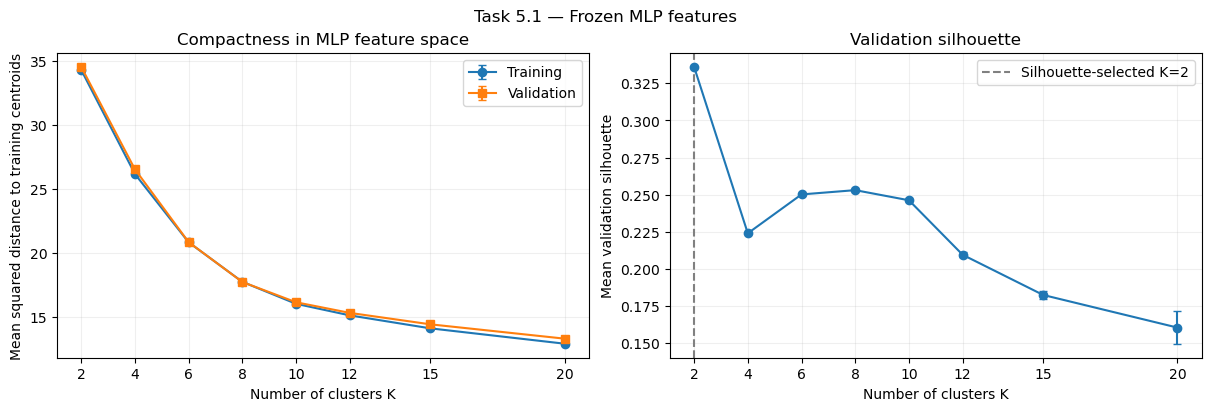

In [51]:
#plot the feaure-space results
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for split, marker in [("train", "o"), ("val", "s")]:
    axes[0].errorbar(mlp_k_summary["K"],mlp_k_summary[f"{split}_distance_mean"],
        yerr=mlp_k_summary[f"{split}_distance_std"],marker=marker,
        capsize=3,label={"train": "Training", "val": "Validation"}[split],)

axes[0].set_title("Compactness in MLP feature space")
axes[0].set_ylabel("Mean squared distance to training centroids")
axes[0].legend()

axes[1].errorbar(mlp_k_summary["K"],mlp_k_summary["silhouette_mean"],
    yerr=mlp_k_summary["silhouette_std"],marker="o",capsize=3,)
axes[1].axvline(mlp_selected_k,color="gray",linestyle="--",
    label=f"Silhouette-selected K={mlp_selected_k}",)
axes[1].set_title("Validation silhouette")
axes[1].set_ylabel("Mean validation silhouette")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("Number of clusters K")
    ax.set_xticks(K_VALUES)
    ax.grid(alpha=0.2)
fig.suptitle("Task 5.1 — Frozen MLP features")
fig.savefig(part5_1_dir / "frozen_mlp_features.png",dpi=150,)
plt.show()

***** Part 5.1 - Interim analysis *****
* The learned representation changes the clustering geometry. At K=2, mean validation silhouette increased from 0.1887 to 0.3360. The groups are more compact relative to their separation when measured in MLP feature space.
* The improvement appears across every tested K value, not just to K=2 solution.
* Higher silhouette does not establish better agreement with clothing classes. Next step is to  asses cluster composition and examples. The feature space was learned using classes, even though K-means received no classes
* mean squared distance decreases as K increases, while validation silhouette is highest at K=2. Error bars show sample standard deviation across three seeds. The selected silhouette of 0.3360 exceeds the raw-pixel result of 0.1887, showing stronger relative separation in the learned feature space.

In [52]:
#stabilty experiment with K=2

COMPARISON_K = 2
mlp_stability_records = []
mlp_stability_assignments = {}

# Retain only the representative model for later interpretation.
mlp_kmeans_selected = None
mlp_selected_seed = None
best_representative_inertia = float("inf")

for init in ["random", "k-means++"]:
    for n_init in [1, 10]:
        for seed in CLUSTER_SEEDS:
            model = KMeans(n_clusters=COMPARISON_K,init=init,n_init=n_init,
                max_iter=300,tol=1e-4,algorithm="lloyd",copy_x=True,random_state=seed,)
            model.fit(mlp_train_features)
            val_clusters = model.predict(mlp_val_features)

            occupied = len(np.unique(val_clusters))
            silhouette = (silhouette_score(mlp_val_features, val_clusters)
                if 1 < occupied < len(mlp_val_features) else np.nan)

            mlp_stability_assignments[(init, n_init, seed)] = val_clusters
            mlp_stability_records.append({"K": COMPARISON_K, "init": init, "n_init": n_init,
                "seed": seed,"inertia": model.inertia_, "silhouette": silhouette,"iterations": model.n_iter_,})

            # Same representative-selection rule as Part 4:
            # lowest training inertia among k-means++, n_init=10.
            # Resolve an exact tie using the smaller seed.
            if init == "k-means++" and n_init == 10:
                if ( mlp_kmeans_selected is None or (model.inertia_, seed)
                    < (best_representative_inertia, mlp_selected_seed)):
                    mlp_kmeans_selected = model
                    mlp_selected_seed = seed
                    best_representative_inertia = model.inertia_
            print(
                f"MLP stability: K={COMPARISON_K}, init={init}, n_init={n_init}, seed={seed}: "
                f"silhouette={silhouette:.4f}, inertia={model.inertia_:.2f}")
mlp_stability_results = pd.DataFrame(mlp_stability_records)

MLP stability: K=2, init=random, n_init=1, seed=42: silhouette=0.3360, inertia=102847.69
MLP stability: K=2, init=random, n_init=1, seed=43: silhouette=0.3360, inertia=102847.69
MLP stability: K=2, init=random, n_init=1, seed=44: silhouette=0.3360, inertia=102847.69
MLP stability: K=2, init=random, n_init=10, seed=42: silhouette=0.3360, inertia=102847.69
MLP stability: K=2, init=random, n_init=10, seed=43: silhouette=0.3360, inertia=102847.69
MLP stability: K=2, init=random, n_init=10, seed=44: silhouette=0.3360, inertia=102847.68
MLP stability: K=2, init=k-means++, n_init=1, seed=42: silhouette=0.3360, inertia=102848.70
MLP stability: K=2, init=k-means++, n_init=1, seed=43: silhouette=0.3360, inertia=102847.69
MLP stability: K=2, init=k-means++, n_init=1, seed=44: silhouette=0.3360, inertia=102847.68
MLP stability: K=2, init=k-means++, n_init=10, seed=42: silhouette=0.3360, inertia=102847.69
MLP stability: K=2, init=k-means++, n_init=10, seed=43: silhouette=0.3360, inertia=102847.68
M

In [53]:
#compare assignments across seeds
from itertools import combinations 

mlp_ari_records = []

for init in ["random", "k-means++"]:
    for n_init in [1, 10]:
        for seed_a, seed_b in combinations(CLUSTER_SEEDS, 2):
            ari = adjusted_rand_score(
                mlp_stability_assignments[(init, n_init, seed_a)],
                mlp_stability_assignments[(init, n_init, seed_b)],)

            mlp_ari_records.append({"init": init,"n_init": n_init,"seed_a": seed_a,
                "seed_b": seed_b,"ARI": ari,})

mlp_pairwise_ari = pd.DataFrame(mlp_ari_records)
mlp_stability_summary = (
    mlp_stability_results.groupby(["init", "n_init"]).agg(
        inertia_mean=("inertia", "mean"),inertia_sample_std=("inertia", "std"),
        silhouette_mean=("silhouette", "mean"),
        silhouette_sample_std=("silhouette", "std"),)
    .join(mlp_pairwise_ari.groupby(["init", "n_init"]).agg(
            pairwise_ARI_mean=("ARI", "mean"),pairwise_ARI_min=("ARI", "min"),)))

mlp_stability_summary.to_csv(part5_1_dir / "stability_summary.csv", index=False)

print("\nMLP-feature stability summary")
print(mlp_stability_summary.round(4).to_string())

print("\nIndividual pairwise ARI values")
print(mlp_pairwise_ari.round(4).to_string(index=False))

print("\nRepresentative model for interpretation:")
print( f"K={COMPARISON_K}, init=k-means++, n_init=10, seed={mlp_selected_seed}")


MLP-feature stability summary
                  inertia_mean  inertia_sample_std  silhouette_mean  silhouette_sample_std  pairwise_ARI_mean  pairwise_ARI_min
init      n_init                                                                                                               
k-means++ 1        102848.0208              0.5841            0.336                    0.0                1.0               1.0
          10       102847.6823              0.0045            0.336                    0.0                1.0               1.0
random    1        102847.6875              0.0000            0.336                    0.0                1.0               1.0
          10       102847.6849              0.0045            0.336                    0.0                1.0               1.0

Individual pairwise ARI values
     init  n_init  seed_a  seed_b  ARI
   random       1      42      43  1.0
   random       1      42      44  1.0
   random       1      43      44  1.0
   random    

self-note: At K=2, the learned-feature clustering produced same validation partitions across the three seeds within every initialisation/restart setting. Random initialisation showed higher agreement than in raw-pixel space, while k-means++ already achieved perfect agreement with raw pixels. Increasing restarts produced little practical benefit in this experiment. Small differences in training inertia remained possible despite identical validation assignments because inertia measures distances to fitted training centroids.

In [54]:
#compare class composition
# Load the selected raw-pixel model from Part 4.
with open(part4_dir / "selected_protocol.json", "r") as f:
    raw_selection = json.load(f)
raw_kmeans_selected = joblib.load(raw_selection["model_path"])

# Verify that these are the same validation images used in Part 4.
with open(part4_dir / "used_indices.json", "r") as f:
    saved_indices = json.load(f)

true_feature_val = np.asarray(classes)[feature_val_indices]
raw_assignments = raw_kmeans_selected.predict(raw_val)
mlp_assignments = mlp_kmeans_selected.predict(mlp_val_features)

def composition_tables(assignments):
    counts = pd.crosstab(
        pd.Series(assignments, name="Cluster"),
        pd.Series(true_feature_val, name="Class"),).reindex(index=range(2),
        columns=range(len(class_names)),fill_value=0,)
    counts.columns = pd.Index(class_names, name="Class")

    # Each row sums to 100%: what is inside this cluster?
    within_cluster = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0) * 100

    # Each column sums to 100%: where did this class go?
    within_class = counts.div(counts.sum(axis=0).replace(0, np.nan), axis=1) * 100

    return counts, within_cluster, within_class


raw_counts, raw_cluster_pct, raw_class_pct = composition_tables(raw_assignments)
mlp_counts, mlp_cluster_pct, mlp_class_pct = composition_tables(mlp_assignments)

for name, counts, cluster_pct, class_pct in [
    ("Raw pixels", raw_counts, raw_cluster_pct, raw_class_pct),
    ("MLP features", mlp_counts, mlp_cluster_pct, mlp_class_pct),]:
    print(f"\n{name}: validation images per cluster")
    print(counts.sum(axis=1).to_string())

    print(f"\n{name}: class counts")
    print(counts.to_string())

    print(f"\n{name}: composition within each cluster (%)")
    print(cluster_pct.round(1).to_string())

    print(f"\n{name}: distribution of each class across clusters (%)")
    print(class_pct.round(1).to_string())


Raw pixels: validation images per cluster
Cluster
0    492
1    508

Raw pixels: class counts
Class    T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker  Bag  Ankle boot
Cluster                                                                                      
0                 76       73        77     63    90       0     65        0   35          13
1                 24       27        23     37    10     100     35      100   65          87

Raw pixels: composition within each cluster (%)
Class    T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker   Bag  Ankle boot
Cluster                                                                                       
0               15.4     14.8      15.7   12.8  18.3     0.0   13.2      0.0   7.1         2.6
1                4.7      5.3       4.5    7.3   2.0    19.7    6.9     19.7  12.8        17.1

Raw pixels: distribution of each class across clusters (%)
Class    T-shirt/top  Trouser  Pullover 

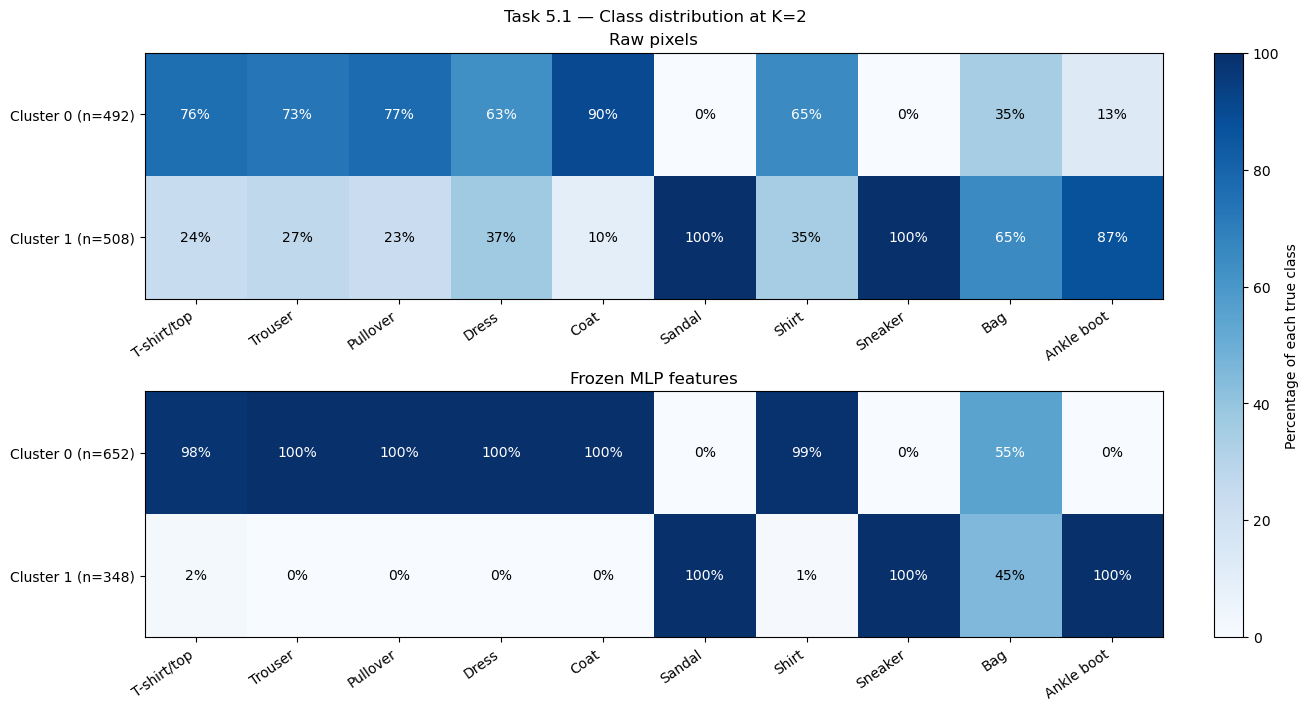

In [55]:
#plot ths comparison
#can be added to the top cell as one
fig, axes = plt.subplots(2, 1, figsize=(13, 7), layout="constrained")

for ax, name, percentages, counts in [(axes[0], "Raw pixels", raw_class_pct, raw_counts),
    (axes[1], "Frozen MLP features", mlp_class_pct, mlp_counts),]:
    im = ax.imshow(percentages.to_numpy(),cmap="Blues",vmin=0,
        vmax=100,aspect="auto",)

    ax.set_xticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=35, ha="right")
    ax.set_yticks(range(2))
    ax.set_yticklabels([f"Cluster {c} (n={int(counts.loc[c].sum())})" for c in range(2)])
    ax.set_title(name)

    for row in range(2):
        for col in range(len(class_names)):
            value = percentages.iloc[row, col]
            ax.text(col, row, f"{value:.0f}%",ha="center",va="center",
                color="white" if value > 50 else "black",)

fig.colorbar(im, ax=axes.tolist(),label="Percentage of each true class",)
fig.suptitle("Task 5.1 — Class distribution at K=2")
fig.savefig(part5_1_dir / "class_distribution.png",dpi=150,bbox_inches="tight",)
plt.show()

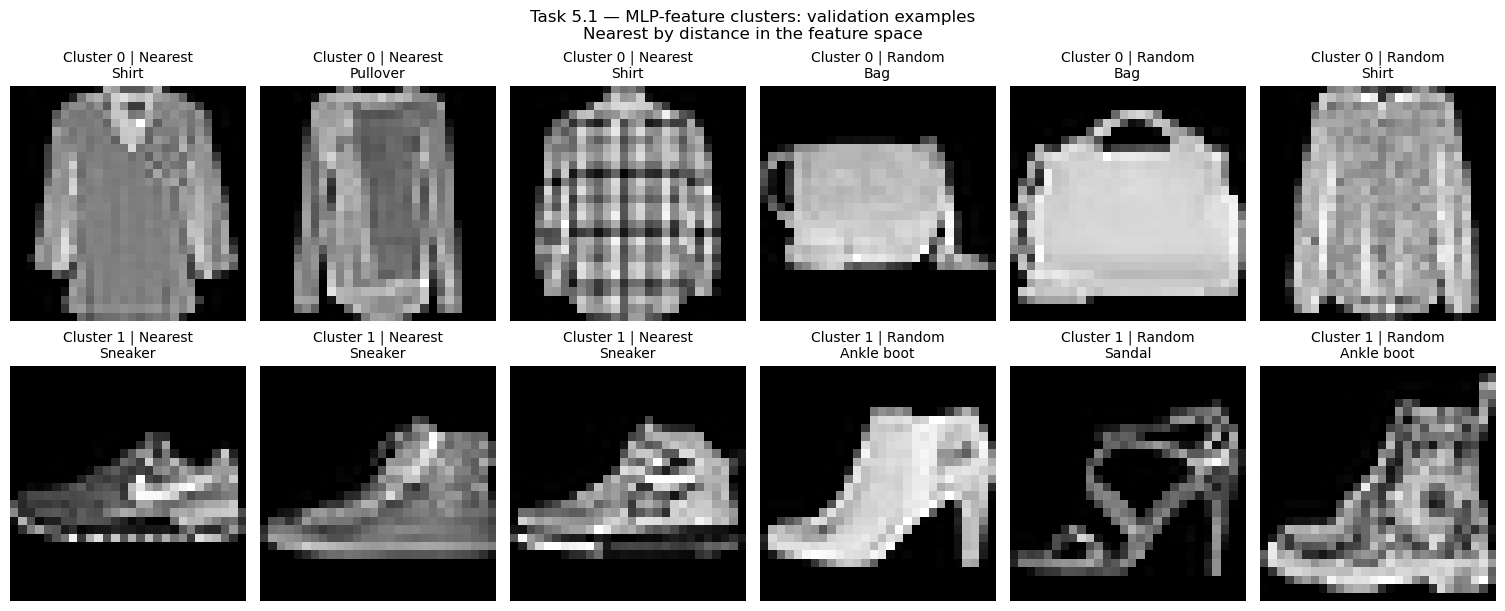

In [56]:
#checking examples from MCP-feature clusters
feature_distances = mlp_kmeans_selected.transform(mlp_val_features)
example_rng = np.random.default_rng(42)

fig, axes = plt.subplots(2, 6, figsize=(15, 6), layout="constrained")

for cluster in range(2):
    members = np.flatnonzero(mlp_assignments == cluster)
    nearest = members[np.argsort(feature_distances[members, cluster])[:3]]
    remaining = np.setdiff1d(members, nearest)
    random_members = example_rng.choice(remaining,size=min(3, len(remaining)),replace=False,)

    for ax in axes[cluster]:
        ax.axis("off")

    for start_column, positions, method in [(0, nearest, "Nearest"),(3, random_members, "Random"),]:
        for offset, pos in enumerate(positions):
            ax = axes[cluster, start_column + offset]

            # Display the exact image corresponding to this feature row.
            ax.imshow(raw_val[pos].reshape(28, 28),cmap="gray",vmin=0,vmax=1,)
            ax.set_title(f"Cluster {cluster} | {method}\n"
                f"{class_names[int(true_feature_val[pos])]}",fontsize=10,)

fig.suptitle("Task 5.1 — MLP-feature clusters: validation examples\n" "Nearest by distance in the feature space")
fig.savefig(part5_1_dir / "feature_cluster_examples.png",dpi=150,bbox_inches="tight",)
plt.show()

***** Part 5.1 - Interpretation / Analysis ******
* Changing the representation improved the separation at the same K=2. With raw pixels, the footwear-dominated cluster contained 287 footwear images and 156 body-clothing images. With MLP features, it contained all 300 footwear images and only three body-clothing images: two T-shirts/tops and one shirt.
*  There is also clearer class composition. Its increase from 0.1887 to 0.3360 makes the separation clear as as footwear versus body clothing.
* Bags is still divided between the clusters: 55 entered the clothing-dominated cluster and 45 entered the footwear-dominated cluster.
* The two clusters still do not identify the ten individual classes. Sandals, sneakers and ankle boots all share one cluster, while most body-clothing classes share the other. In particular, grouping shirts with coats and pullovers does not fix the Shirt classification confusions from Part 1.
* This improvement is from supervision. K-means did not see the classes, but the frozen MLP learned its representation through classes classification training. The comparison shows the effect of using these learned features; it does not show that an entirely unsupervised method discovered the same structure.
* So, I think representation and clustering assumptions both matter. Changing the representation improved the result without changing the K-means procedure. But K=2 provides a very fine grouping, and these results do not show the ten classes form compact, clearly separated groups in feature space.
* Cluster 0’s nearest examples are two shirts and a pullover. This means that the learned representation still groups different body-clothing classes together at K=2. The random examples include two bags and a shirt, confirming that this cluster is not only body clothing.
* Cluster 1’s three nearest examples are sneakers, while its random examples include ankle boots and a sandal. These images have different height, heel shape etc, but they joined the same footwear-dominated cluster. This is same with the class-composition results: all validation sandals, sneakers and ankle boots belong to this cluster.
* The clothing cluster still combines shirts and pullovers. So the generally improved broader grouping does not still show that the Shirt classification errors are fixed.
* short summary - Raw pixels versus frozen MLP features at \(K=2\). Both representations use the same 1,000 validation images and clustering settings. Each column sums to 100%. Learned features produce a clearer separation between body clothing and footwear, while bags remain distributed across both clusters. This demonstrates improved broad grouping, rather than recovery of the ten individual classes. Cluster IDs are arbitrary

In [57]:
#extracting featues from the same 200 images (combine with below cell?!)
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree

# Copy the exact ordered indices used in Part 4.4.
comparison_hierarchy_indices = np.asarray(hierarchy_indices, dtype=int).copy()

hierarchy_raw_pixels = (images[comparison_hierarchy_indices].astype(np.float32).reshape(200, -1) / 255.0)
hierarchy_mlp_features = extract_hidden_features(hierarchy_raw_pixels)

hierarchy_true_labels = np.asarray(classes)[comparison_hierarchy_indices]

print("Images:", len(comparison_hierarchy_indices))
print("Raw-pixel shape:", hierarchy_raw_pixels.shape)
print("MLP-feature shape:", hierarchy_mlp_features.shape)

Images: 200
Raw-pixel shape: (200, 784)
MLP-feature shape: (200, 256)



Raw pixels
Two-group sizes: [ 81 119]
Four-group sizes: [28 49 53 70]

MLP features
Two-group sizes: [ 56 144]
Four-group sizes: [56 36 35 73]


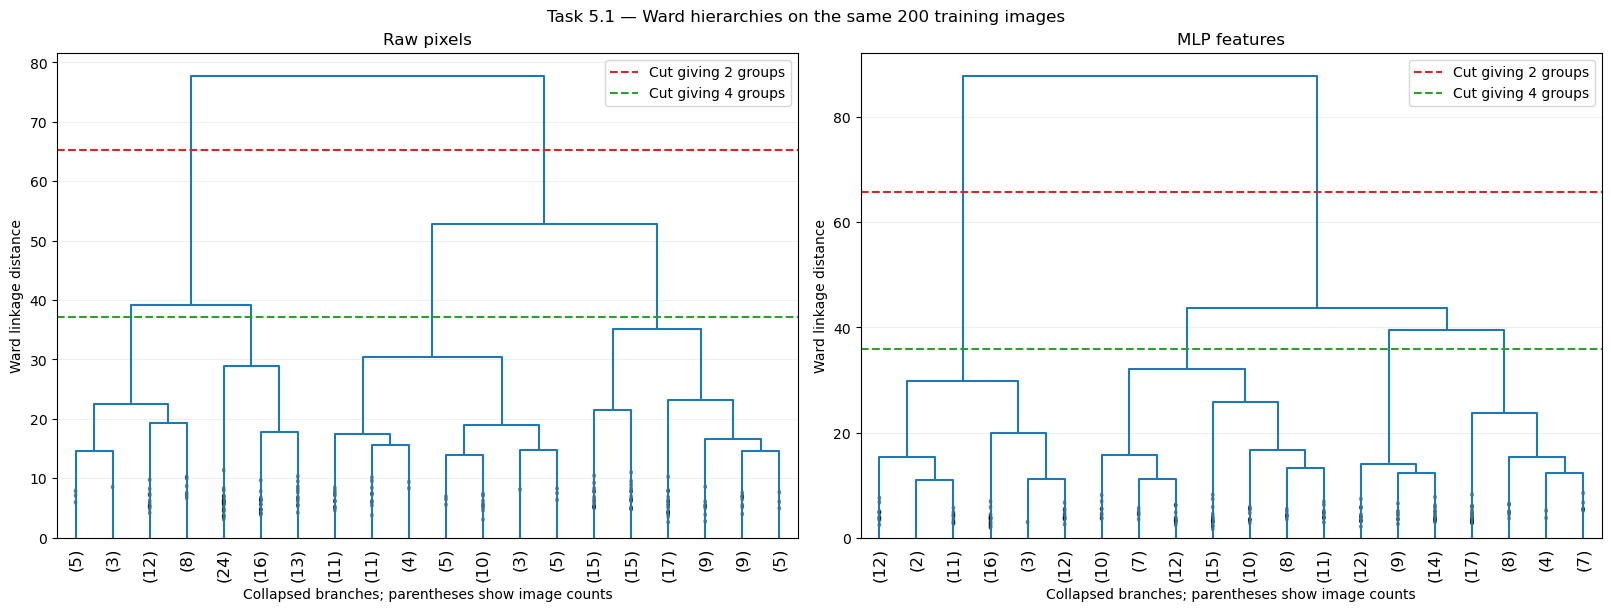

In [58]:
#recreating the raw-pixel hierarchy using the same pixel conversion from 4.4 above

hierarchy_representations = {"Raw pixels": (images[comparison_hierarchy_indices]
        .astype(np.float64).reshape(200, -1) / 255.0),
    "MLP features": hierarchy_mlp_features.astype(np.float64),}

comparison_linkages = {}
comparison_cuts = {}

for name, features in hierarchy_representations.items():
    linkage_matrix = linkage(features,method="ward",metric="euclidean",optimal_ordering=False,)
    comparison_linkages[name] = linkage_matrix
    comparison_cuts[name] = cut_tree(linkage_matrix, n_clusters=[2, 4])

    print(f"\n{name}")
    print("Two-group sizes:",np.bincount(comparison_cuts[name][:, 0]),)
    print("Four-group sizes:",np.bincount(comparison_cuts[name][:, 1]),)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), layout="constrained")

for ax, (name, linkage_matrix) in zip(axes, comparison_linkages.items()):
    dendrogram(
        linkage_matrix,
        truncate_mode="lastp",
        p=20,
        show_leaf_counts=True,
        show_contracted=True,
        color_threshold=0,
        above_threshold_color="tab:blue",
        ax=ax,
    )

    for k, colour in [(2, "tab:red"), (4, "tab:green")]:
        lower = linkage_matrix[-k, 2]
        upper = linkage_matrix[-(k - 1), 2]

        if lower < upper:
            ax.axhline(
                (lower + upper) / 2,
                color=colour,
                linestyle="--",
                label=f"Cut giving {k} groups",
            )

    ax.set_title(name)
    ax.set_xlabel("Collapsed branches; parentheses show image counts")
    ax.set_ylabel("Ward linkage distance")
    ax.tick_params(axis="x", labelrotation=90)
    ax.legend()
    ax.grid(axis="y", alpha=0.2)

fig.suptitle(
    "Task 5.1 — Ward hierarchies on the same 200 training images"
)
plt.show()


In [59]:
#comparing group composition
for name, cuts in comparison_cuts.items():
    for column, k in enumerate([2, 4]):
        groups = cuts[:, column]

        counts = pd.crosstab(
            pd.Series(groups, name="Group"),
            pd.Series(hierarchy_true_labels, name="Class"),).reindex(
            index=range(k),columns=range(len(class_names)),fill_value=0,)
        counts.columns = pd.Index(class_names, name="Class")
        composition_pct = counts.div(counts.sum(axis=1), axis=0) * 100

        counts.to_csv(part5_1_dir / f"class_counts_k{k}.csv")
        composition_pct.to_csv(part5_1_dir / f"composition_percent_k{k}.csv")

        print(f"\n{name}: class counts at {k} groups")
        print(counts.to_string())
        print(f"\n{name}: composition within each group (%)")
        print(composition_pct.round(1).to_string())

    print(f"\n{name}: four-group branches within two-group parents")
    print(pd.crosstab(
            pd.Series(cuts[:, 1], name="Four-group branch"),
            pd.Series(cuts[:, 0], name="Two-group parent"),).to_string())
    nested = pd.crosstab(
    pd.Series(groups_4, name="Four-group branch"),
    pd.Series(groups_2, name="Two-group parent"),)
    nested.to_csv(part5_1_dir/ "nested_groups.csv")



Raw pixels: class counts at 2 groups
Class  T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker  Bag  Ankle boot
Group                                                                                      
0                2        1         5      0     4      18      4       20    9          18
1               24       17        12     19    19       0     19        0    9           0

Raw pixels: composition within each group (%)
Class  T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker   Bag  Ankle boot
Group                                                                                       
0              2.5      1.2       6.2    0.0   4.9    22.2    4.9     24.7  11.1        22.2
1             20.2     14.3      10.1   16.0  16.0     0.0   16.0      0.0   7.6         0.0

Raw pixels: class counts at 4 groups
Class  T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker  Bag  Ankle boot
Group                                        

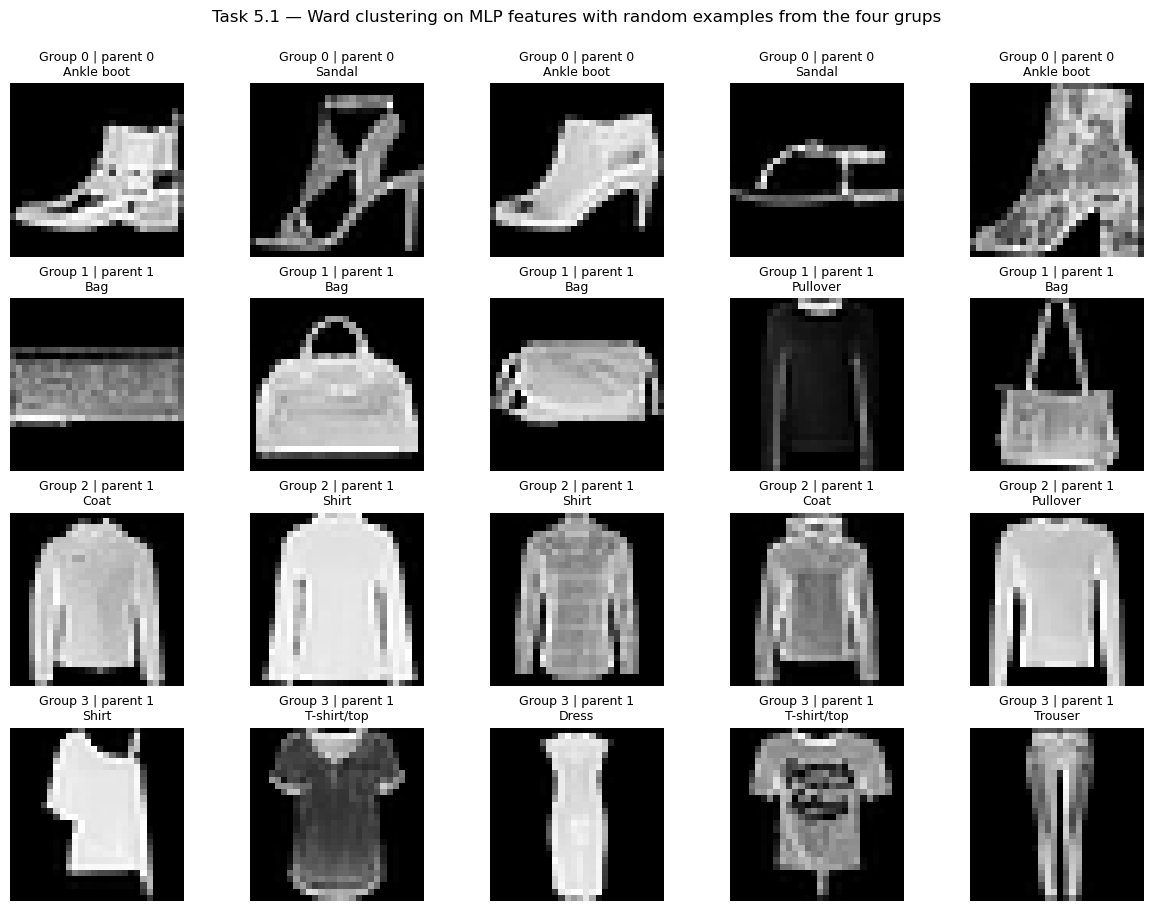

In [60]:
#now checking the images from this learned-feature hierarchy
mlp_hierarchy_groups_2 = comparison_cuts["MLP features"][:, 0]
mlp_hierarchy_groups_4 = comparison_cuts["MLP features"][:, 1]

example_rng = np.random.default_rng(42)
fig, axes = plt.subplots(4, 5, figsize=(12, 9), layout="constrained")
for group in range(4):
    members = np.flatnonzero(mlp_hierarchy_groups_4 == group)
    chosen = example_rng.choice(members, size=min(5, len(members)), replace=False)

    for ax in axes[group]:
        ax.axis("off")

    for column, pos in enumerate(chosen):
        ax = axes[group, column]
        # Use the same position for image, group and true label.
        ax.imshow(hierarchy_raw_pixels[pos].reshape(28, 28),cmap="gray",vmin=0,vmax=1,)
        parent = int(mlp_hierarchy_groups_2[pos])
        label = class_names[int(hierarchy_true_labels[pos])]
        ax.set_title(f"Group {group} | parent {parent}\n{label}",fontsize=9,)

fig.suptitle("Task 5.1 — Ward clustering on MLP features with random examples from the four grups\n")
fig.savefig(part5_1_dir / "ward_cluster_examples.png",dpi=150,bbox_inches="tight",)
plt.show()


***** Part 5.1 Hierarchy Interpretation ****
* At the two-group cut, MLP features now perfectly separated footwear from non-footwear within this 200-image sample. One group contained all 18 sandals, 20 sneakers and 18 ankle boots. The other contained all 144 remaining images. With raw pixels, the footwear-containing group also included 25 non-footwear images.
* the representation changed which subdivisions appeared first. At four groups, the learned-feature hierarchy retained footwear as one group and divided the non-footwear branch into groups of 36, 35 and 73 images. The raw-pixel hierarchy instead divided both broad branches into two subgroups. This shows a change in the hierarchy, not merely a change in cluster labels.
* Bags became more concentrated, but were not isolated. All 18 bags entered the same 36-image subgroup, alongside 18 garments. Therefore, this subgroup captured every bag in the sample, but only half its members were bags.
* Upper-body categories remained mixed. The 35-image subgroup contained 17 coats, ten shirts and eight pullovers. Their displayed examples share long sleeves and similar torso outlines. The larger 73-image subgroup mainly contained T-shirts/tops, dresses and trousers, but also included shirts and other garments.
* The examples support broad semantic grouping despite visual variation. The footwear group includes boots and sandals with different heights and heel shapes. However, the displayed random sample contains no sneakers even though the full group contains 20; interpretation must therefore use the tables as well as the images.
* These are training-subset findings. The MLP learned from labelled training data, and this hierarchy uses 200 training images. It illustrates the learned structure but does not independently demonstrate generalisation. The earlier K-means comparison on validation images provides evidence on held-out examples.
* With the images and clustering procedures fixed, replacing raw pixels with frozen MLP activations produced clearer broad clothing–footwear separation. Validation K-means silhouette increased from 0.1887 to 0.3360, and the composition tables showed substantially less mixing between these broad categories. Ward clustering on the fixed training sample also revealed a changed hierarchy and more concentrated bag membership. However, several labelled classes remained grouped together. These results show that representation matters, while neither good classification nor supervised feature learning guarantees ten compact, separate class clusters. The improvements involve supervision inherited from the MLP, even though the clustering algorithms themselves did not receive labels.

In [62]:
exp_frozen_mlp = { "id": "P5_1-FROZEN_MLP_FEATURES-01",
    "question": "Does replacing raw pixels with MLP features change clustering, stability and class composition?",
    "hypothesis": "Classification-trained features may improve broad grouping",
    "changed_variable": "Images: 784 scaled pixels versus 256 frozen post-ReLU hidden activations.",
    "fixed_conditions": (
        "Same images, K-search grid, K-means settings, seeds and selection "
        "rule. Main comparison at K=2. Ward uses the same 200 images, "
        "linkage and two-/four-group cuts."),
    "split":"K-means: 3,000 training and 1,000 validation images. Ward: fixed 200-image training subset.",
    "seed": ("mlp_training_seed: 42; kmeans_seeds: [42, 43, 44]; "
        f"selected_feature_kmeans_seed: {int(mlp_selected_seed)}; "
        "hierarchy_subset_seed: 42; example_sampling_seed: 42"),
    "configuration": ( f"checkpoint: {str(checkpoint_path)}; "
        f"checkpoint_epoch: {int(checkpoint["epoch"])}; "
        f"hidden_units: {int(checkpoint["width"])}; "
        f"training_dropout: {float(checkpoint["dropout"])}; "
        f"training_learning_rate: {float(checkpoint["lr"])}; "
        "training_epoch_budget: 500; extraction_point: After hidden ReLU, before dropout/output; "
        "frozen:eval mode; requires_grad=False; inference_mode "
        "feature_transformation: None; K_values: [2, 4, 6, 8, 10, 12, 15, 20]; "
        "search_init: k-means++; search_n_init: 10; max_iter: 300; tol: 1e-4; "
        "algorithm: lloyd; copy_x: True; stability_init: [random, k-means++]; "
        "stability_n_init: [1, 10]; main_comparison_K: 2; "
        "hierarchy: {method: Ward,metric:Euclidean,optimal_ordering:False,cuts: [2, 4]}"),
    "metric": "validation silhouette; pairwise assignment ARI across seeds; class composition; ",
    "result":("footwear_dominated_cluster:{ "
                "raw:{size: 508,footwear: 287,body_clothing: 156, bags: 65}; "
            "ward_interpretation:( "
            "All 56 footwear images form an unmixed branch. "
            "At four groups, the non-footwear branch splits into three. "
            "All 18 bags enter one 36-image subgroup); "
            "conclusion: Learned features improve broad clothing-footwear separation"),
    "output_path": (f"mlp_checkpoint: {str(checkpoint_path)}; "
        f"clustering_indices: {str(part4_dir / "used_indices.json")}" ),
}

register_path = Path("results/experiment_register.csv")
register_path.parent.mkdir(parents=True, exist_ok=True)
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_frozen_mlp])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

print(exp_frozen_mlp["result"])

footwear_dominated_cluster:{ raw:{size: 508,footwear: 287,body_clothing: 156, bags: 65}; ward_interpretation:( All 56 footwear images form an unmixed branch. At four groups, the non-footwear branch splits into three. All 18 bags enter one 36-image subgroup); conclusion: Learned features improve broad clothing-footwear separation


******** Part 5.2 - Route B : ensembling : My Approach plan ********
* This choice is simple and direct. I don't have to get or train any new models. I can ensemble the three dropout MLPs that I already trained with seeds 42, 43 and 44. This can then reuse my wrk from part 3, and assess whether combining these models reduces errors.
* Configuration
  * Models - Dropout MLPs, seeds 42, 43 and 44
  * Architecture - 784 → 256 → 10
  * Checkpoints	- same as selected in part 3
  * Prediction rule	- verage the three class-probability vectors
  * Weights - equal (i.e., 1/3 for each one)

In [66]:
#loading the three models from part-3
from time import perf_counter

ensemble_seeds = [42, 43, 44]
ensemble_models = {}
ensemble_checkpoint_records = []

for seed in ensemble_seeds:
    path = Path(f"results/part3/P3-w256-e500-l0.01-dropout-seed{seed}.pt")
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)

    model = RegularisedMLP(width=checkpoint["width"],dropout=checkpoint["dropout"],)
    model.load_state_dict(checkpoint["model_state"])
    model = model.to(device)
    model.eval()
    model.requires_grad_(False)

    ensemble_models[seed] = model
    ensemble_checkpoint_records.append({"seed": seed,"checkpoint": str(path),
        "selected_epoch": int(checkpoint["epoch"]),
        "parameters": sum(p.numel() for p in model.parameters()),
        "checkpoint_bytes": path.stat().st_size,})

ensemble_checkpoints = pd.DataFrame(ensemble_checkpoint_records)
print(ensemble_checkpoints.to_string(index=False))

#getting the validation probabilities
ensemble_val_pixels = (images[val_index].astype(np.float32).reshape(len(val_index), -1) / 255.0)
ensemble_val_targets = np.asarray(classes)[val_index]

def synchronise_device():
    if torch.device(device).type == "cuda":
        torch.cuda.synchronize(device)

@torch.inference_mode()
def predict_probabilities(model, pixels, batch_size=256):
    model.eval()
    outputs = []

    for start in range(0, len(pixels), batch_size):
        batch = torch.from_numpy(pixels[start:start + batch_size]).to(device)
        probabilities = torch.softmax(model(batch), dim=1)
        outputs.append(probabilities.cpu().numpy())
    return np.concatenate(outputs, axis=0)

member_val_probabilities = {}
member_val_seconds = {}

for seed, model in ensemble_models.items():
    # Small warm-up before timing.
    predict_probabilities(model, ensemble_val_pixels[:256])
    synchronise_device()
    start = perf_counter()
    probabilities = predict_probabilities(model, ensemble_val_pixels)
    synchronise_device()
    member_val_seconds[seed] = perf_counter() - start
    member_val_probabilities[seed] = probabilities

start = perf_counter()
ensemble_val_probabilities = np.mean(np.stack([member_val_probabilities[seed]
        for seed in ensemble_seeds]),axis=0,)
averaging_seconds = perf_counter() - start

ensemble_val_seconds = sum(member_val_seconds.values()) + averaging_seconds

 seed                                         checkpoint  selected_epoch  parameters  checkpoint_bytes
   42 results/part3/P3-w256-e500-l0.01-dropout-seed42.pt             451      203530            817249
   43 results/part3/P3-w256-e500-l0.01-dropout-seed43.pt             482      203530            817249
   44 results/part3/P3-w256-e500-l0.01-dropout-seed44.pt             497      203530            817249


In [69]:
#compare overall validation performance
from sklearn.metrics import accuracy_score, f1_score, log_loss

part5_2_dir = Path("results/part5_2")
part5_2_dir.mkdir(parents=True, exist_ok=True)

validation_probabilities = {f"MLP seed {seed}": member_val_probabilities[seed]
    for seed in ensemble_seeds}
validation_probabilities["Ensemble"] = ensemble_val_probabilities

validation_predictions = {}
validation_records = []

for name, probabilities in validation_probabilities.items():
    predictions = probabilities.argmax(axis=1)
    validation_predictions[name] = predictions

    if name == "Ensemble":
        seconds = ensemble_val_seconds
    else:
        seed = int(name.split()[-1])
        seconds = member_val_seconds[seed]

    validation_records.append({"model": name,"accuracy": accuracy_score(
            ensemble_val_targets, predictions),
        "macro_f1": f1_score(ensemble_val_targets,predictions,labels=range(len(class_names)),
            average="macro",zero_division=0,),
        "cross_entropy": log_loss(ensemble_val_targets,probabilities,labels=range(len(class_names)),),
        "errors": int(np.sum(predictions != ensemble_val_targets)),
        "prediction_seconds": seconds,})

ensemble_validation_summary = pd.DataFrame(validation_records)
ensemble_validation_summary.to_csv(part5_2_dir / "ensemble_validation.csv", index=False)
print(ensemble_validation_summary.round(4).to_string(index=False))

      model  accuracy  macro_f1  cross_entropy  errors  prediction_seconds
MLP seed 42    0.8759    0.8755         0.3540    1241              0.0242
MLP seed 43    0.8756    0.8749         0.3563    1244              0.0199
MLP seed 44    0.8757    0.8753         0.3561    1243              0.0194
   Ensemble    0.8756    0.8752         0.3483    1244              0.0645


In [72]:
#compare the effect at each class-level, there may also be new errors
from sklearn.metrics import precision_recall_fscore_support

class_records = []
for name, predictions in validation_predictions.items():
    precision, recall, f1, support = precision_recall_fscore_support(
        ensemble_val_targets,predictions,labels=range(len(class_names)),zero_division=0,)

    for class_id, class_name in enumerate(class_names):
        class_records.append({"model": name,"class": class_name,"precision": precision[class_id],
            "recall": recall[class_id],"f1": f1[class_id],"support": int(support[class_id]),})

ensemble_class_results = pd.DataFrame(class_records)
ensemble_class_results.to_csv(part5_2_dir / "validation_by_class.csv", index=False)

print("\nValidation recall by class")
print(ensemble_class_results.pivot(index="class", columns="model", values="recall"
    ).reindex(class_names).round(4).to_string())
print("\nValidation F1 by class")
print(ensemble_class_results.pivot(index="class", columns="model", values="f1"
    ).reindex(class_names).round(4).to_string())

ensemble_correct = (validation_predictions["Ensemble"] == ensemble_val_targets)

change_records = []

for seed in ensemble_seeds:
    member_correct = (validation_predictions[f"MLP seed {seed}"] == ensemble_val_targets)

    corrected = int(np.sum(~member_correct & ensemble_correct))
    introduced = int(np.sum(member_correct & ~ensemble_correct))

    change_records.append({ "compared_with": f"MLP seed {seed}","errors_corrected": corrected,
        "new_errors_introduced": introduced,"net_additional_correct": corrected - introduced,
        "accuracy_gain_pp": (100 * (corrected - introduced) / len(ensemble_val_targets)),})

ensemble_error_changes = pd.DataFrame(change_records)
ensemble_error_changes.to_csv(part5_2_dir / "error_changes.csv", index=False)

print("\nEnsemble corrections and new errors")
print(ensemble_error_changes.round(3).to_string(index=False))

single_parameters = int(ensemble_checkpoints.iloc[0]["parameters"])
total_parameters = int(ensemble_checkpoints["parameters"].sum())

print("\nResource cost")
print("Single-model parameters:", single_parameters)
print("Ensemble parameters:", total_parameters)
print("Forward passes per image: 1 for a member; 3 for the ensemble")
print("Additional training for this extension: none")
print("Combined checkpoint size:",
    f"{ensemble_checkpoints['checkpoint_bytes'].sum() / 1024**2:.2f} MiB")



Validation recall by class
model        Ensemble  MLP seed 42  MLP seed 43  MLP seed 44
class                                                       
T-shirt/top     0.847        0.843        0.857        0.843
Trouser         0.971        0.970        0.970        0.971
Pullover        0.808        0.808        0.809        0.808
Dress           0.882        0.888        0.888        0.878
Coat            0.791        0.789        0.798        0.802
Sandal          0.945        0.943        0.943        0.946
Shirt           0.667        0.666        0.651        0.672
Sneaker         0.926        0.935        0.929        0.916
Bag             0.958        0.958        0.955        0.957
Ankle boot      0.961        0.959        0.956        0.964

Validation F1 by class
model        Ensemble  MLP seed 42  MLP seed 43  MLP seed 44
class                                                       
T-shirt/top    0.8365       0.8347       0.8353       0.8342
Trouser        0.9764       0.975

****** Part 5.2 - Interim analysis **********
* Overall performance is not great: ensemble accuracy was 87.56%, compared with 87.59%, 87.56% and 87.57% for the member models. Its macro-F1 of 0.8752 is also in the member models range. Basically, there was no improvement in classification performance.
* Corrections versus new errors is almost the same: with seed 42, the ensemble corrected 85 errors but introduced 88, leaving three additional errors overall. This pattern is similar for other seeds
* Class-level effects were mixed: T-shirt/top and Bag F1 exceeded all three member models slightly, whereas Pullover and Coat F1 were below every member model. No single class-recall improvement was significant in the comparison.
* Shirt is difficult class: ensemble recall was 66.7%, within the member model's range of 65.1%–67.2%. The ensemble did not fix this persistent difficulty.
* Probability quality improved under cross-entropy: ensemble loss was 0.3483, below all individual losses. But this does not mean better calibration.
* Extra cost: the ensemble stored 610,590 parameters rather than 203,530 and required three forward passes per image. Its combined checkpoints occupied 2.34 MiB.
* Conclusion: for these checkpoints and validation images, equal-weight averaging improved cross-entropy but did not give any accuracy benefit despite the additional extra cost.
* I think its possible that the models sharing the architecture and training data may lead to these errors. So checking some validation examples to get additional clus/information.

Corrected by ensemble: 85 validation images
New error from ensemble: 88 validation images


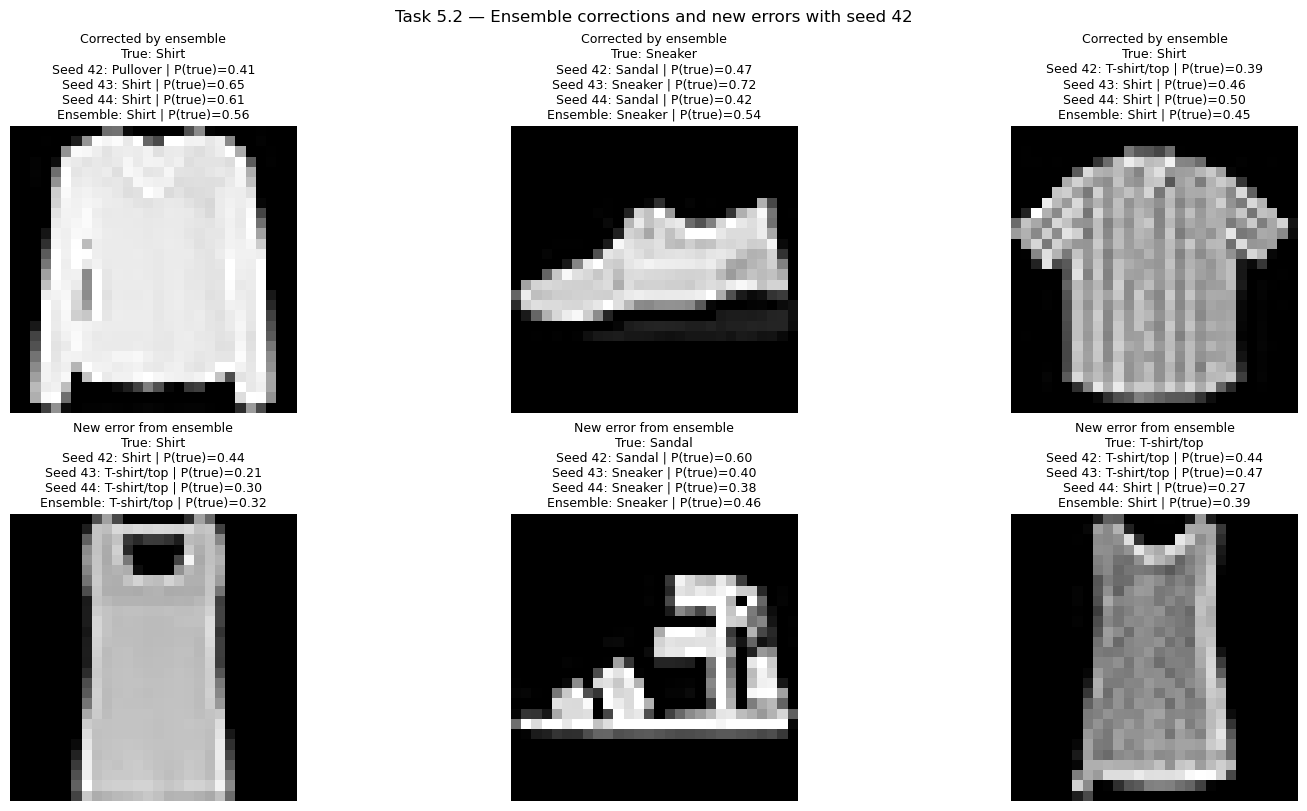

In [73]:
#checking out the correct and the newly added errors for information

reference_name = "MLP seed 42"
reference_predictions = validation_predictions[reference_name]
ensemble_predictions = validation_predictions["Ensemble"]

reference_correct = (reference_predictions == ensemble_val_targets)
ensemble_correct = (ensemble_predictions == ensemble_val_targets)

example_groups = [("Corrected by ensemble", ~reference_correct & ensemble_correct),
    ("New error from ensemble", reference_correct & ~ensemble_correct),]

rng = np.random.default_rng(42)
example_rows = []

fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")
for row, (outcome, mask) in enumerate(example_groups):
    positions = np.flatnonzero(mask)
    chosen = rng.choice(positions, size=min(3, len(positions)), replace=False)
    print(f"{outcome}: {len(positions)} validation images")

    for ax in axes[row]:
        ax.axis("off")
    for ax, pos in zip(axes[row], chosen):
        true_id = int(ensemble_val_targets[pos])
        ax.imshow(ensemble_val_pixels[pos].reshape(28, 28),cmap="gray",vmin=0,vmax=1,)
        prediction_lines = []
        for name, probabilities in validation_probabilities.items():
            predicted_id = int(probabilities[pos].argmax())
            p_true = float(probabilities[pos, true_id])

            short_name = name.replace("MLP seed ", "Seed ")
            prediction_lines.append(f"{short_name}: {class_names[predicted_id]}"
                f" | P(true)={p_true:.2f}")

            example_rows.append({"outcome": outcome,"validation_position": int(pos),
                "original_image_index": int(val_index[pos]),
                "true_class": class_names[true_id], "model": name,
                "predicted_class": class_names[predicted_id],
                "probability_true_class": p_true,
                "probability_predicted_class": float(probabilities[pos, predicted_id]),})

        ax.set_title(f"{outcome}\nTrue: {class_names[true_id]}\n"+ "\n".join(prediction_lines),fontsize=9,)

fig.suptitle("Task 5.2 — Ensemble corrections and new errors with seed 42")
fig.savefig(part5_2_dir / "ensemple_examples.png",dpi=150,bbox_inches="tight",)
plt.show()

ensemble_example_details = pd.DataFrame(example_rows)
ensemble_example_details.to_csv(part5_2_dir / "ensemble_examples.csv",index=False)

******* Part 5.2 - Interim analysis from the examples ******
* Corrected Shirt example, top left: seed 42 predicted Pullover, assigning Shirt a probability of 0.41. Seeds 43 and 44 assigned Shirt probabilities of 0.65 and 0.61. Averaging increased its probability to approximately 0.56, making Shirt the ensemble prediction.
* Corrected Sneaker example, top middle: two members predicted Sandal, but the ensemble correctly predicted Sneaker. Seed 43’s stronger support for Sneaker, combined with the other model's substantial Sneaker probabilities, produced an average of approximately 0.54. A majority vote would have selected Sandal.
* New Shirt error, bottom left: seed 42 correctly predicted Shirt, but averaging reduced the true-class probability from 0.44 to approximately 0.32. The ensemble instead selected T-shirt/top.
* New T-shirt/top error, bottom right: two members correctly predicted T-shirt/top, yet the ensemble predicted Shirt. Although T-shirt/top’s average probability was approximately 0.39, Shirt’s average was higher.
* Fundamentally, probability averaging can therefore overturn a correct majority as well as an incorrect one.
* These examples show the painfully persistent ambiguity between Shirt, T-shirt/top and Pullover, and between footwear categories.

In [74]:
#evaluate all three models and the ensemble on the official 10,000 image test set

#load the test set images
from torchvision.datasets import FashionMNIST

ensemble_test_dataset = FashionMNIST(root="./data",train=False,download=True,)
ensemble_test_pixels = (ensemble_test_dataset.data.numpy().astype(np.float32).reshape(-1, 784) / 255.0)
ensemble_test_targets = ensemble_test_dataset.targets.numpy()

assert len(ensemble_test_targets) == 10000
assert list(ensemble_test_dataset.classes) == list(class_names)

print("Test images:", len(ensemble_test_targets))
print("Input shape:", ensemble_test_pixels.shape)
print("Ensemble seeds:", ensemble_seeds)
print("Combination rule: equal-weight mean of class probabilities")

#generate test predictions
member_test_probabilities = {}
member_test_seconds = {}

for seed in ensemble_seeds:
    model = ensemble_models[seed]

    # Warm-up forward pass, without training or parameter updates.
    predict_probabilities(model, ensemble_test_pixels[:256])
    synchronise_device()
    start = perf_counter()
    probabilities = predict_probabilities(model, ensemble_test_pixels)
    synchronise_device()
    member_test_seconds[seed] = perf_counter() - start
    member_test_probabilities[seed] = probabilities

start = perf_counter()
ensemble_test_probabilities = np.mean(np.stack([member_test_probabilities[seed]
        for seed in ensemble_seeds]),axis=0,)
test_averaging_seconds = perf_counter() - start
ensemble_test_seconds = (sum(member_test_seconds.values()) + test_averaging_seconds)

test_probabilities = {f"MLP seed {seed}": member_test_probabilities[seed]
    for seed in ensemble_seeds}
test_probabilities["Ensemble"] = ensemble_test_probabilities

Test images: 10000
Input shape: (10000, 784)
Ensemble seeds: [42, 43, 44]
Combination rule: equal-weight mean of class probabilities


In [75]:
#overall test result and validation comparison
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, f1_score, log_loss

test_predictions = {}
test_records = []

for name, probabilities in test_probabilities.items():
    predictions = probabilities.argmax(axis=1)
    test_predictions[name] = predictions
    if name == "Ensemble":
        seconds = ensemble_test_seconds
    else:
        seed = int(name.split()[-1])
        seconds = member_test_seconds[seed]

    test_records.append({"model": name,"accuracy": accuracy_score(
            ensemble_test_targets, predictions),
        "macro_f1": f1_score(ensemble_test_targets,predictions,labels=range(len(class_names)),
            average="macro",zero_division=0,),
        "cross_entropy": log_loss(ensemble_test_targets,probabilities,
            labels=range(len(class_names)),),
        "errors": int(np.sum(predictions != ensemble_test_targets)),
        "prediction_seconds": seconds,})

ensemble_test_summary = pd.DataFrame(test_records)
ensemble_test_summary.to_csv(part5_2_dir / "ensemble_test.csv", index=False)
print("Final test results")
print(ensemble_test_summary.round(4).to_string(index=False))

validation_test_comparison = (ensemble_validation_summary[
        ["model", "accuracy", "macro_f1", "cross_entropy"]].merge(
        ensemble_test_summary[["model", "accuracy", "macro_f1", "cross_entropy"]],
        on="model",suffixes=("_validation", "_test"),validate="one_to_one",))

val_test_compare_summary = pd.DataFrame(validation_test_comparison)
val_test_compare_summary.to_csv(part5_2_dir / "val_test_comparision.csv", index=False)
print("\nValidation and test comparison")
print(validation_test_comparison.round(4).to_string(index=False))

#class-level test results and changed (e.g., corrected/new) errors
test_class_records = []

for name, predictions in test_predictions.items():
    precision, recall, f1, support = precision_recall_fscore_support(
        ensemble_test_targets,predictions,labels=range(len(class_names)),zero_division=0,)

    for class_id, class_name in enumerate(class_names):
        test_class_records.append({"model": name,"class": class_name,
            "precision": precision[class_id],"recall": recall[class_id],
            "f1": f1[class_id],"support": int(support[class_id]),})

ensemble_test_class_results = pd.DataFrame(test_class_records)
ensemble_test_class_results.to_csv(part5_2_dir / "ensemble_test_byclass.csv", index=False)

for metric in ["precision", "recall", "f1"]:
    print(f"\nTest {metric} by class")
    print(ensemble_test_class_results.pivot(index="class", columns="model", values=metric
        ).reindex(class_names).round(4).to_string())

ensemble_test_correct = (test_predictions["Ensemble"] == ensemble_test_targets)
test_change_records = []

for seed in ensemble_seeds:
    member_correct = (test_predictions[f"MLP seed {seed}"]== ensemble_test_targets)
    corrected = int(np.sum(~member_correct & ensemble_test_correct))
    introduced = int(np.sum(member_correct & ~ensemble_test_correct))

    test_change_records.append({"compared_with": f"MLP seed {seed}",
        "errors_corrected": corrected,"new_errors_introduced": introduced,
        "net_additional_correct": corrected - introduced,
        "accuracy_gain_pp": (100 * (corrected - introduced)/ len(ensemble_test_targets)),})

ensemble_test_error_changes = pd.DataFrame(test_change_records)
ensemble_test_error_changes.to_csv(part5_2_dir / "emsemble_test_errors.csv", index=False)
print("\nTest corrections and new errors")
print(ensemble_test_error_changes.round(3).to_string(index=False))

Final test results
      model  accuracy  macro_f1  cross_entropy  errors  prediction_seconds
MLP seed 42    0.8612    0.8603         0.4045    1388              0.0262
MLP seed 43    0.8600    0.8589         0.4049    1400              0.0268
MLP seed 44    0.8605    0.8601         0.4084    1395              0.0188
   Ensemble    0.8632    0.8624         0.3979    1368              0.0727

Validation and test comparison
      model  accuracy_validation  macro_f1_validation  cross_entropy_validation  accuracy_test  macro_f1_test  cross_entropy_test
MLP seed 42               0.8759               0.8755                    0.3540         0.8612         0.8603              0.4045
MLP seed 43               0.8756               0.8749                    0.3563         0.8600         0.8589              0.4049
MLP seed 44               0.8757               0.8753                    0.3561         0.8605         0.8601              0.4084
   Ensemble               0.8756               0.8752 

******** Part 5.2 - Interpretation / Analysis *******
* Overall test performance improved slightly - Ensemble accuracy was 86.32%, compared with 86.12%, 86.00% and 86.05% for the individual models. Macro-F1 increased to 0.8624, and cross-entropy fell to 0.3979, outperforming every model on these three test metrics.
* Corrections was better than new errors on the test set - Relative to seed 42 which was the strongest individual member on validation—the ensemble corrected 111 errors and introduced 91, giving 20 additional correct predictions, or 0.20 percentage. The gains over seeds 43 and 44 were 32 and 27 images.
* Class-level benefits were mixed - Ensemble F1 exceeded all models for T-shirt/top, Pullover, Coat, Shirt and Bag but not every model for the other five classes.
* Shirt is still the hardest class - Ensemble Shirt recall was 60.9%, only one additional correct shirt compared with seed 42, and below seed 44’s 61.2%. However, Shirt precision increased to 68.97%, exceeding every model, giving the highest Shirt F1 of 0.6468. The benefit was mainly better precision rather than significantly fewer missed shirts.
* Validation and test findings are different - On validation, the ensemble introduced three additional errors relative to seed 42; on test, it removed 20. This shows that a small gain can vary between samples. Cross-entropy improved on both splits. As you know, I did not change the  method after validation, so the test improvement was not from test-set tuning.
* All models performed worse on test than validation 0 Ensemble accuracy declined from 87.56% to 86.32%, a decrease of 1.24 percentage points. This is probably because of sample changes especially since I used validation-based model selection.
* The improvement had extra cost -  Ensemble required three forward passes and 610,590 stored parameters, compared with one pass and 203,530 parameters per model. Test prediction took approximately 0.0727 seconds, versus 0.0262 seconds for seed 42, that's aout 2.8 times longer.
* Conclusion: equal-weight probability averaging improved cross-entropy on both splits and produced a small test accuracy gain. For this experiment, the benefit is not a lot compared to the extra cost. But one ensemble on one test set does not confirm that the gain will reliably repeat.

******** Part 5.2 - Comparison of the  three routes ********
* Frozen pre-trained features - the approach is: reusing an externally trained encoder without updating it	- the extra resources will be: external training knowledge, checkpoint storage and feature-extraction computation
* Ensembling — the approach is: to use average predictions from existing models - the extra resources are: multiple trained models, storage and forward passes (as I just summaarised above)
* Test-time augmentation - the approach is: to use average predictions over transformed views of an image - the extra resources will be: additional input transformations and forward passes

*********** Part 5.2 - Under a fixed budget, what would you investigate next, and why? *********
* Under a budget allowing approximately three forward passes per image but no additional training, I would investigate test-time augmentation next, i.e. , one model could process the original image and two small, fixed translations, reducing model storage compared with this ensemble
* My hypothesis would be that sensitivity to image position contributes to some errors. I would select the transformation policy using validation data and compare class-level effects and runtime against the unaugmented model.
* from this I can evaluate if test-time augmentation could outperform ensembling or the pre-trained features.